In [1]:
## Plot seizures graf 17/02/2026

import pyedflib
import pandas as pd
import os
from matplotlib import pyplot as plt
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages

# import ipywidgets as widgets
# from IPython.display import display
# from IPython.display import clear_output
# from IPython.display import display, Markdown

- Rajouter méthode get_data_acc
- Rajouter méthode get_data_ecg

In [2]:
# Download datas and preprocessing
bdd = pd.read_csv("/home/aura-fabien/SizeIT/Datas/bdd_SizeIt.csv",index_col = 0)
l_sz_type = list(set(bdd['eventType']))
l_sz_type = [i for i in l_sz_type if i not in ['bckg','impd']]
bdd = bdd[bdd.eventType.isin(l_sz_type)]

In [5]:
# Fonctions et sz descriptions

def get_df_one_sz_type(sz_type,bdd = bdd):
    loc_bdd = bdd[bdd["eventType"]==sz_type]
    return loc_bdd


def get_df_acc(path_edf_acc):
    edf = pyedflib.EdfReader(path_edf_acc)
    start_datetime = edf.getStartdatetime()
    fs = edf.getSampleFrequency(0)
    n_samples = edf.getNSamples()[0]
    time = pd.date_range(
        start=start_datetime,
        periods=n_samples,
        freq=pd.to_timedelta(1/fs, unit="s")
    )
    data = {"time": time}

    for i, label in enumerate(edf.getSignalLabels()):
        data[label] = edf.readSignal(i)

    edf.close()

    df_data_acc = pd.DataFrame(data)
    df_data_acc["time_s"] = (df_data_acc["time"] - df_data_acc["time"].iloc[0]).dt.total_seconds()
    return df_data_acc

def get_df_ecg(path_edf_ecg):
    edf = pyedflib.EdfReader(path_edf_ecg)
    start_datetime = edf.getStartdatetime()
    fs = edf.getSampleFrequency(0)
    n_samples = edf.getNSamples()[0]
    time = pd.date_range(
        start=start_datetime,
        periods=n_samples,
        freq=pd.to_timedelta(1/fs, unit="s")
    )
    data = {"time": time}

    for i, label in enumerate(edf.getSignalLabels()):
        data[label] = edf.readSignal(i)

    edf.close()

    df_data_ecg = pd.DataFrame(data)
    df_data_ecg["time_s"] = (df_data_ecg["time"] - df_data_ecg["time"].iloc[0]).dt.total_seconds()
    return df_data_ecg

# Ok 
def get_df_sz(df_data,t0,sz_duration,overlap_sec):
    df_sz = df_data[(df_data["time_s"]>(t0 - overlap_sec)) & 
    (df_data["time_s"]<(t0 + sz_duration + overlap_sec))]
    return df_sz

def plot_graf_acc(ax,df,overlap_sec,obj_sz):
    df["norme"] = np.linalg.norm(df[['EEG SD ACC X', 'EEG SD ACC Y', 'EEG SD ACC Z']].values, axis=1)
    df.plot(x="time_s", y=['EEG SD ACC X', 'EEG SD ACC Y', 'EEG SD ACC Z','norme'], ax=ax)
    ax.axvline(x=df["time_s"].iloc[0] + overlap_sec, color="red", linestyle="--",linewidth=3)
    ax.axvline(x=df["time_s"].iloc[-1] - overlap_sec, color="red", linestyle="--",linewidth=3)
    ax.set_title(f"Seizure type : {obj_sz.sz_type}, durée = {obj_sz.duree}")  
    # ax.set_xlabel("Temps (s)")                 
    # ax.set_ylabel("Amplitude")                 
    plt.grid(True)                             

def plot_graf_ecg(ax,df):
    df.plot(x="time_s", y=['ECG SD'], ax = ax)
    ax.set_xlabel("")     
    plt.grid(True)    

def get_dict_sz():
    
    dict_evt_type = dict({
    "Description": "Description of the event",
    "Type": "object",
    "Levels": {
    "bckg": "Refers to an epoch of data that does not contain an epileptic seizure.",
    "impd": "Refers to an epoch of data that was recorded during an impedance control check (likely to be artifactual)",
    "sz": "Referring to a seizure type that cannot be described by the ILAE 2017 classification either because of inadequate information or unusual clinical features.",
    "sz_foc": "Focal seizure with unknown or unreported awareness",
    "sz_foc_a": "Focal aware seizure",
    "sz_foc_a_m": "Focal aware motor seizure",
    "sz_foc_a_m_automatisms": "Focal aware motor seizure with automatisms (more or less coordinated, purposeless, repetitive motor activity)",
    "sz_foc_a_m_atonic": "Focal aware motor seizure with atonic activity (focal loss of tone)",
    "sz_foc_a_m_clonic": "Focal aware motor seizure with clonic activity (focal rhythmic jerking)",
    "sz_foc_a_m_spasms": "Focal aware motor seizure with spasms",
    "sz_foc_a_m_hyperkinetic": "Focal aware motor seizure with hyperkinetic activity (pedaling, thrashing)",
    "sz_foc_a_m_myoclonic": "Focal aware motor seizure with myoclonic activity (irregular, brief focal jerking)",
    "sz_foc_a_m_tonic": "Focal aware motor seizure with tonic activity (sustained focal stiffening)",
    "sz_foc_a_nm": "Focal aware non-motor seizure",
    "sz_foc_a_nm_autonomic": "Focal aware non-motor seizure with autonomic effects such as gastrointestinal sensations, a sense of heat or cold, flushing, piloerection (goosebumps), palpitations, sexual arousal, respiratory changes, or other autonomic effects",
    "sz_foc_a_nm_behavior": "Focal aware non-motor seizure with behavior arrest involving cessation of movement and unresponsiveness as the predominant aspect of the entire seizure.",
    "sz_foc_a_nm_cognitive": "Focal aware non-motor seizure with cognitive disfunction such as deficits in language, thinking or associated higher cortical functions",
    "sz_foc_a_nm_emotional": "Focal aware non-motor seizure with emotional arrest",
    "sz_foc_a_nm_sensory": "Focal aware non-motor seizure with somatosensory, olfactory, visual, auditory, gustatory, hot–cold sense, or vestibular sensations",
    "sz_foc_a_um": "Focal aware seizure with unknown or unreported motor clinical features",
    "sz_foc_ia": "Focal impaired-awareness seizure",
    "sz_foc_ia_m": "Focal impaired-awareness motor seizure",
    "sz_foc_ia_m_automatisms": "Focal impaired-awareness motor seizure with automatisms (more or less coordinated, purposeless, repetitive motor activity)",
    "sz_foc_ia_m_atonic": "Focal impaired-awareness motor seizure with atonic activity (focal loss of tone)",
    "sz_foc_ia_m_clonic": "Focal impaired-awareness motor seizure with clonic activity (focal rhythmic jerking)",
    "sz_foc_ia_m_spasms": "Focal impaired-awareness motor seizure with spasms",
    "sz_foc_ia_m_hyperkinetic": "Focal impaired-awareness motor seizure with hyperkinetic activity (pedaling, thrashing)",
    "sz_foc_ia_m_myoclonic": "Focal impaired-awareness motor seizure with myoclonic activity (irregular, brief focal jerking)",
    "sz_foc_ia_m_tonic": "Focal impaired-awareness motor seizure with tonic activity (sustained focal stiffening)",
    "sz_foc_ia_nm": "Focal impaired-awareness non-motor seizure",
    "sz_foc_ia_nm_autonomic": "Focal impaired-awareness non-motor seizure with autonomic effects such as gastrointestinal sensations, a sense of heat or cold, flushing, piloerection (goosebumps), palpitations, sexual arousal, respiratory changes, or other autonomic effects",
    "sz_foc_ia_nm_behavior": "Focal impaired-awareness non-motor seizure with behavior arrest involving cessation of movement and unresponsiveness as the predominant aspect of the entire seizure.",
    "sz_foc_ia_nm_cognitive": "Focal impaired-awareness non-motor seizure with cognitive disfunction such as deficits in language, thinking or associated higher cortical functions",
    "sz_foc_ia_nm_emotional": "Focal impaired-awareness non-motor seizure with emotional arrest",
    "sz_foc_ia_nm_sensory": "Focal impaired-awareness non-motor seizure with somatosensory, olfactory, visual, auditory, gustatory, hot–cold sense, or vestibular sensations",
    "sz_foc_ia_um": "Focal impaired-awareness seizure with unknown or unreported motor clinical features",
    "sz_foc_ua_m": "Focal unknown-awareness motor seizure",
    "sz_foc_ua_m_automatisms": "Focal unknown-awareness motor seizure with automatisms (more or less coordinated, purposeless, repetitive motor activity)",
    "sz_foc_ua_m_atonic": "Focal unknown-awareness motor seizure with atonic activity (focal loss of tone)",
    "sz_foc_ua_m_clonic": "Focal unknown-awareness motor seizure with clonic activity (focal rhythmic jerking)",
    "sz_foc_ua_m_spasms": "Focal unknown-awareness motor seizure with spasms",
    "sz_foc_ua_m_hyperkinetic": "Focal unknown-awareness motor seizure with hyperkinetic activity (pedaling, thrashing)",
    "sz_foc_ua_m_myoclonic": "Focal unknown-awareness motor seizure with myoclonic activity (irregular, brief focal jerking)",
    "sz_foc_ua_m_tonic": "Focal unknown-awareness motor seizure with tonic activity (sustained focal stiffening)",
    "sz_foc_ua_nm": "Focal unknown-awareness non-motor seizure",
    "sz_foc_ua_nm_autonomic": "Focal unknown-awareness non-motor seizure with autonomic effects such as gastrointestinal sensations, a sense of heat or cold, flushing, piloerection (goosebumps), palpitations, sexual arousal, respiratory changes, or other autonomic effects",
    "sz_foc_ua_nm_behavior": "Focal unknown-awareness non-motor seizure with behavior arrest involving cessation of movement and unresponsiveness as the predominant aspect of the entire seizure.",
    "sz_foc_ua_nm_cognitive": "Focal unknown-awareness non-motor seizure with cognitive disfunction such as deficits in language, thinking or associated higher cortical functions",
    "sz_foc_ua_nm_emotional": "Focal unknown-awareness non-motor seizure with emotional arrest",
    "sz_foc_ua_nm_sensory": "Focal unknown-awareness non-motor seizure with somatosensory, olfactory, visual, auditory, gustatory, hot–cold sense, or vestibular sensations",
    "sz_foc_ua_um": "Focal unknown-awareness seizure with unknown or unreported motor clinical features",
    "sz_foc_f2b": "Focal onset seizure that propagates to a bilateral tonic–clonic seizure",
    "sz_gen": "Generalized seizure",
    "sz_gen_m": "Generalized seizure with motor activity",
    "sz_gen_m_tonicClonic": "Generalized tonic-clonic seizure",
    "sz_gen_m_clonic": "Generalized clonic seizure (begin, progress, and end with sustained rhythmic jerking of limbs on both sides of the body and often head, neck, face, and trunk)",
    "sz_gen_m_tonic": "Generalized tonic seizure (bilateral limb stiffening or elevation, often with neck stiffening). The classification presumes that the tonic activity is not followed by clonic movements.",
    "sz_gen_m_myoTC": "Generalized myoclonic–tonic–clonic seizure (begin with a few myoclonic jerks followed by tonic–clonic activity)",
    "sz_gen_m_myoAtonic": "Generalized myoclonic–atonic seizure (brief jerking of limbs or trunk, followed by a limp drop)",
    "sz_gen_m_atonic": "Generalized atonic seizure",
    "sz_gen_m_spasms": "Generalized seizure with spasms",
    "sz_gen_nm": "Generalized seizure with no motor activity (varieties of absence seizures)",
    "sz_gen_nm_typical": "Typical absence seizure",
    "sz_gen_nm_atypical": "Atypical absence seizure (associated with changes in tone that are more pronounced than in typical absence or the onset or cessation is not abrupt)",
    "sz_gen_nm_myoclonic": "Myoclonic absence seizure (rhythmic three-per-second myoclonic movements)",
    "sz_gen_nm_eyelidMyio": "Absence seizure with eyelid myoclonia (myoclonic jerks of the eyelids and upward deviation of the eyes, often precipitated by closing the eyes or by light)",
    "sz_uo": "Seizure with unknown or unreported onset",
    "sz_uo_m": "Motor seizure with unknown or unreported onset",
    "sz_uo_m_myoclonic": "Myoclonic (irregular, brief focal jerking) seizure with unknown or unreported onset",
    "sz_uo_m_tonicClonic": "Tonic-clonic seizure with unknown or unreported onset",
    "sz_uo_m_tonicMyio": "Tonic-myoclonic seizure with unknown or unreported onset",
    "sz_uo_m_hyperkinetic": "Motor seizure with unknown or unreported onset with hyperkinetic activity (pedaling, thrashing)",
    "sz_uo_m_spasms": "Seizure with unknown or unreported onset with spasms",
    "sz_uo_nm": "Non-motor seizure with unknown or unreported onset",
    "sz_uo_nm_behavior": "Non-motor seizure with behavioural activity and unknown or unreported onset"
    }})
    
    return dict_evt_type


dict_evt_type = get_dict_sz()

# Preprocesing objects for display 
l_patient = list(set(bdd.patient))
dict_pat_to_sz = dict()
for patient in l_patient:
    df_patient = bdd.loc[bdd.patient == patient]
    dict_pat_to_sz[patient] = list(set(df_patient.eventType))

In [6]:
# Class Seizure + class Patiet + add column object seizure

class Seizure:
    
    def __init__(self, path_acc, path_ecg, debut, duree,sz_type):
        self.path_acc = path_acc
        self.path_ecg = path_ecg
        self.debut = debut
        self.duree = duree
        self.fin = debut + duree
        self.sz_type = sz_type
    
    def __repr__(self):
        return (f"Seizure(path_acc={self.path_acc}, "
                f"path_ecg={self.path_ecg}, "
                f"debut={self.debut}, "
                f"duree={self.duree})")
    
    ''' 
    Je mets les datas en méthodes pour as surcharger,
    cela se fait au détriment de la vitesse d'affichage, 
    on peut le modifier
    '''
    
    def get_data_acc(self):
        data_acc = get_df_acc(self.path_acc)
        return data_acc

    def get_data_ecg(self):
        data_ecg = get_df_ecg(self.path_ecg)
        return data_ecg


bdd["obj_seizure"] = bdd.apply(
    lambda row: Seizure(
        path_acc=row["adresse_acc"],
        path_ecg=row["adresse_ecg"],
        debut=row["onset"],
        duree=row["duration"],
        sz_type=row["eventType"]
    ),
    axis=1
)

class Patient:

    def __init__(self, no_patient):
        self.no_patient = no_patient
        self.bdd = bdd[bdd.patient == self.no_patient]
        self.nb_sz = len(self.bdd)
        self.l_sz_type = list(set(self.bdd['eventType']))
        self.duration_mean = np.mean(self.bdd.duration)

### Graph Seizures by type

- Menu déroulant par patient
- Menu déroulant par type de crises du patient à partir d'un dictionnaire
- Rajouter en haut dans le titre :
    - Moyenne durée des crises de ce patient
    - Nombre de crise de ce patient 
    - Type des crises de ce patient. 

Dropdown(description='Patient:', options=(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 2…

Dropdown(description='Crise:', options=('sz_foc_a_m_automatisms', 'sz_foc_ia_m_tonic', 'sz_foc_ia_nm', 'sz_foc…

Output()

### Export patient SZ to pdf

In [7]:
def pdf_plot_graf_acc(ax,df,overlap_sec,obj_sz):
    try:
        df["norme"] = np.linalg.norm(df[['EEG SD ACC X', 'EEG SD ACC Y', 'EEG SD ACC Z']].values, axis=1)
        df.plot(x="time_s", y=['EEG SD ACC X', 'EEG SD ACC Y', 'EEG SD ACC Z','norme'], ax=ax)
    except:
        df["norme"] = np.linalg.norm(df[['ECGEMG SD ACC X', 'ECGEMG SD ACC Y', 'ECGEMG SD ACC Z']].values, axis=1)
        df.plot(x="time_s", y=['ECGEMG SD ACC X', 'ECGEMG SD ACC Y', 'ECGEMG SD ACC Z','norme'], ax=ax)
    ax.axvline(x=df["time_s"].iloc[0] + overlap_sec, color="red", linestyle="--",linewidth=3)
    ax.axvline(x=df["time_s"].iloc[-1] - overlap_sec, color="red", linestyle="--",linewidth=3)
    ax.set_title(f"Seizure type : {obj_sz.sz_type}, durée = {obj_sz.duree}")  
    # ax.set_xlabel("Temps (s)")                 
    # ax.set_ylabel("Amplitude")                 
    plt.grid(True)                             

def pdf_plot_graf_ecg(ax,df):

    df.plot(x="time_s", y=['ECG SD'], ax = ax)
    ax.set_xlabel("")     
    plt.grid(True)

In [8]:
# ## export to pdf 
# plt.rcParams["text.usetex"] = False
# l_patients = bdd.patient.unique().tolist()
# l_patients.sort()
# path_patient_pdf = '/home/aura-fabien/SizeIT/Datas/Seizure_images/'

# with PdfPages(path_patient_pdf) as pdf:

#     for patient in l_patients[0:2]: 
#         print('patient = ',patient)
#         # =========================
#         # PAGE 1 : PAGE TEXTE
#         # =========================

#         obj_patient = Patient(patient)
#         nb_sz = obj_patient.nb_sz

#         str_sz_type = ", ".join(obj_patient.l_sz_type)        
#         str_sz_type_multiligne = str_sz_type.replace(", ", "\n")
#         overlap = 10

#         fig_text = plt.figure(figsize=(12, 14))
#         fig_text.patch.set_facecolor("white")

#         fig_text.text(
#             0.5, 0.75,
#             f"RAPPORT PATIENT {patient}",
#             ha="center",
#             fontsize=24,
#             weight="bold"
#         )

#         fig_text.text(
#             0.1, 0.60,
#             f"Nombre de crises enregistrées : {nb_sz}\n\n"
#             f"Durée moyenne des crises : {obj_patient.duration_mean:.1f} s\n\n"
#             f"Types de crises : {str_sz_type_multiligne}",
#             fontsize=18
#         )

#         pdf.savefig(fig_text)
#         plt.close(fig_text)

#         for no_sz in range(nb_sz):
#             try:
#                 fig, axes = plt.subplots(2 , 1)
#                 # axes = axes.flatten()
#                 SZ = obj_patient.bdd["obj_seizure"].iloc[no_sz]
#                 df_data_acc = SZ.get_data_acc() # get_df_acc(SZ.path_acc)
#                 df_data_ecg = SZ.get_data_ecg() # get_df_ecg(SZ.path_ecg)
#                 df_graf_acc = get_df_sz(df_data_acc,SZ.debut,SZ.duree,overlap)
#                 df_graf_ecg = get_df_sz(df_data_ecg,SZ.debut,SZ.duree,overlap)
#                 pdf_plot_graf_acc(axes[0], df_graf_acc,10,SZ)
#                 pdf_plot_graf_ecg(axes[1], df_graf_ecg)

#                 fig.set_size_inches(12, 14)

#                 fig.text(
#                     0.02, 0.95,
#                     f"Patient: {patient}\n"
#                     f"Crises enregistrées: {nb_sz}\n"
#                     f"Crise no : {no_sz}"
#                     f"Durée moyenne: {obj_patient.duration_mean:.1f} s\n"
#                     f"Type de crises: {SZ.sz_type}",
#                     ha="left", va="top", fontsize=16,
#                     bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.3")
#                 )
#                 pdf.savefig(fig,facecolor="white")
#                 plt.close(fig)
#             except:
#                 continue
        
#             pdf_save_path = path_patient_pdf + f"Patient_{patient}_all_sz.pdf"
#             plt.savefig(pdf_save_path, format="pdf")
#             plt.savefig('/data/seize-it-analysis/' + f"Patient_{patient}_all_sz.pdf", format="pdf")
#             # plt.close(fig);
# # plt.show() /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_1_all_sz.pdfPatient_1_all_sz.pdf

PDF sauvegardé pour le patient 1 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_1_all_sz.pdf
PDF sauvegardé pour le patient 2 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_2_all_sz.pdf
PDF sauvegardé pour le patient 3 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_3_all_sz.pdf
PDF sauvegardé pour le patient 4 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_4_all_sz.pdf
PDF sauvegardé pour le patient 5 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_5_all_sz.pdf
PDF sauvegardé pour le patient 6 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_6_all_sz.pdf
PDF sauvegardé pour le patient 7 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_7_all_sz.pdf
PDF sauvegardé pour le patient 8 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_8_all_sz.pdf
PDF sauvegardé pour le patient 9 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_9_all_sz.pdf
PDF sauvegardé pour le patient 10 : /home/aura-fabien/SizeIT/Datas/Seizure_images/

/tmp/ipykernel_1971914/1145826297.py:22: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig_text = plt.figure(figsize=(12, 14))
/tmp/ipykernel_1971914/1145826297.py:49: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(2, 1, figsize=(12, 14))


PDF sauvegardé pour le patient 83 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_83_all_sz.pdf


/tmp/ipykernel_1971914/1145826297.py:22: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig_text = plt.figure(figsize=(12, 14))
/tmp/ipykernel_1971914/1145826297.py:49: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(2, 1, figsize=(12, 14))
/tmp/ipykernel_1971914/1145826297.py:49: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly

PDF sauvegardé pour le patient 84 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_84_all_sz.pdf


/tmp/ipykernel_1971914/1145826297.py:22: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig_text = plt.figure(figsize=(12, 14))
/tmp/ipykernel_1971914/1145826297.py:49: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(2, 1, figsize=(12, 14))
/tmp/ipykernel_1971914/1145826297.py:49: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly

PDF sauvegardé pour le patient 85 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_85_all_sz.pdf


/tmp/ipykernel_1971914/1145826297.py:49: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(2, 1, figsize=(12, 14))
/tmp/ipykernel_1971914/1145826297.py:49: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(2, 1, figsize=(12, 14))
/tmp/ipykernel_1971914/1145826297.py:49: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until e

PDF sauvegardé pour le patient 86 : /home/aura-fabien/SizeIT/Datas/Seizure_images/Patient_86_all_sz.pdf
Erreur crise 0 : /data2/datasets/seizeit2-dataset/ds005873-1.1.0/sub-087/ses-01/mov/sub-087_ses-01_task-szMonitoring_run-01_mov.edf: can not open file, no such file or directory, patient : 87
Erreur crise 1 : /data2/datasets/seizeit2-dataset/ds005873-1.1.0/sub-087/ses-01/mov/sub-087_ses-01_task-szMonitoring_run-02_mov.edf: can not open file, no such file or directory, patient : 87
Erreur crise 2 : /data2/datasets/seizeit2-dataset/ds005873-1.1.0/sub-087/ses-01/mov/sub-087_ses-01_task-szMonitoring_run-02_mov.edf: can not open file, no such file or directory, patient : 87
Erreur crise 3 : /data2/datasets/seizeit2-dataset/ds005873-1.1.0/sub-087/ses-01/mov/sub-087_ses-01_task-szMonitoring_run-03_mov.edf: can not open file, no such file or directory, patient : 87
Erreur crise 4 : /data2/datasets/seizeit2-dataset/ds005873-1.1.0/sub-087/ses-01/mov/sub-087_ses-01_task-szMonitoring_run-04_mov.

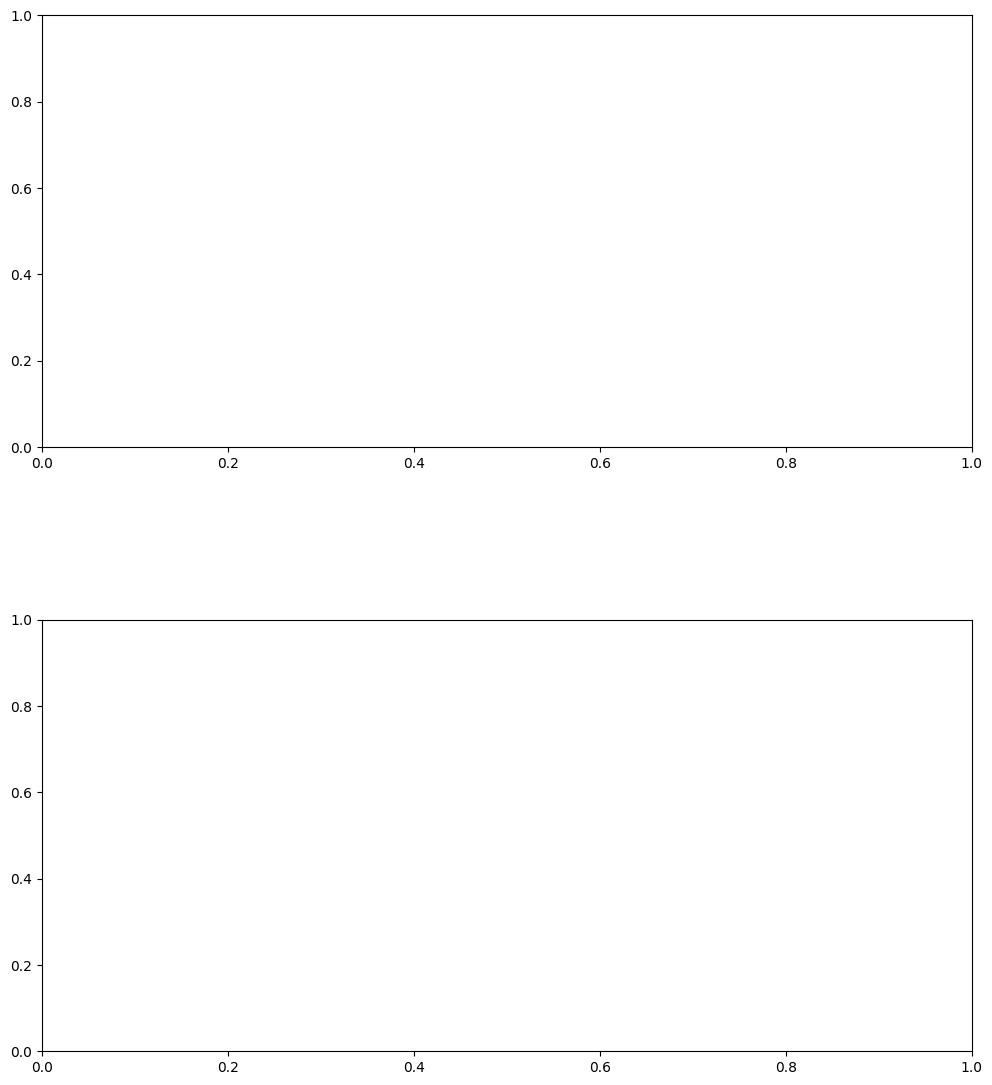

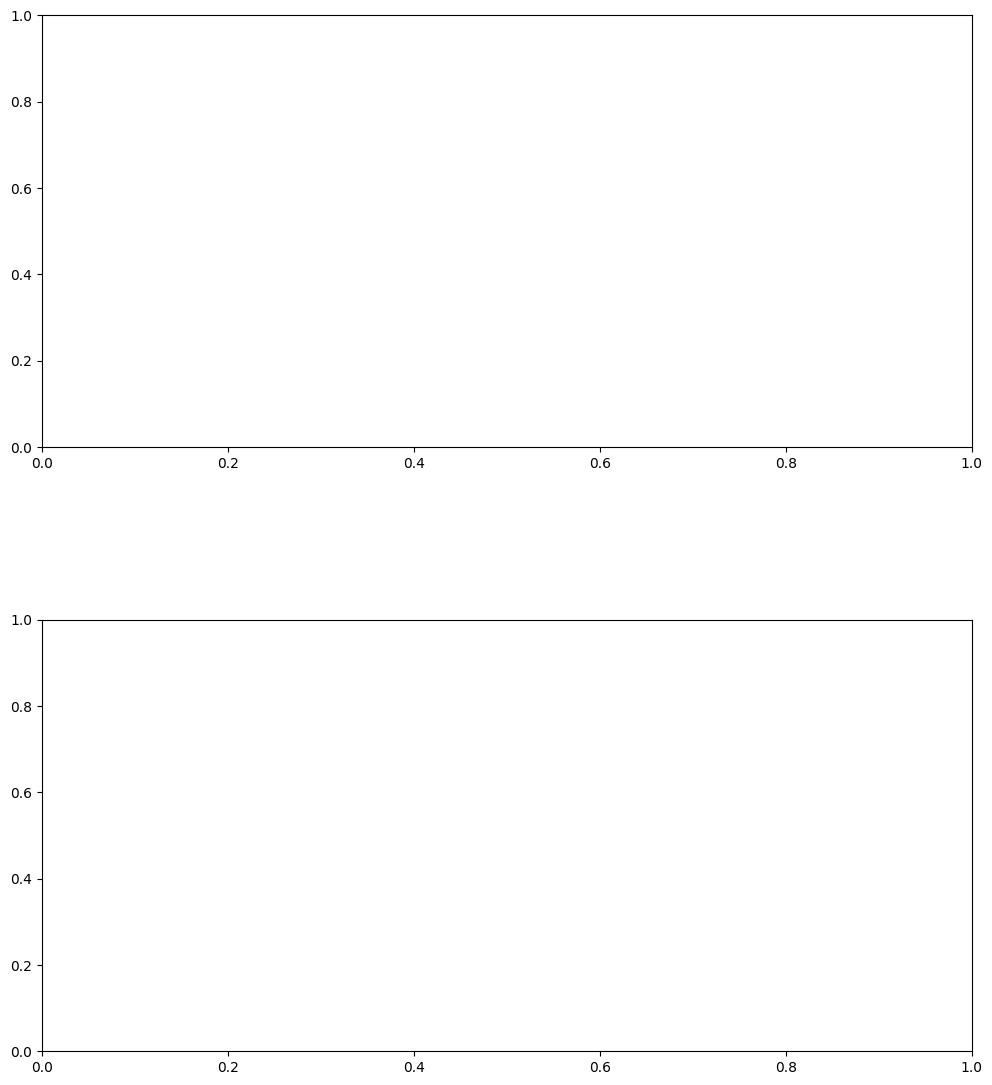

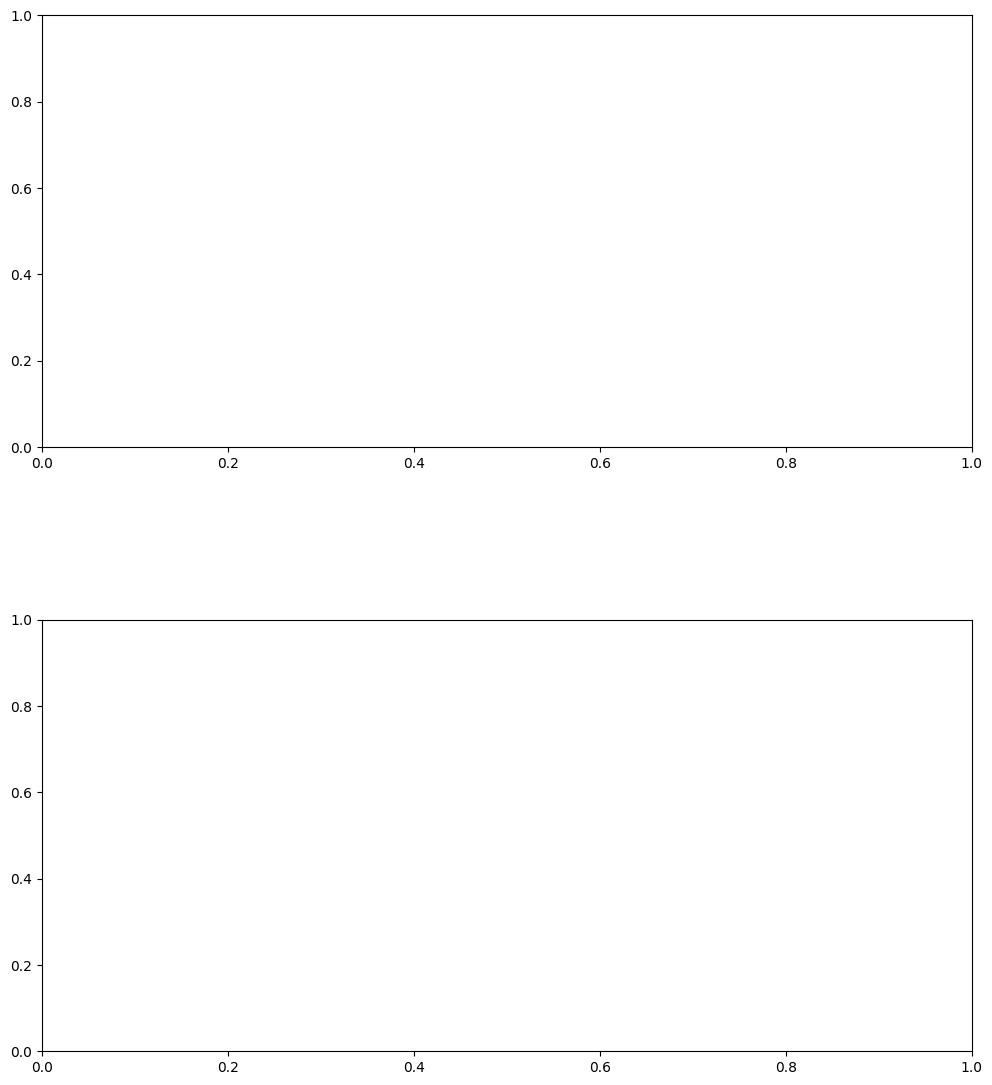

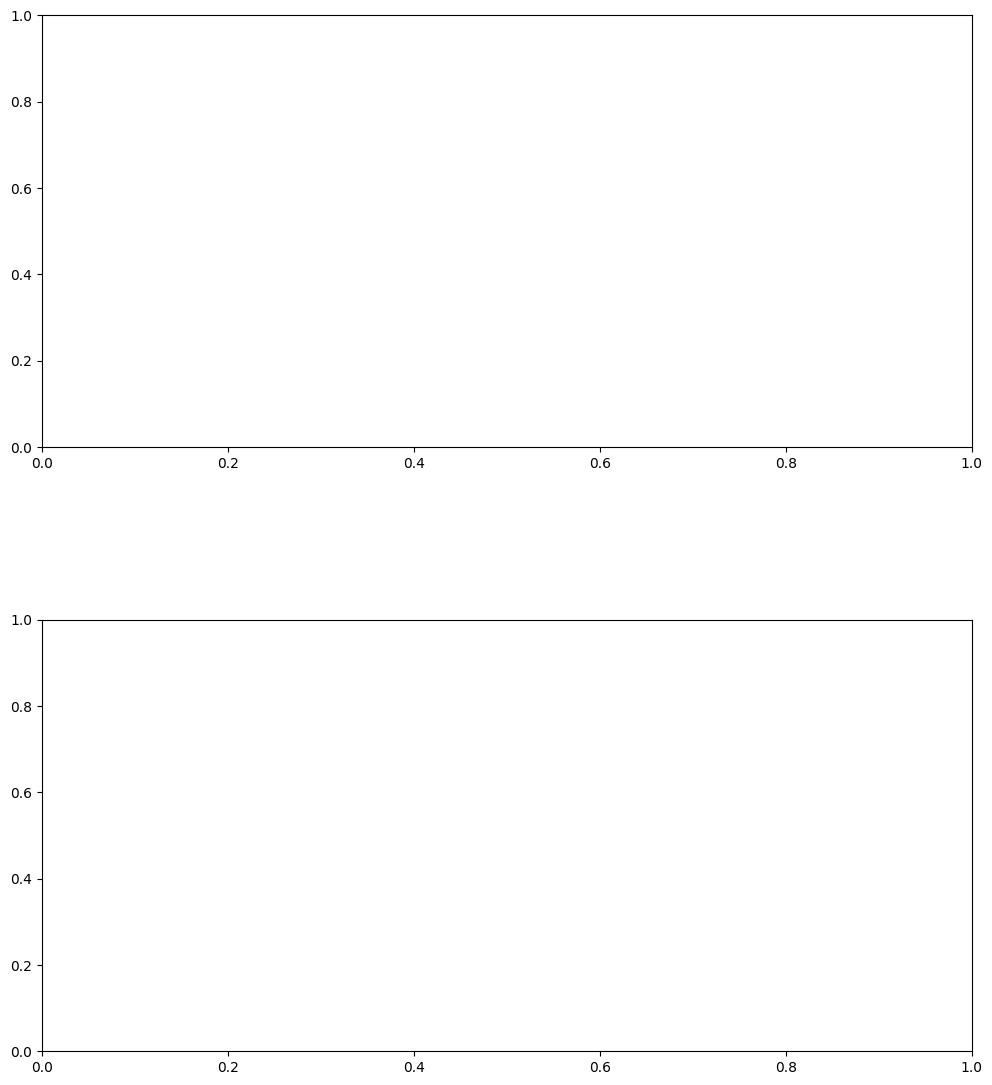

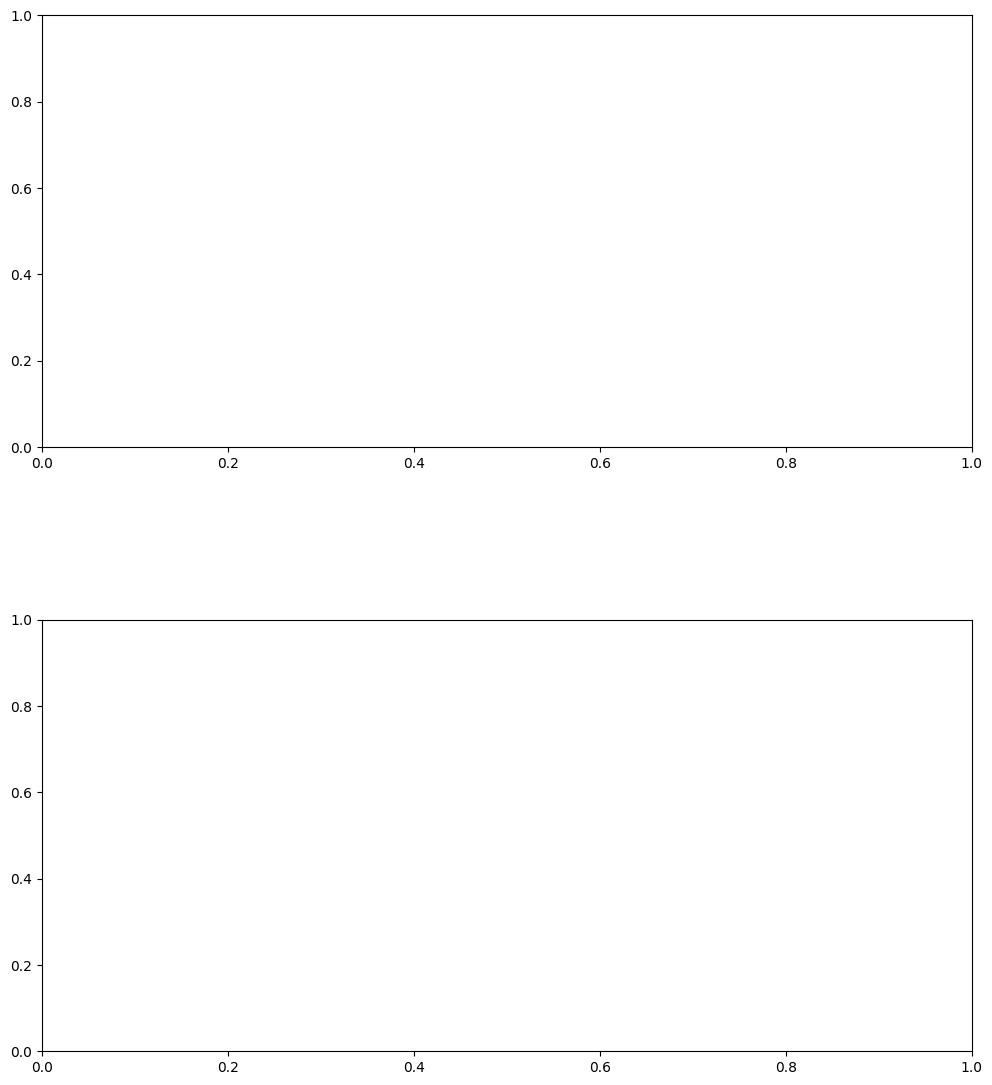

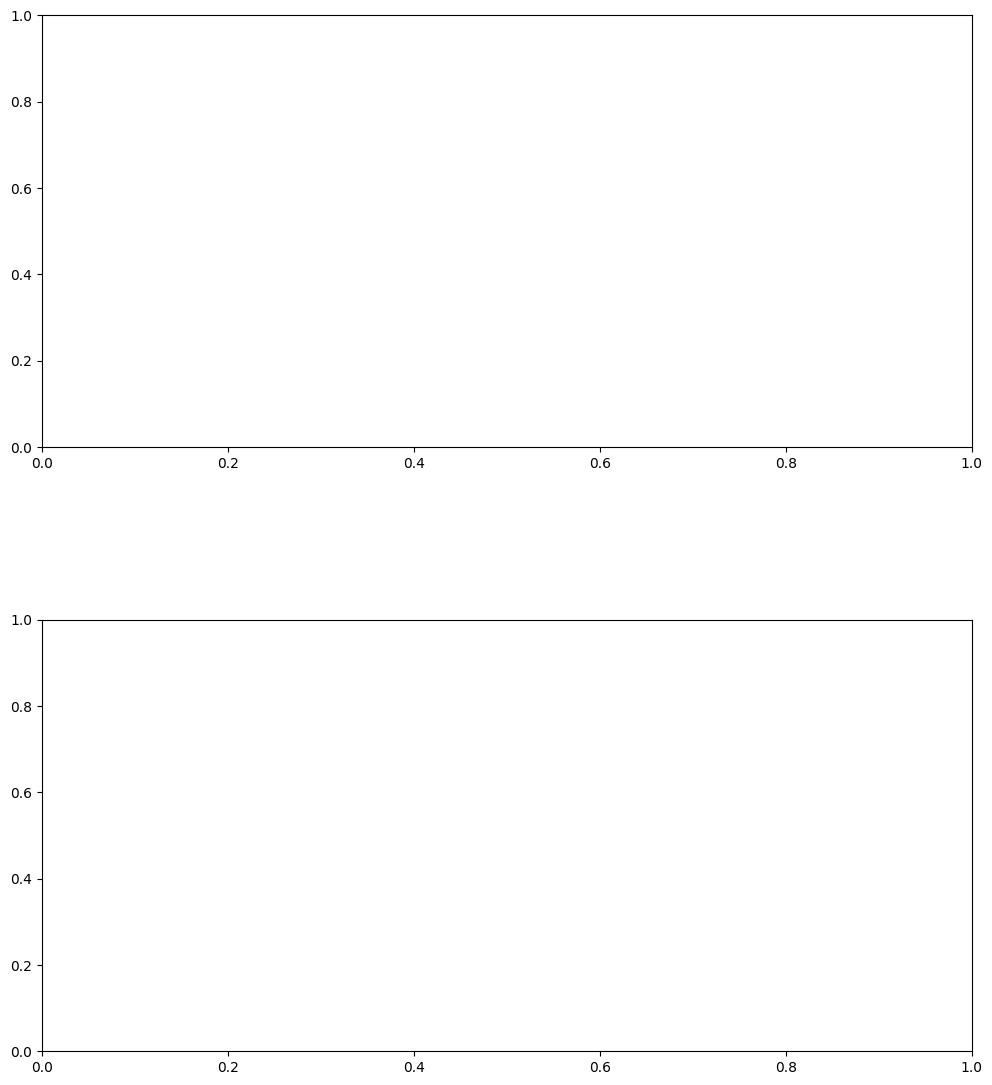

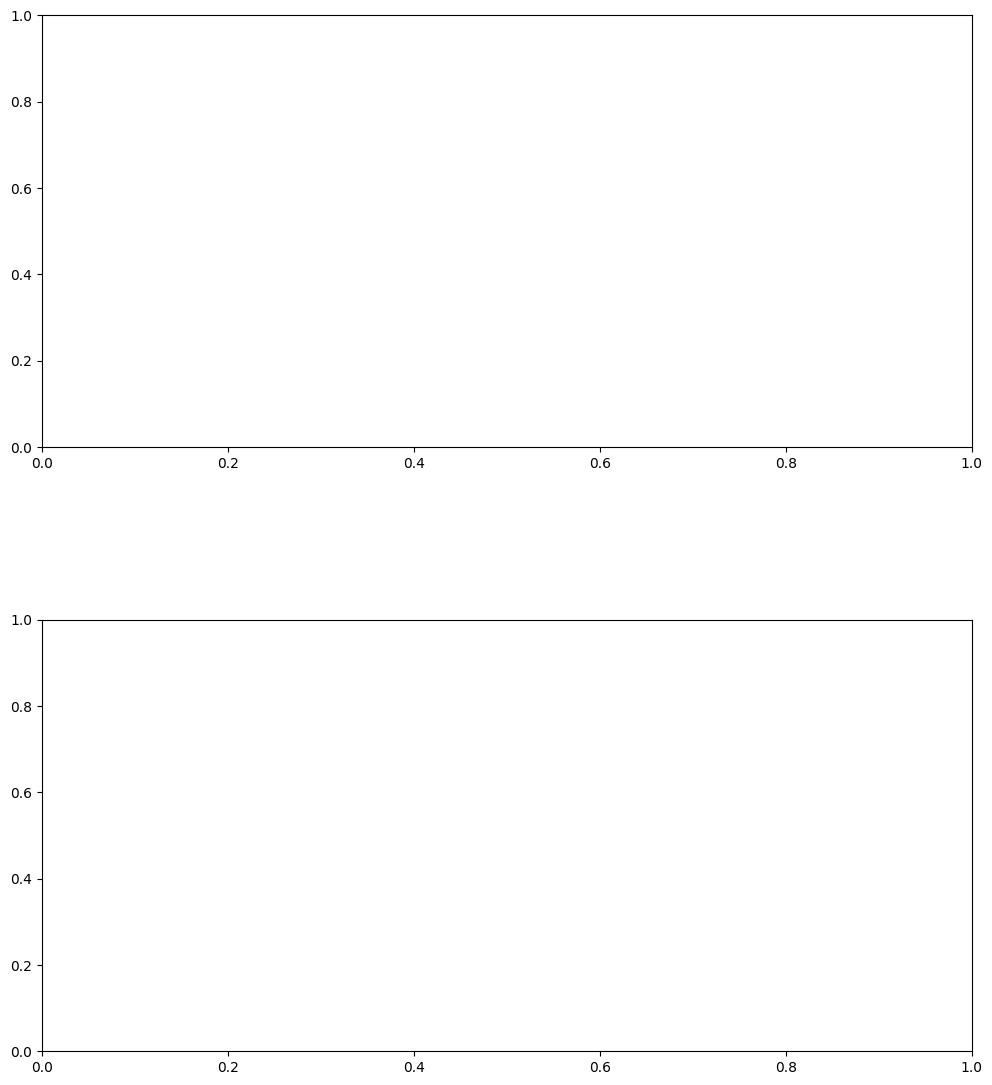

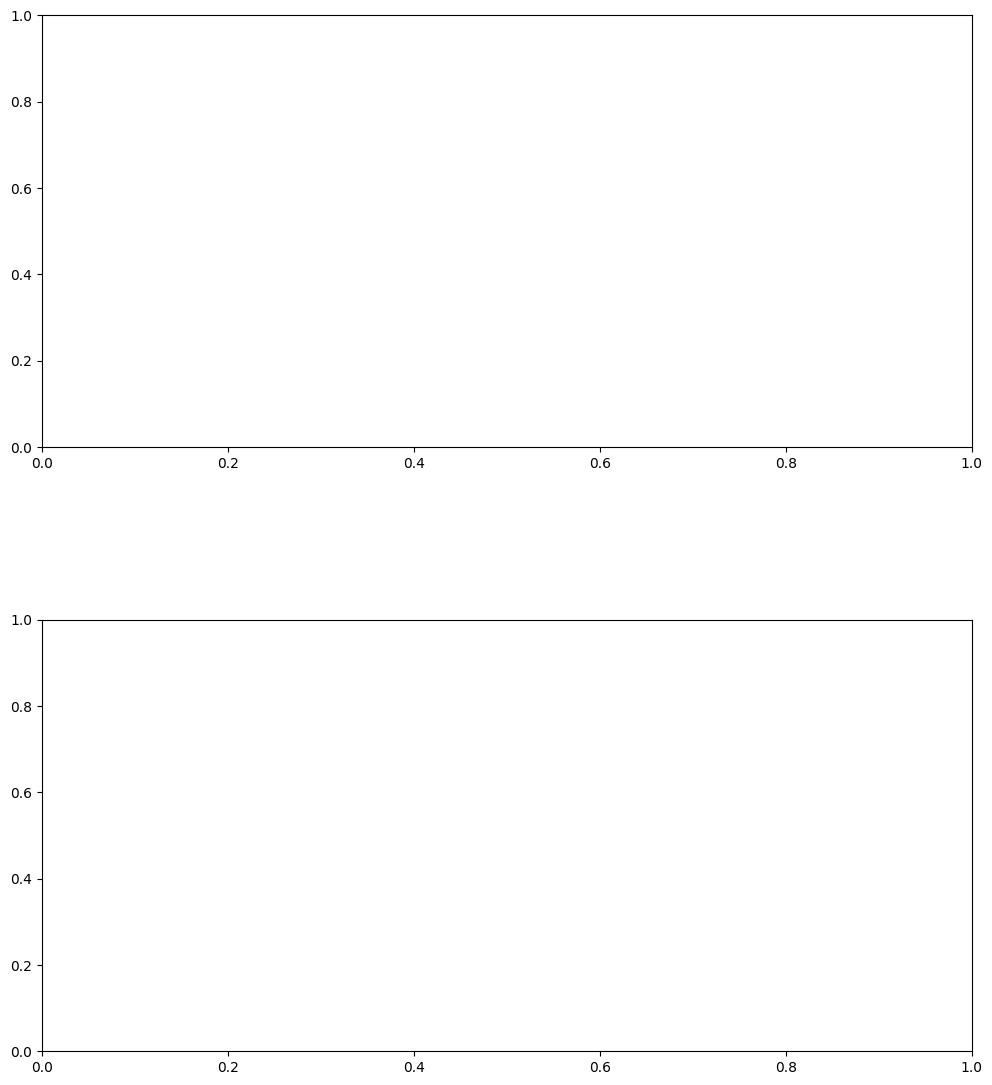

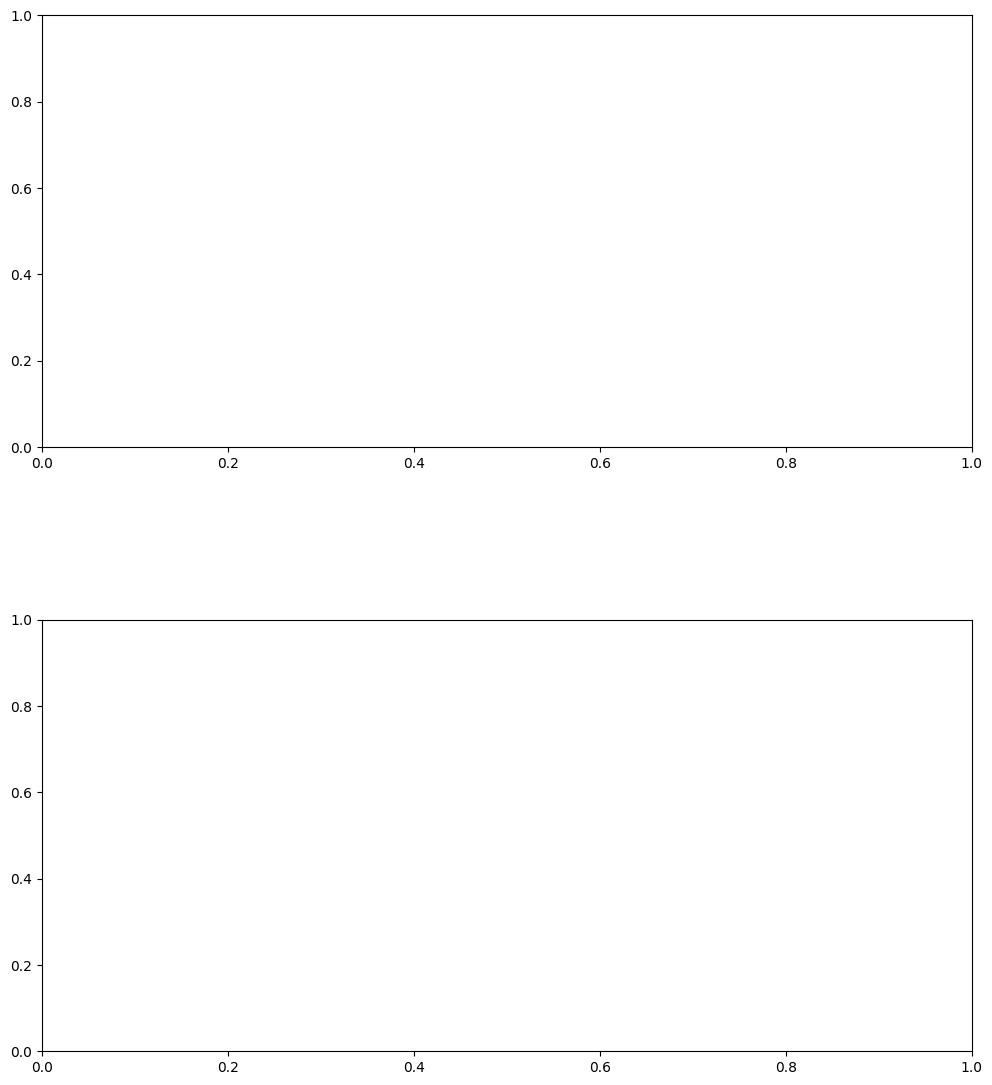

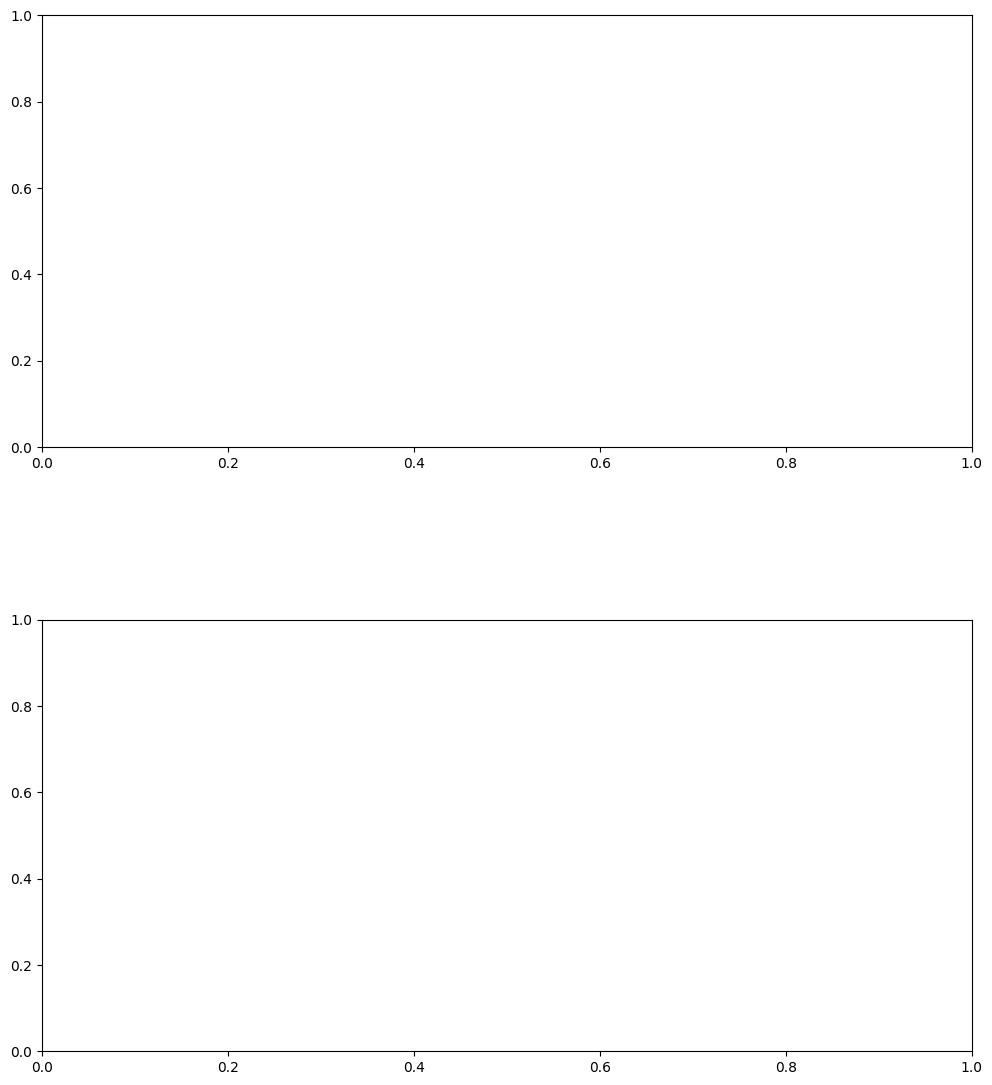

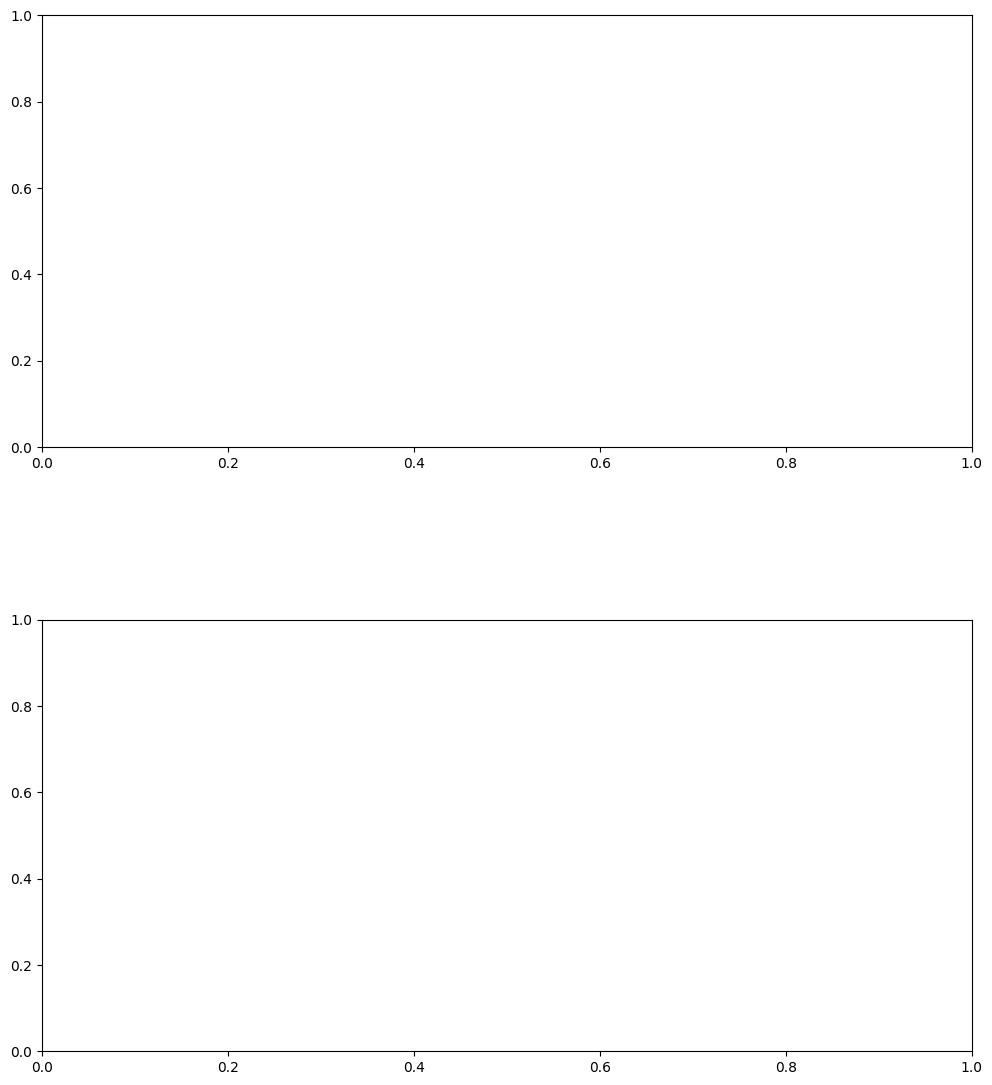

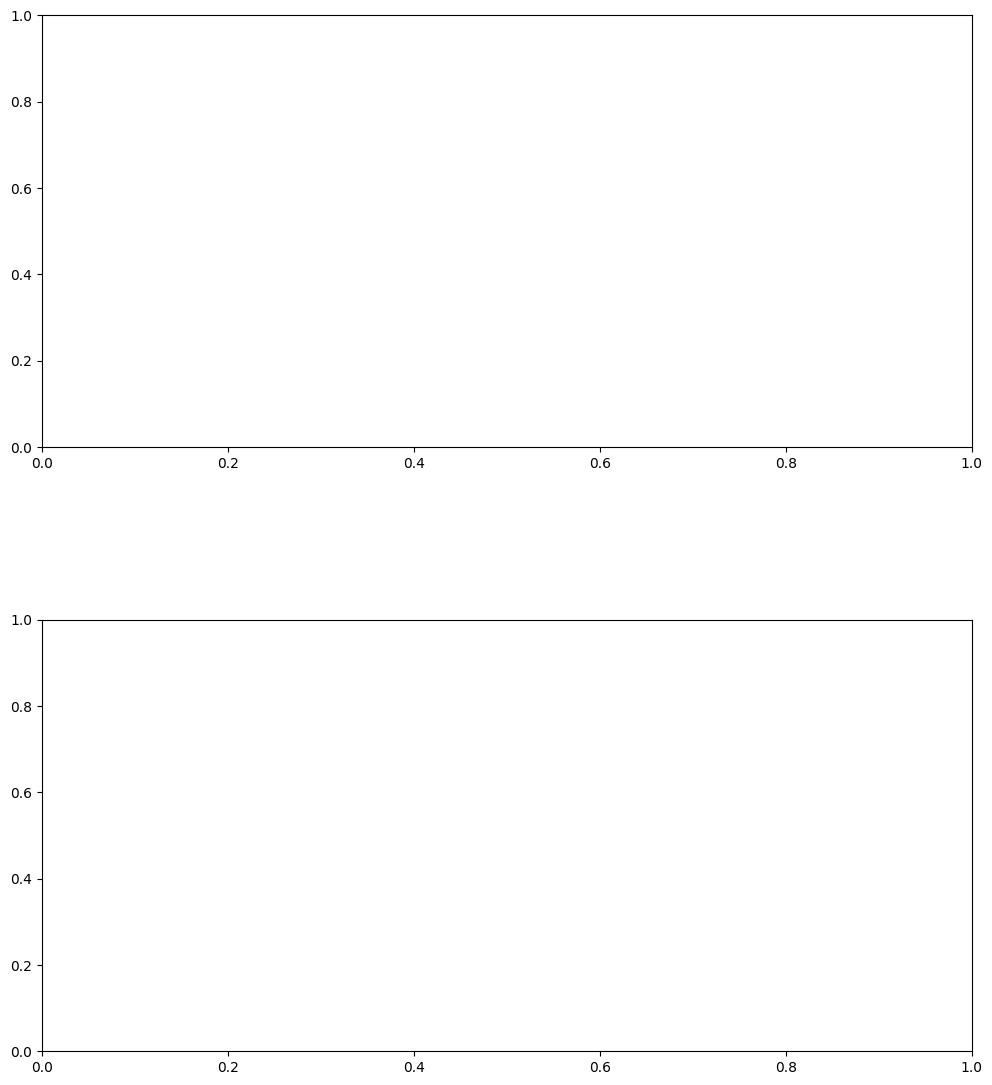

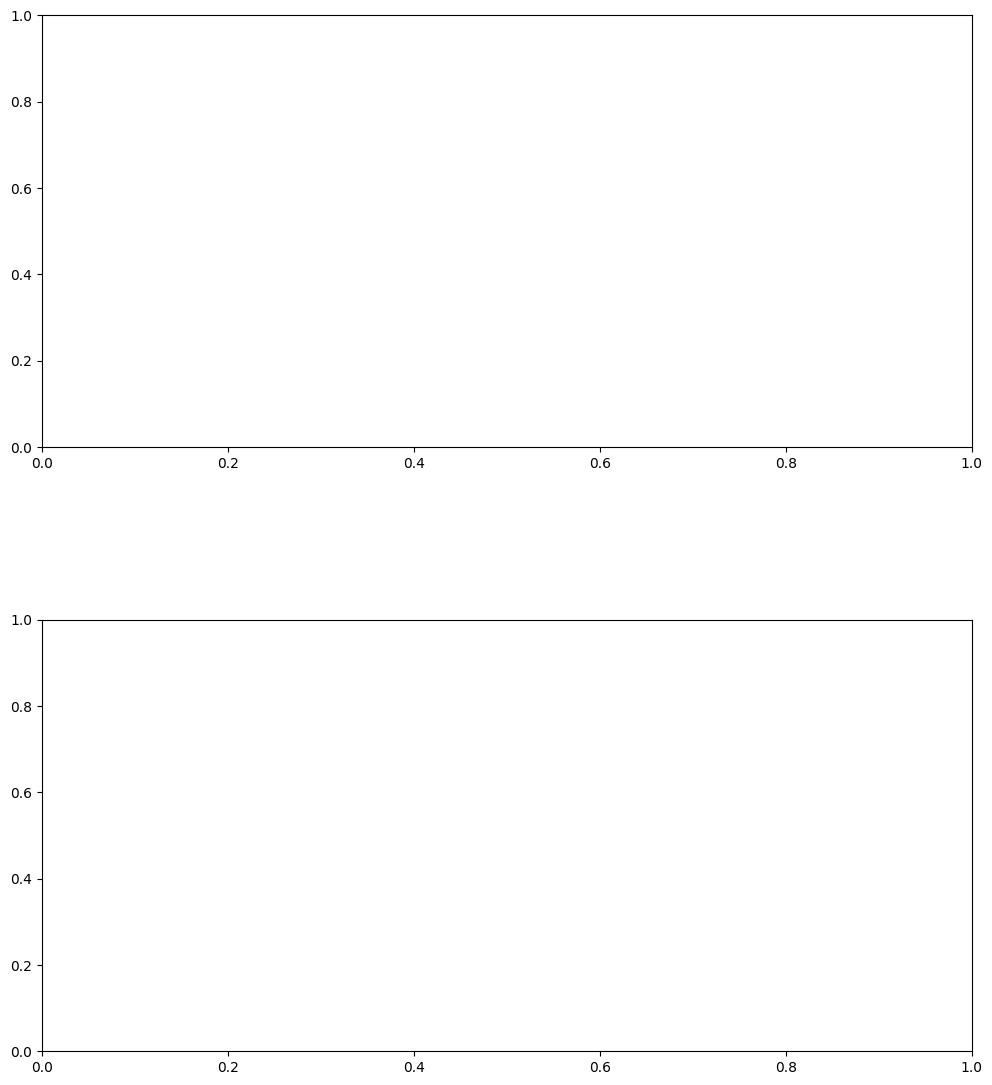

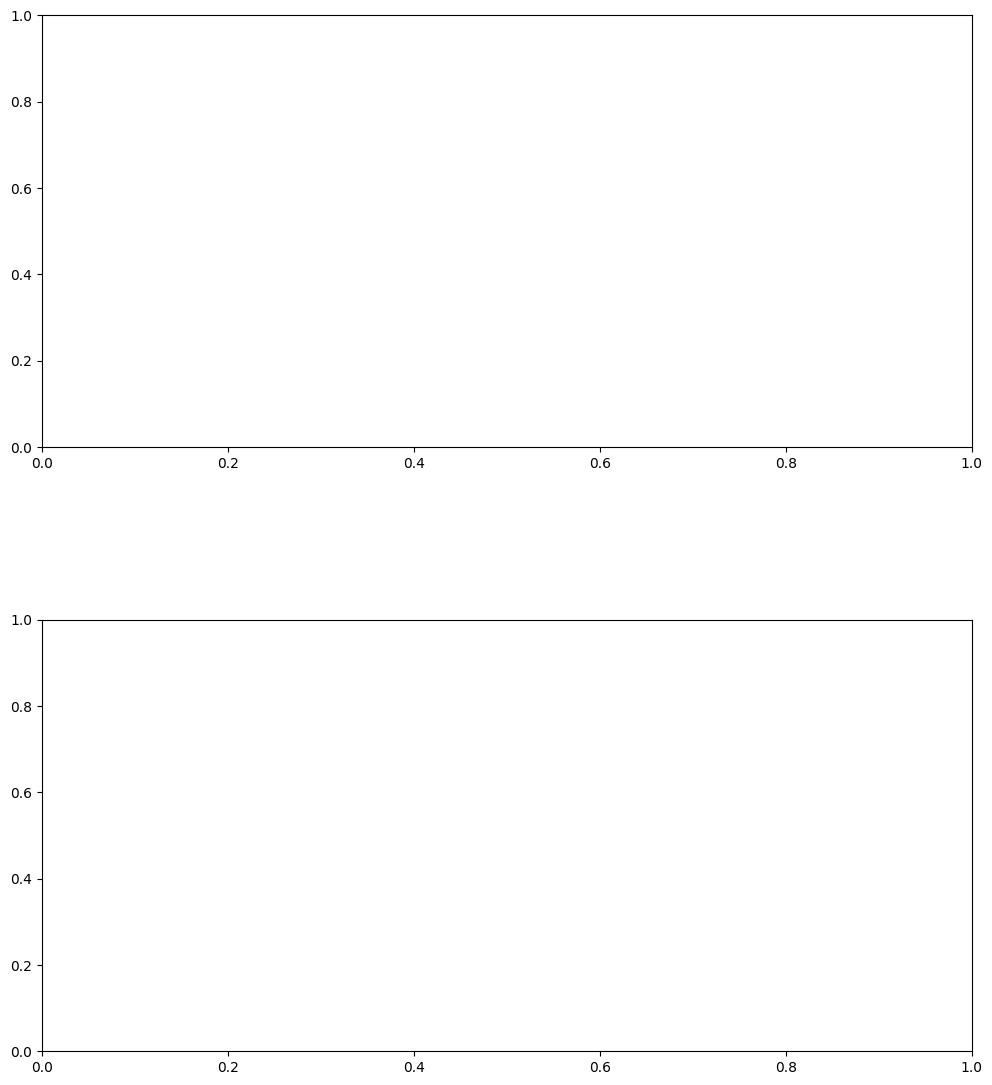

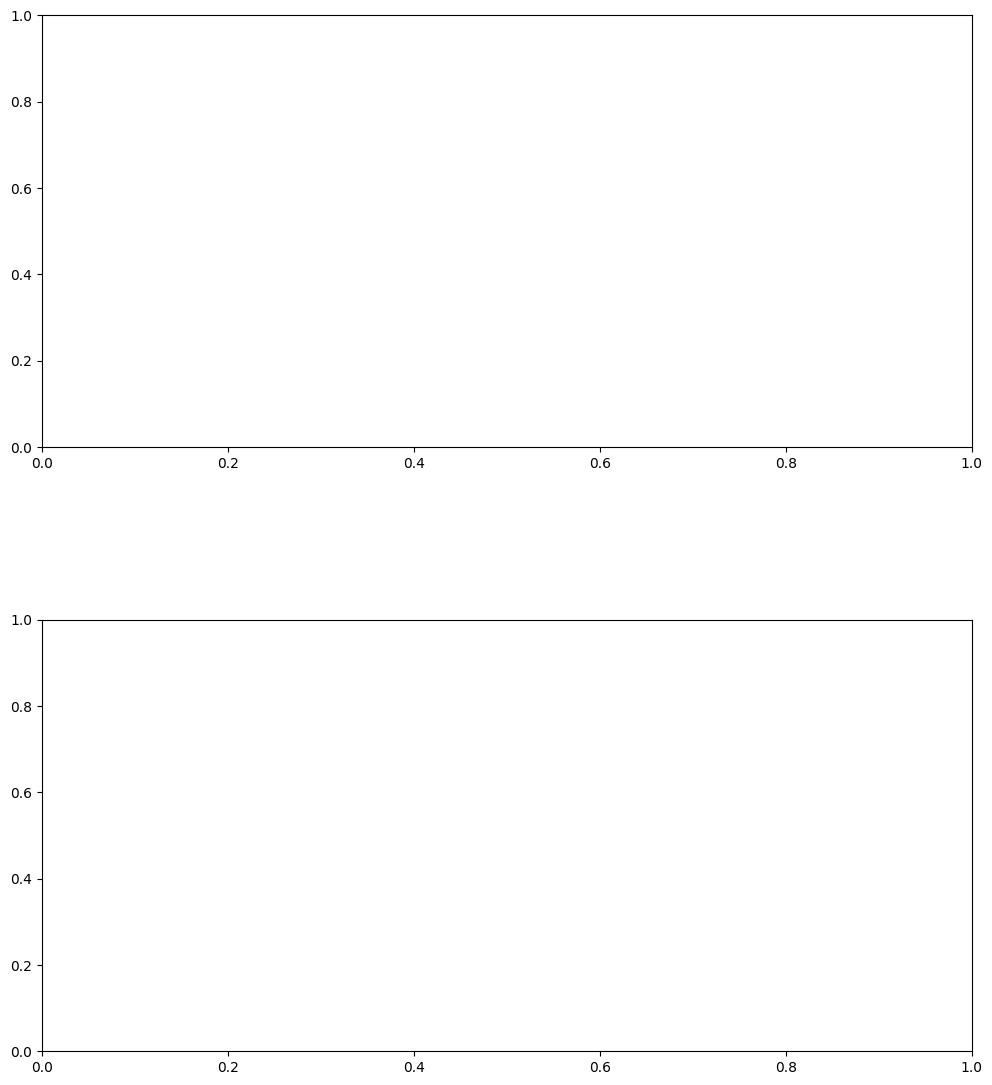

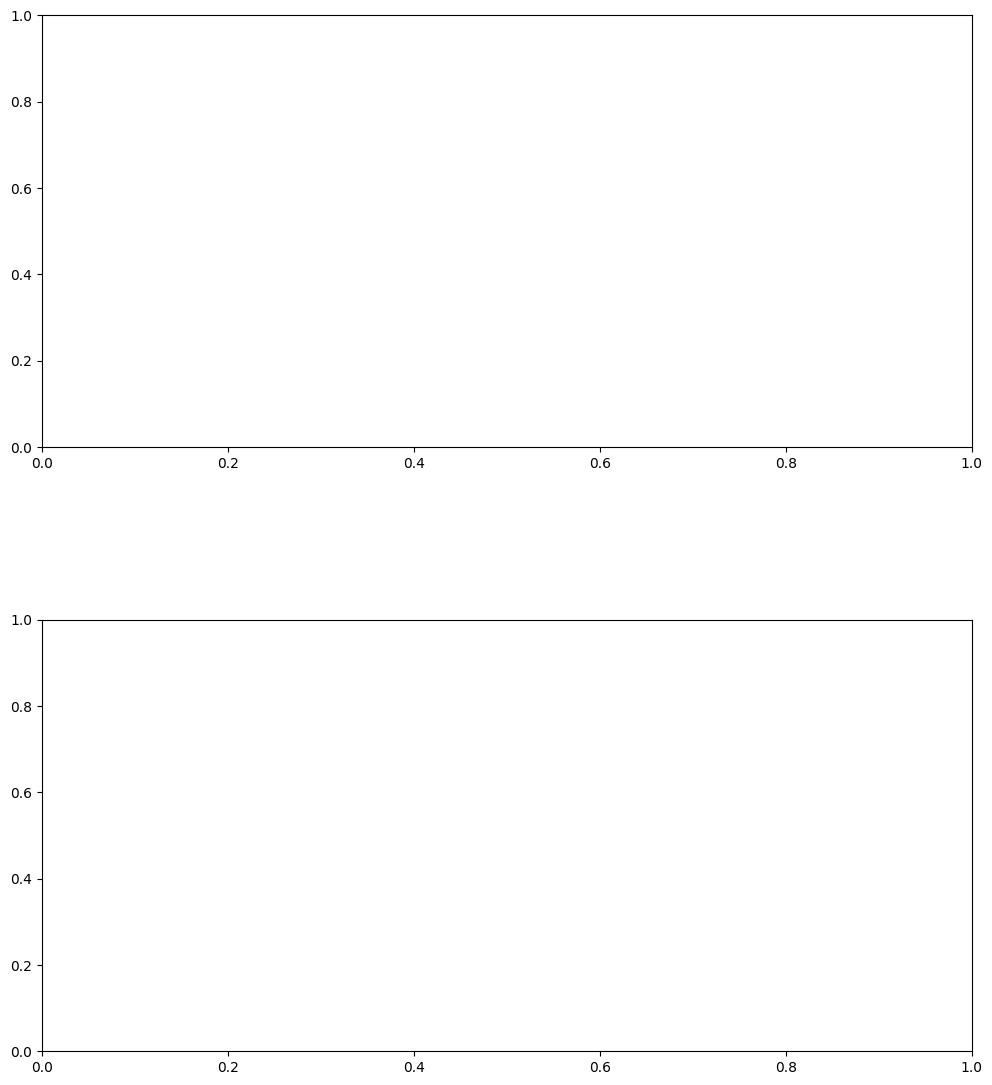

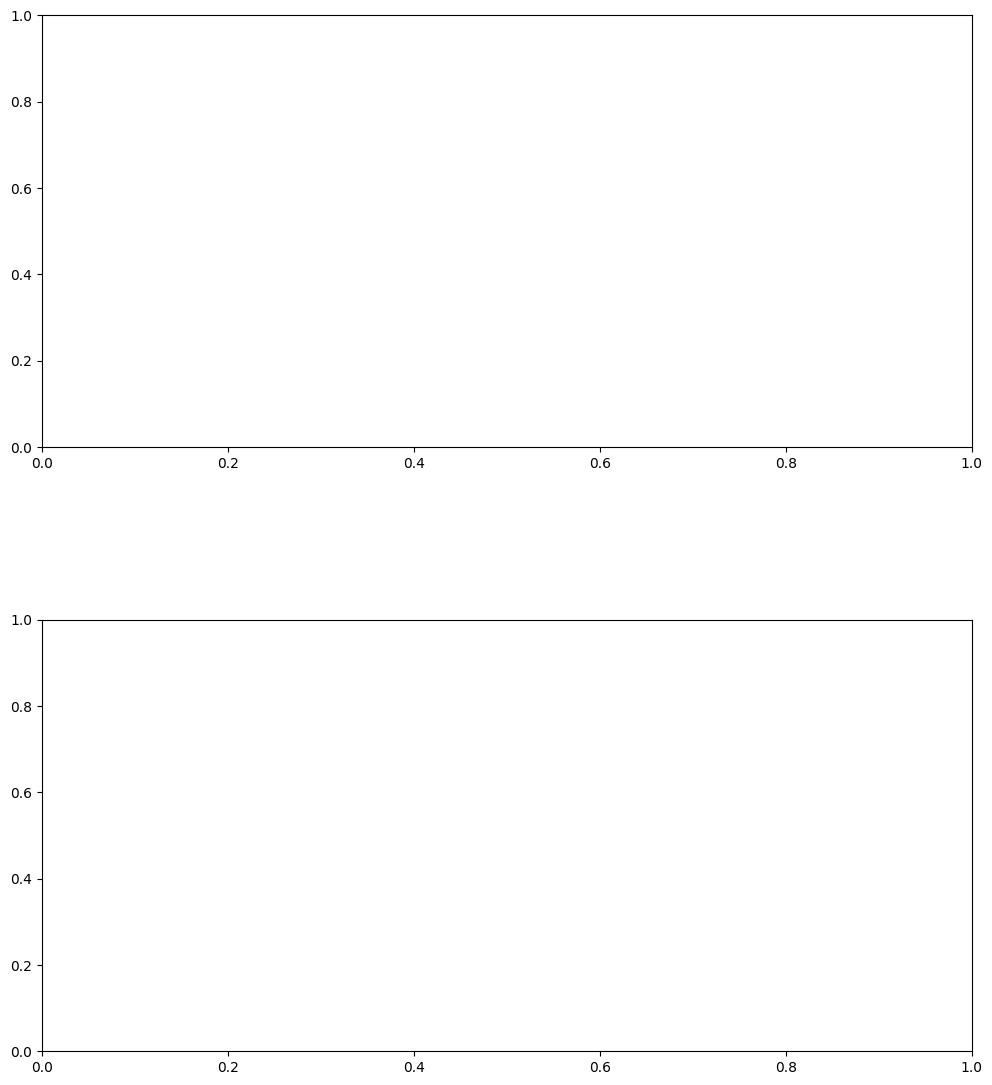

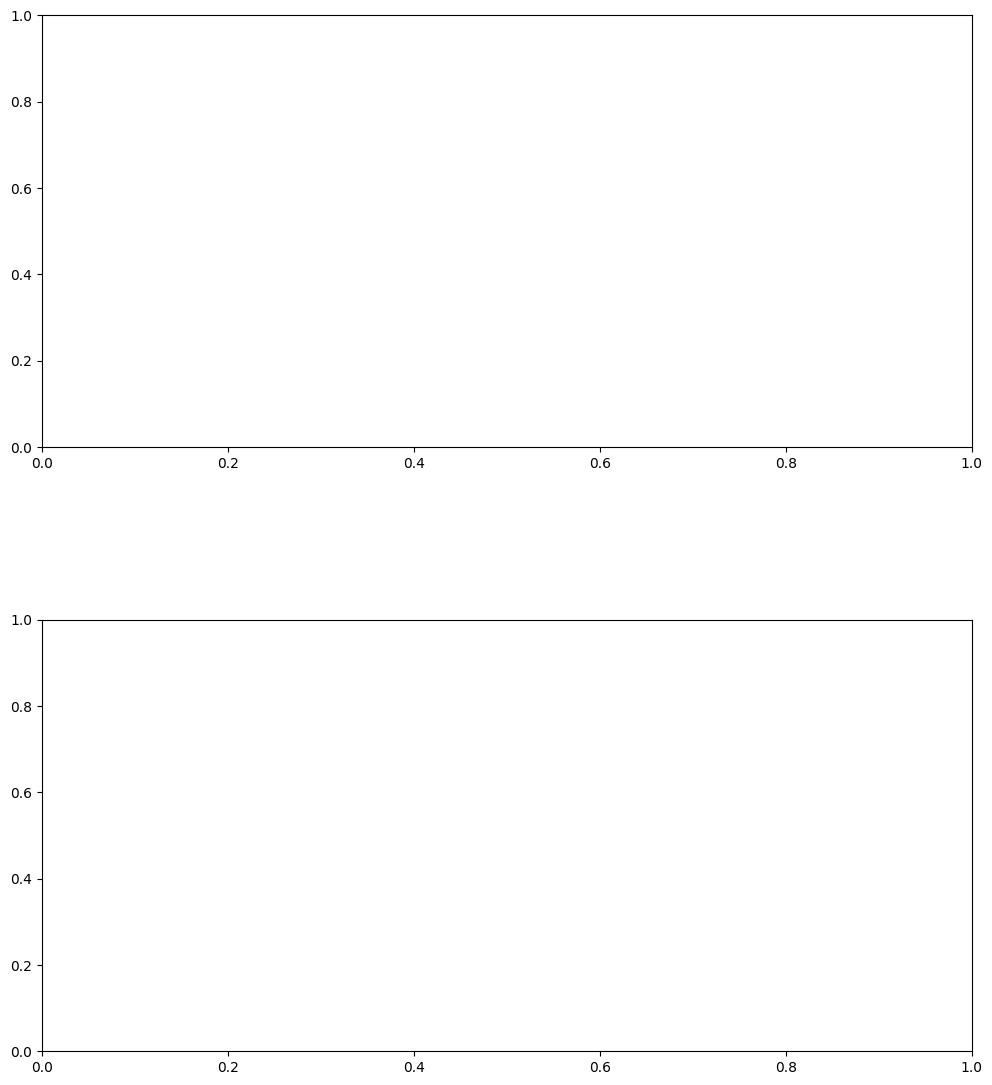

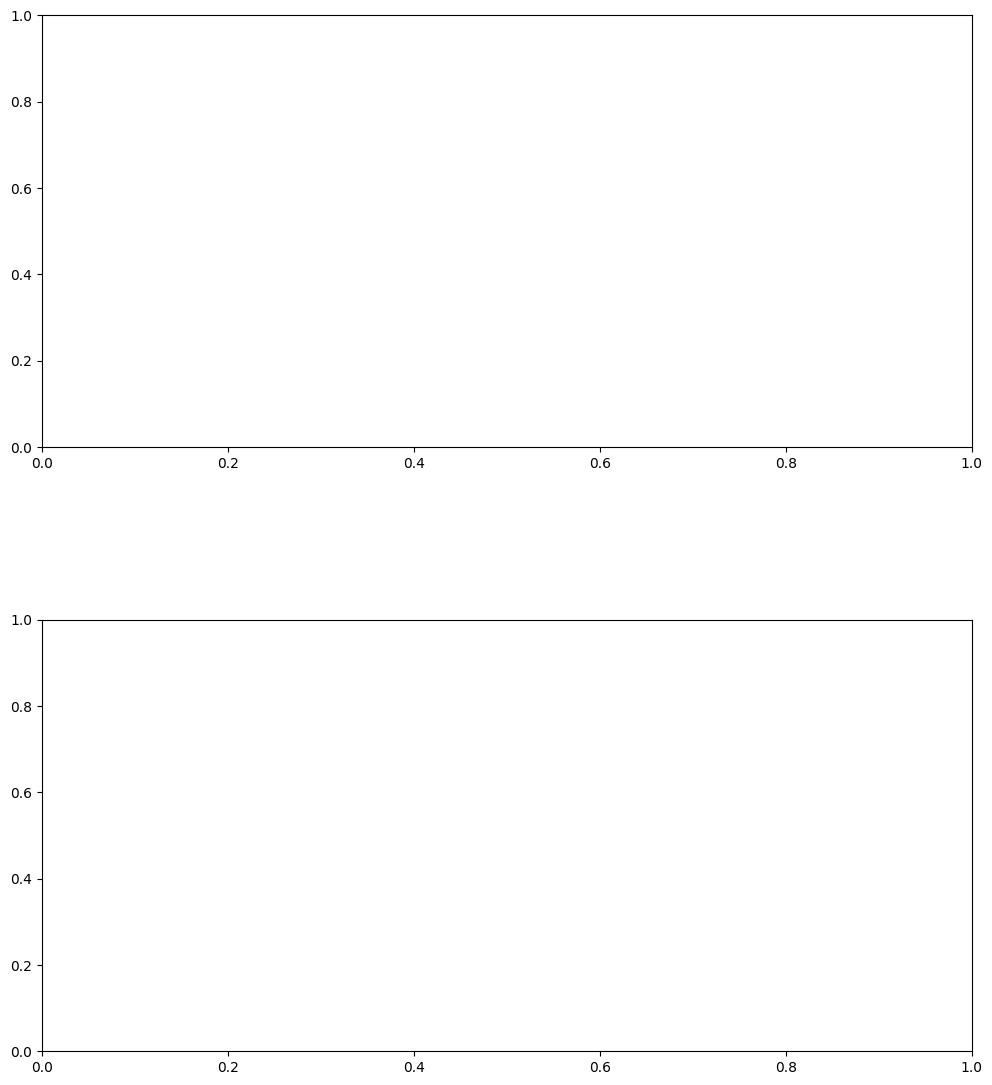

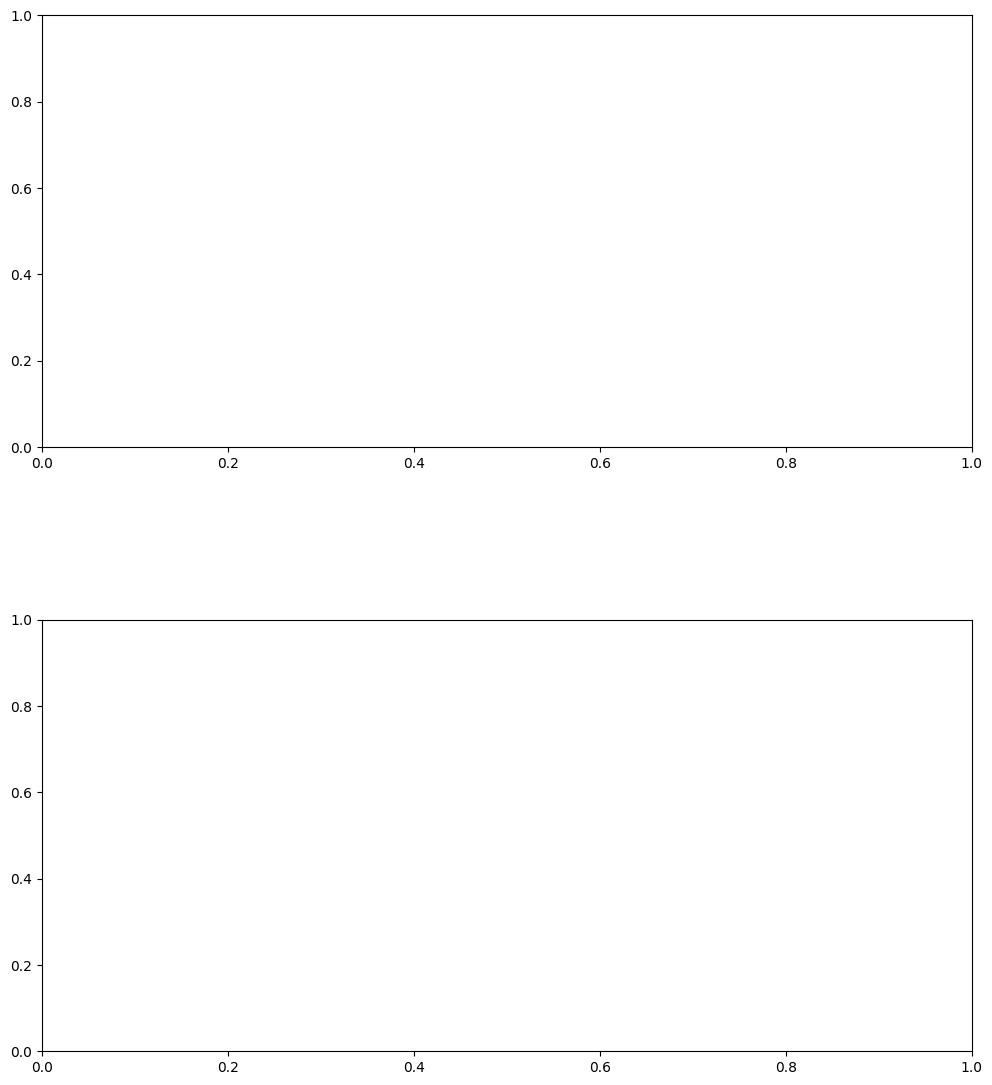

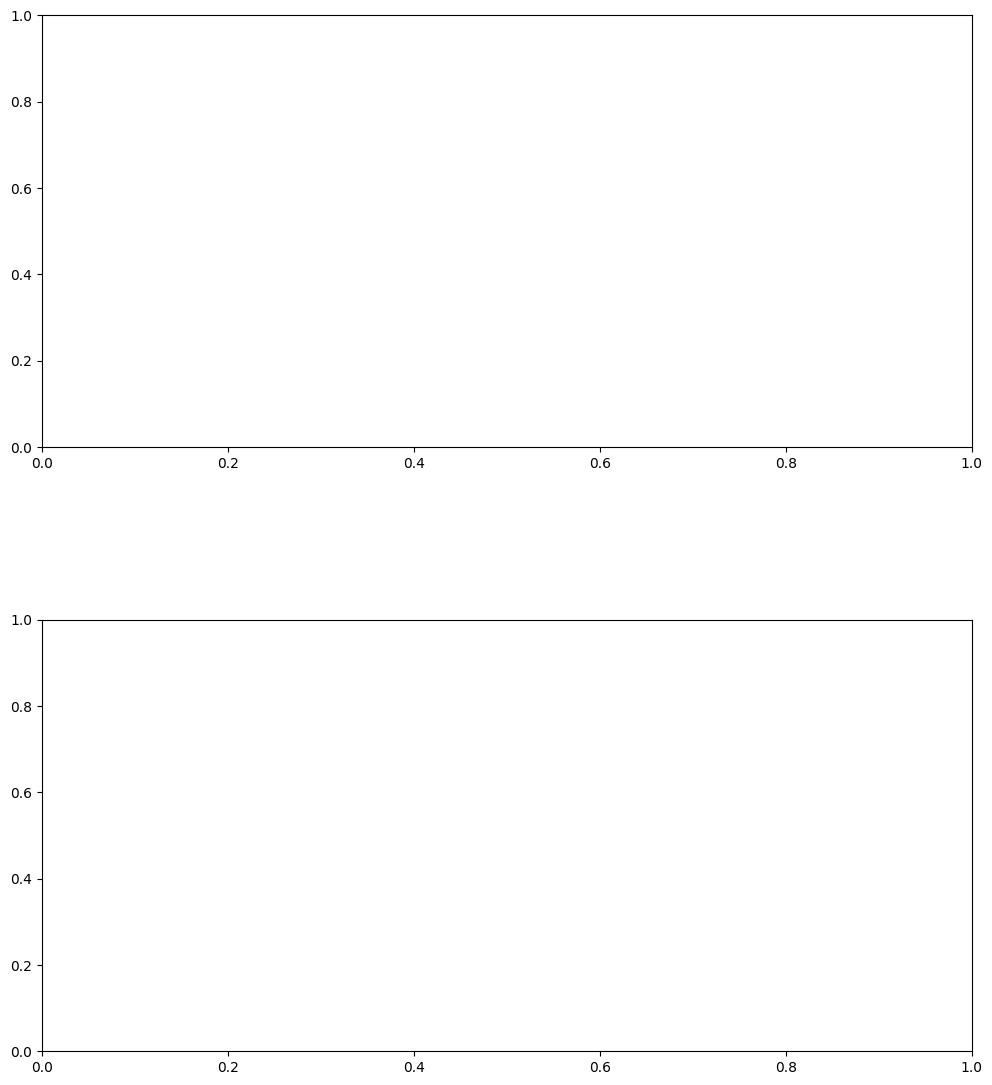

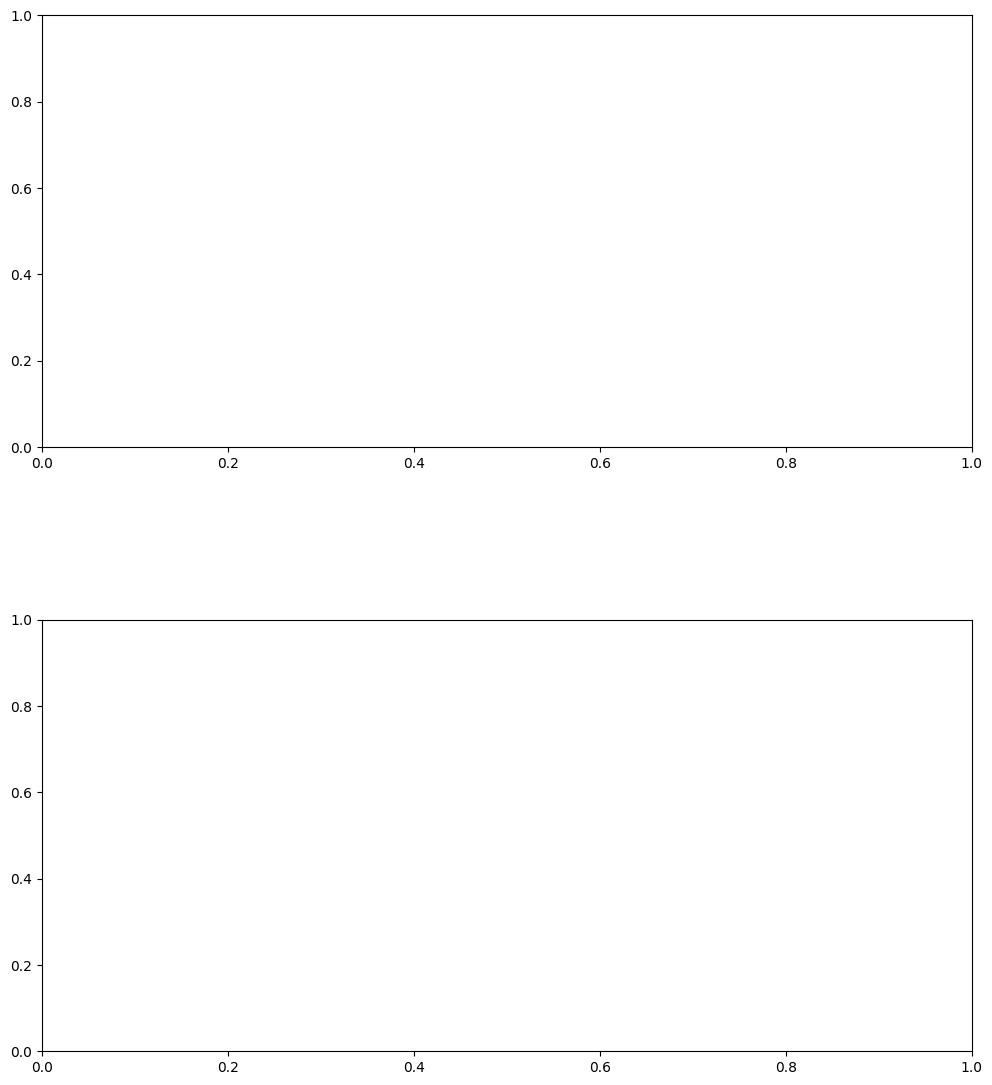

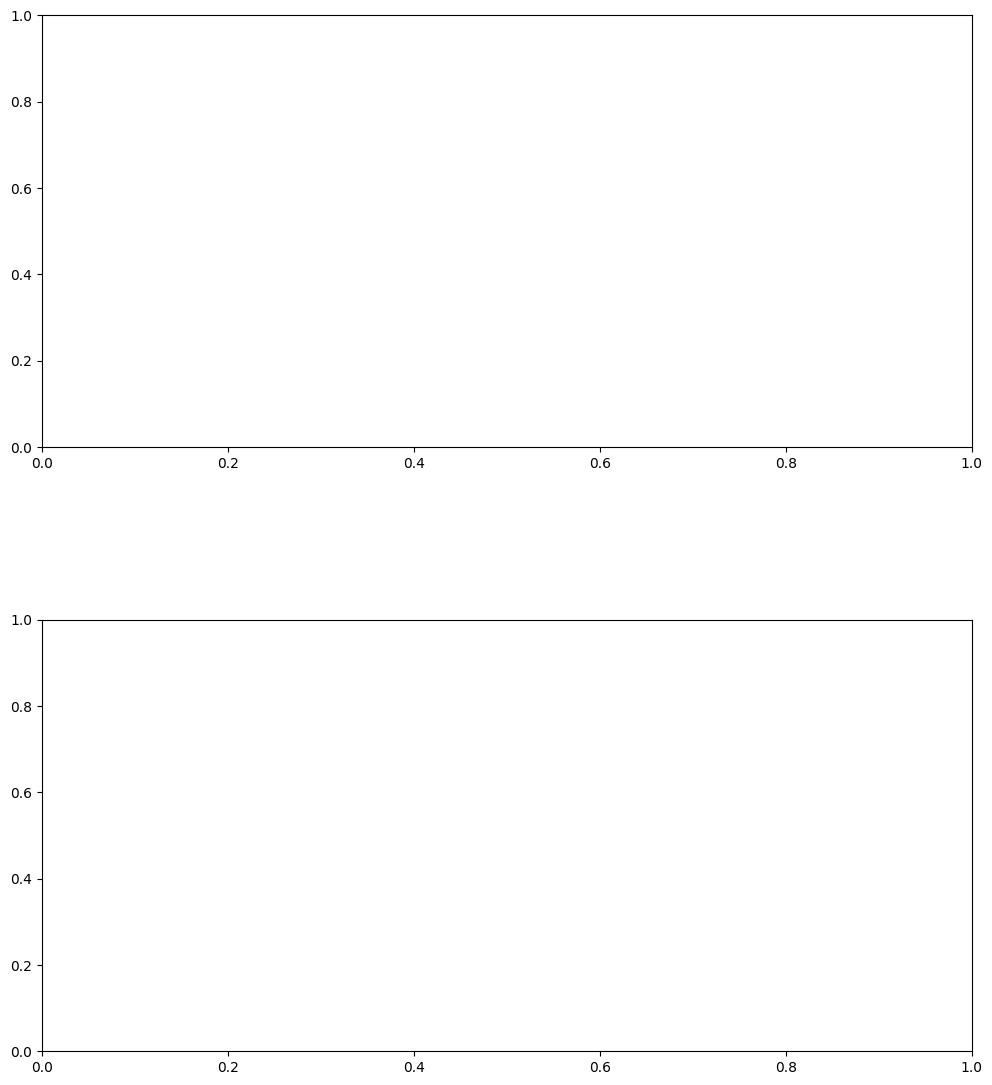

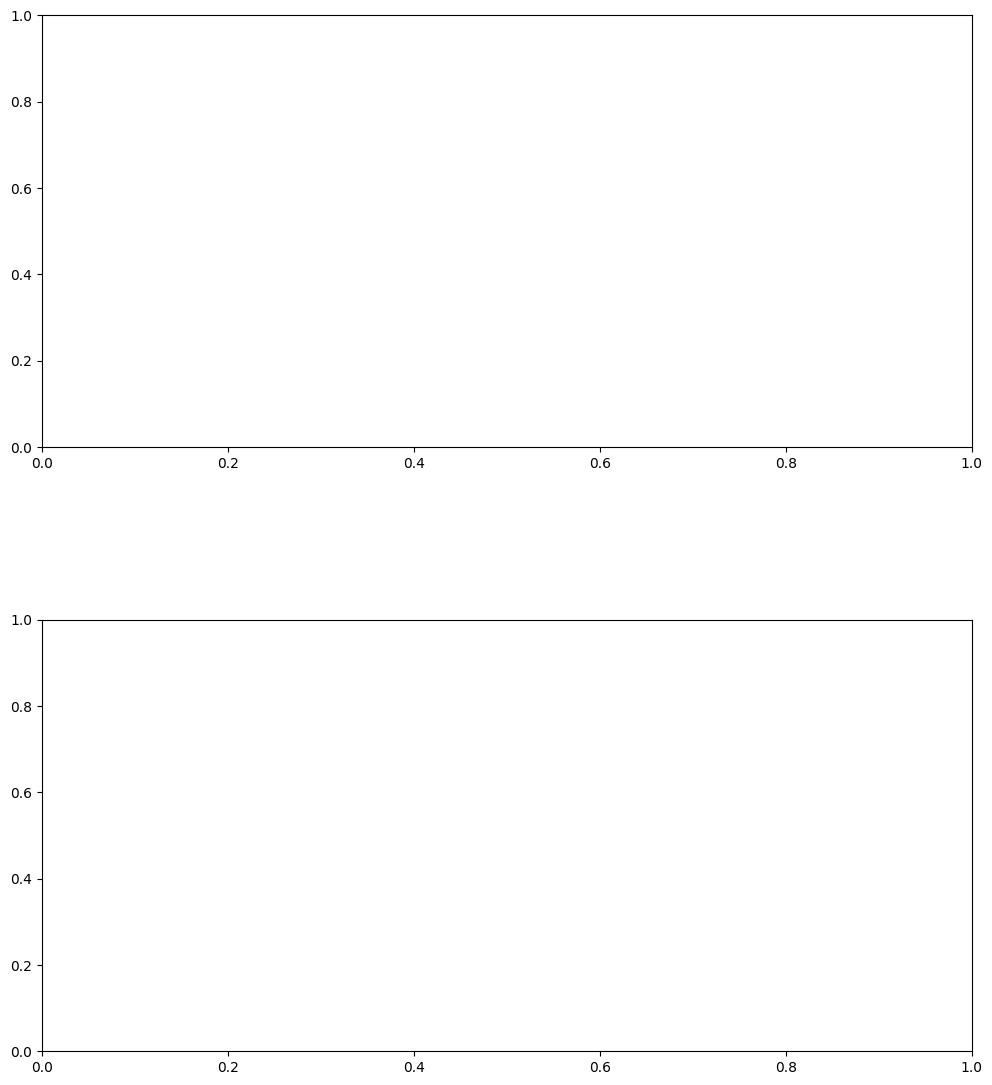

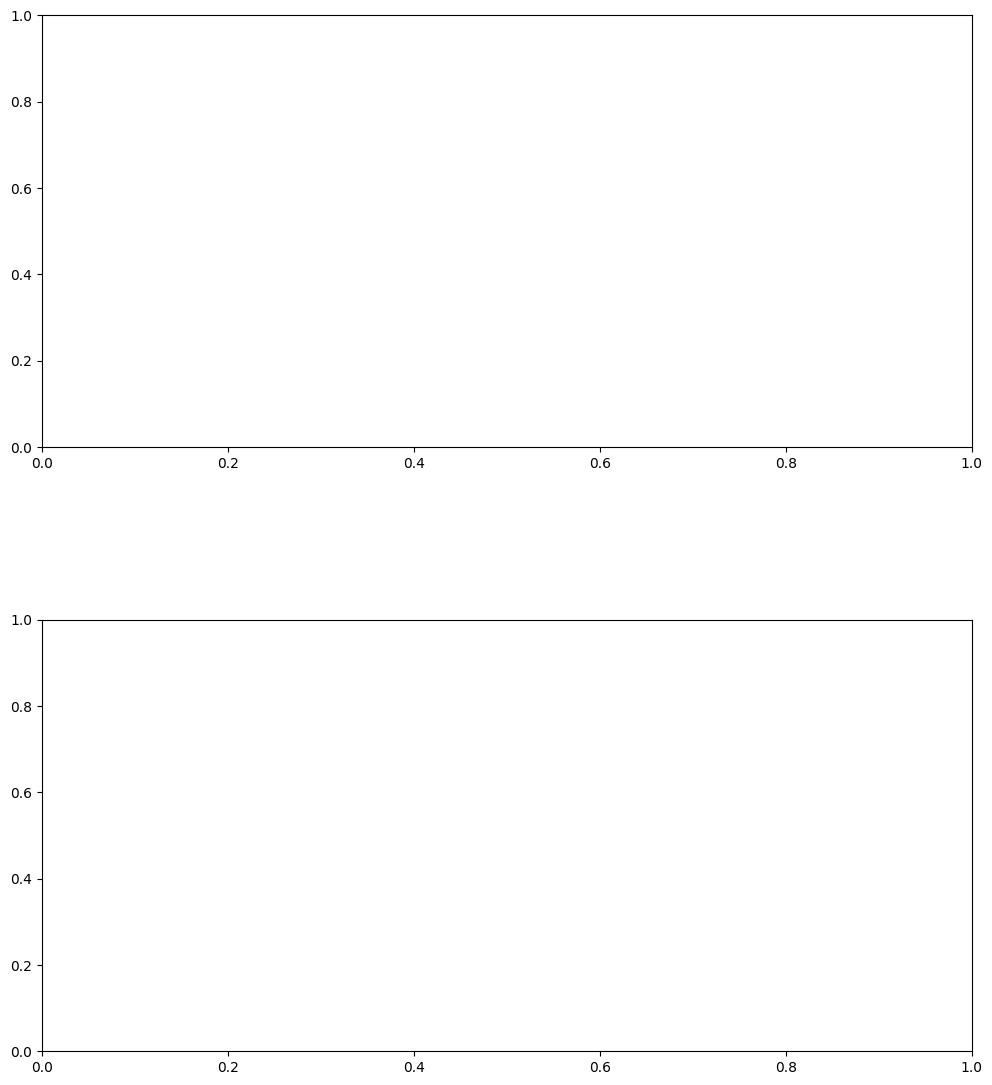

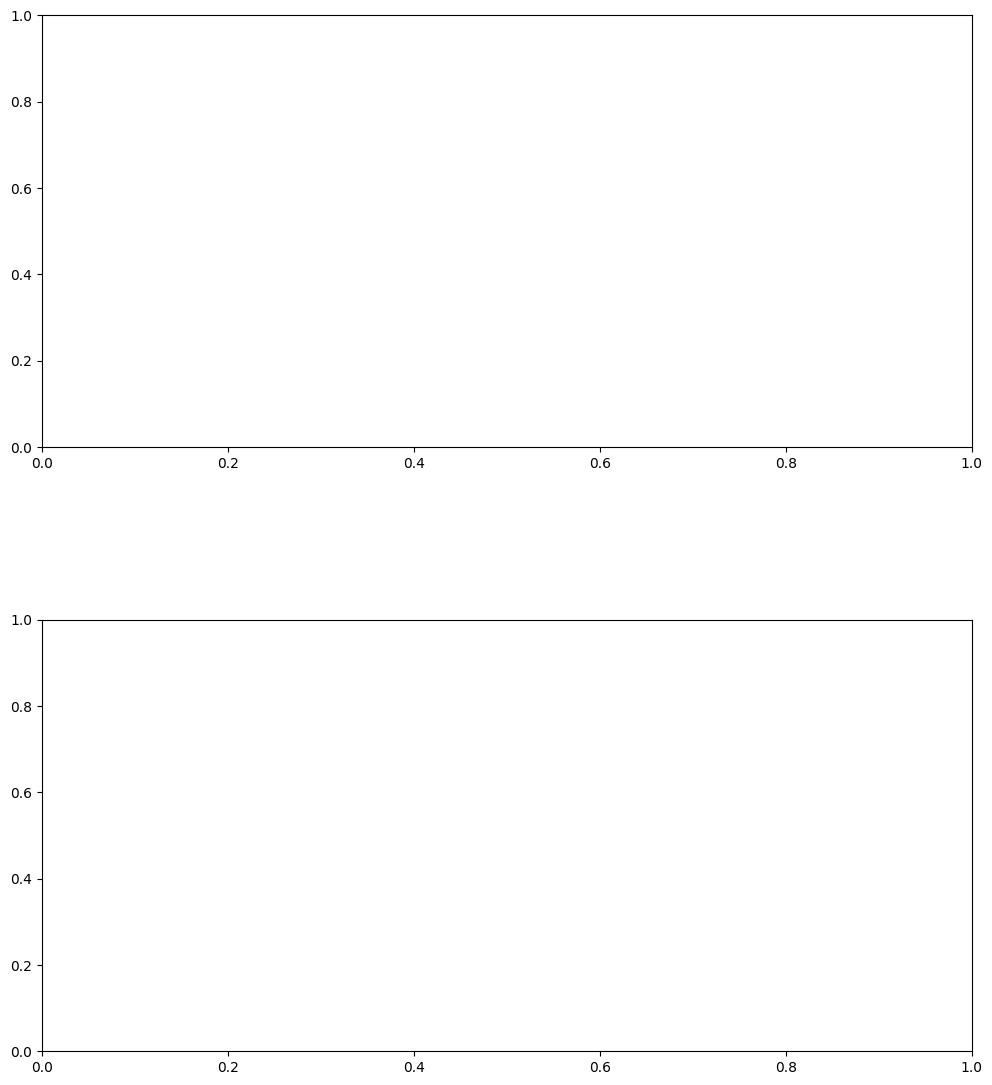

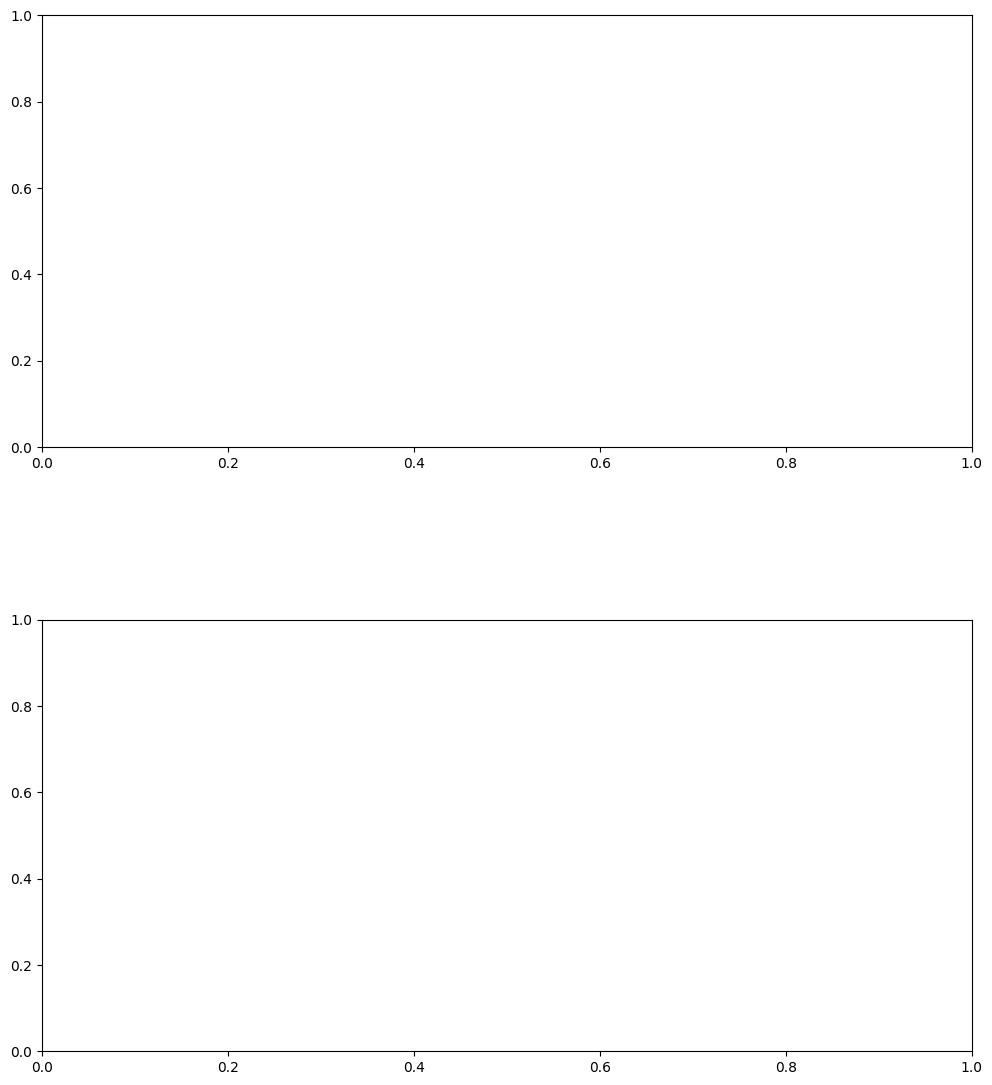

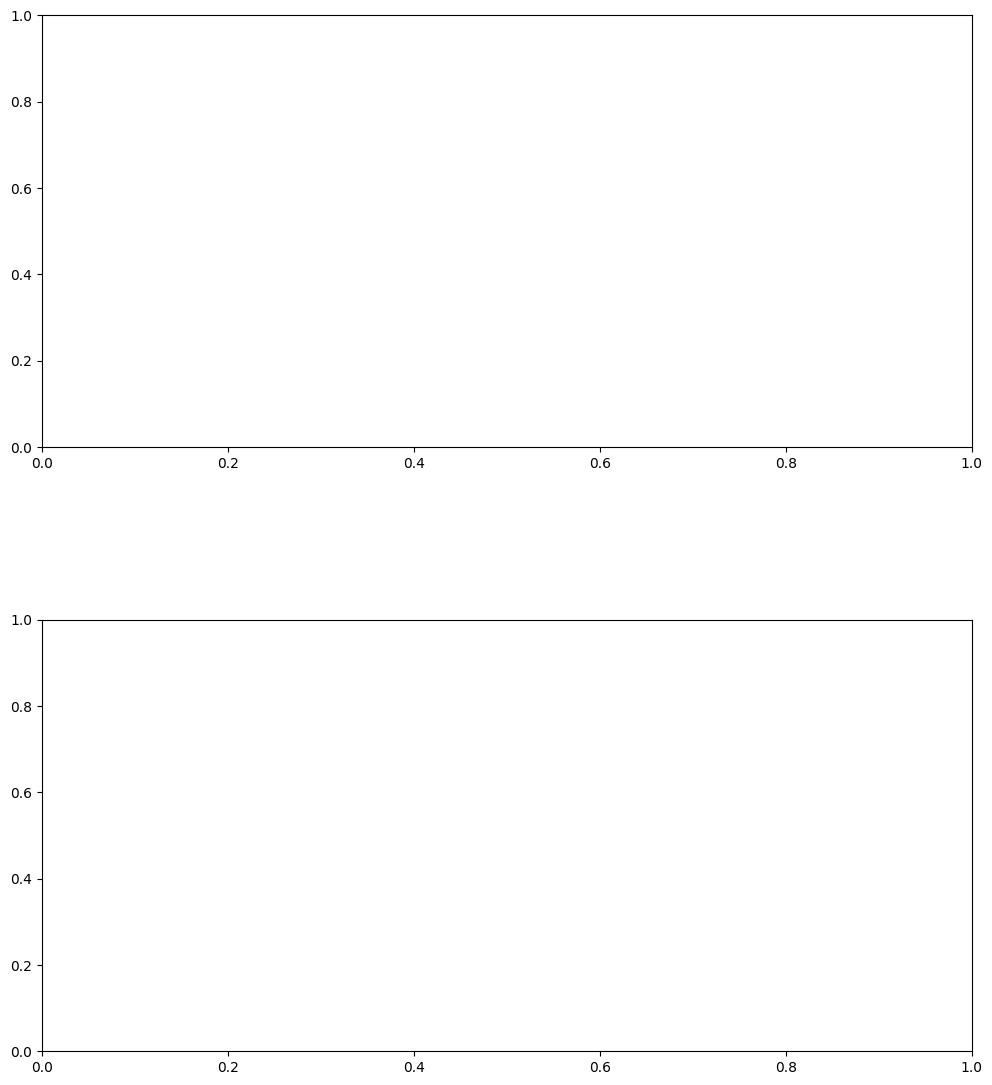

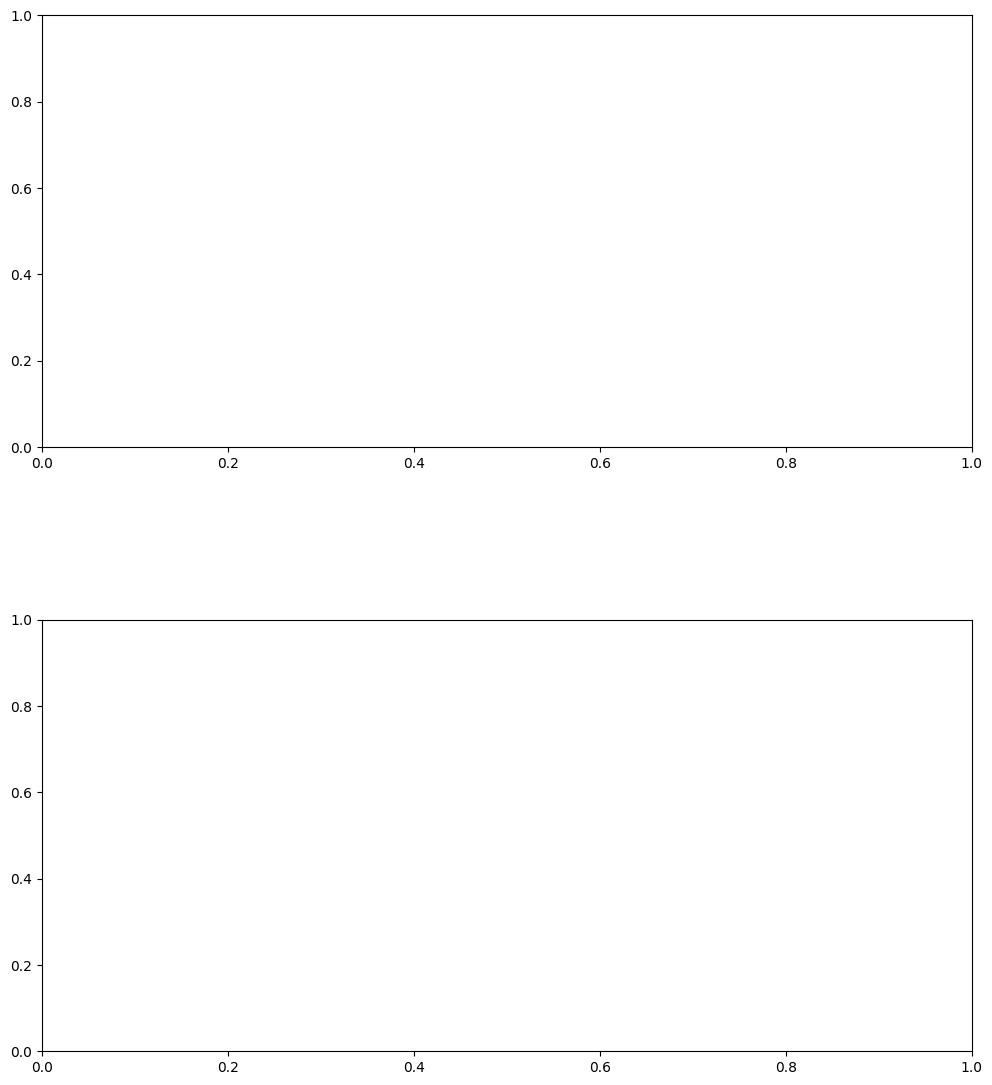

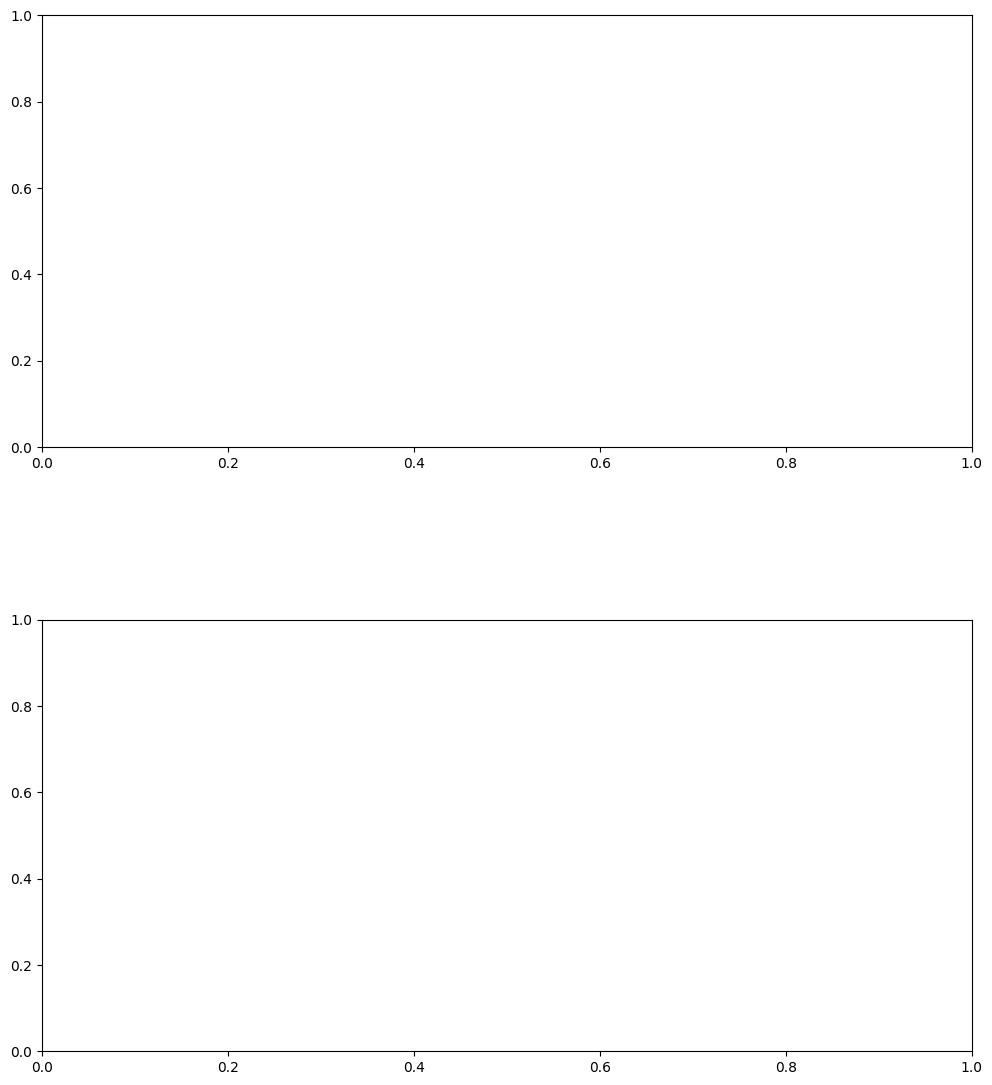

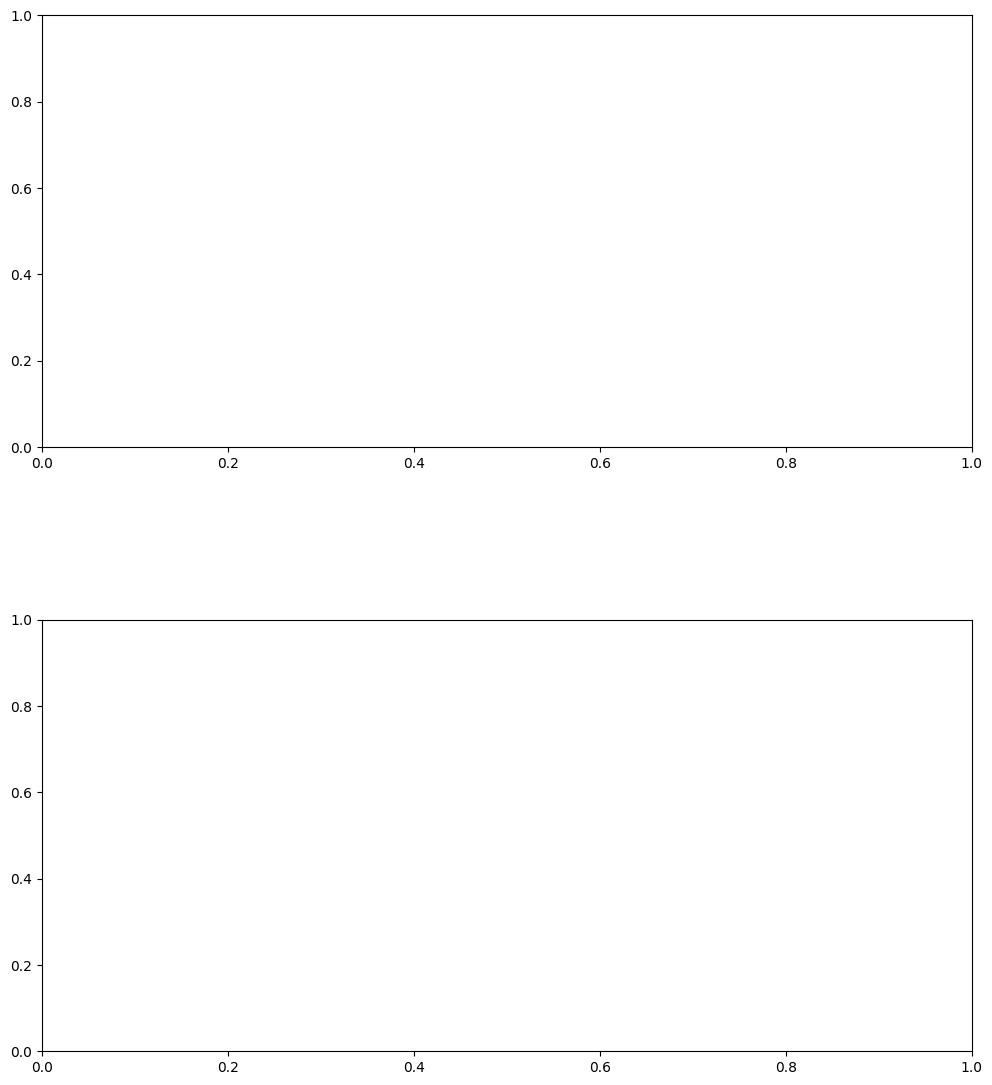

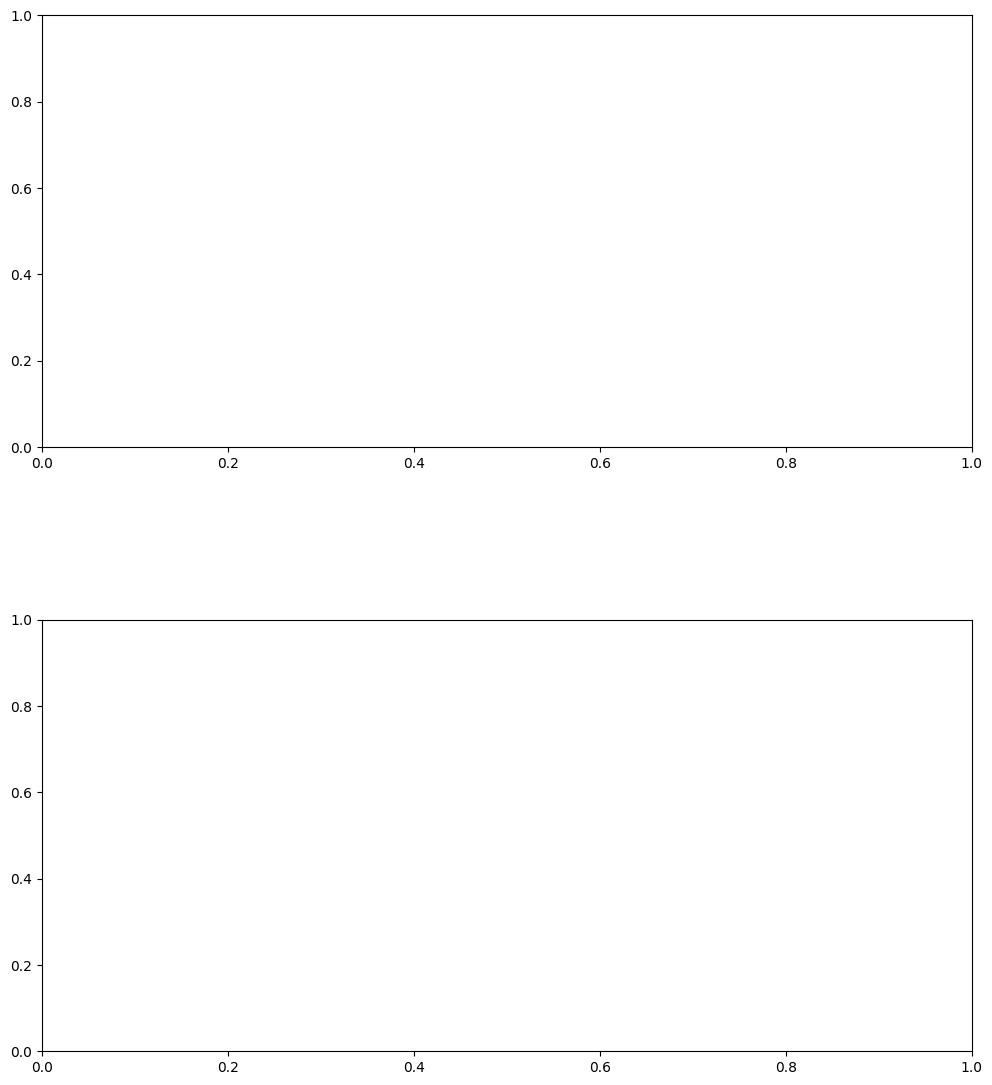

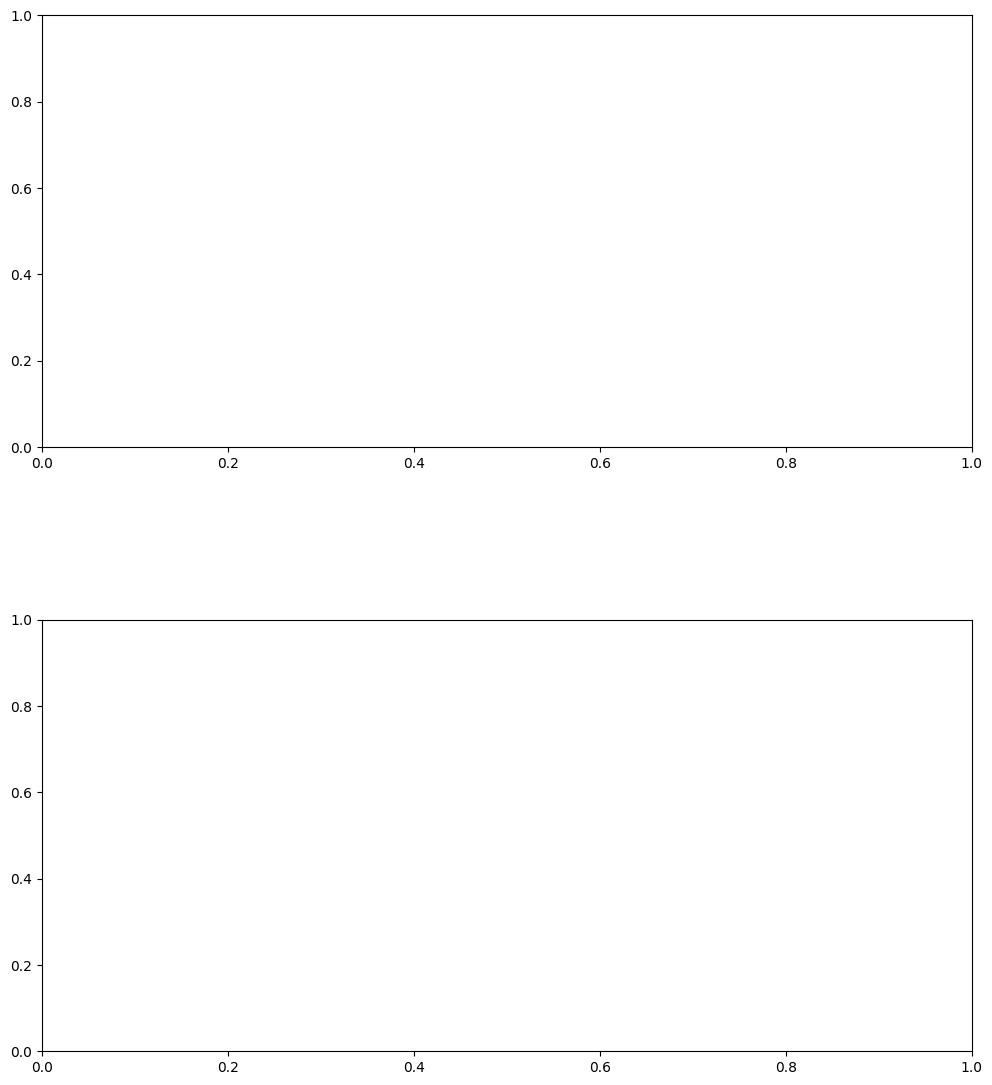

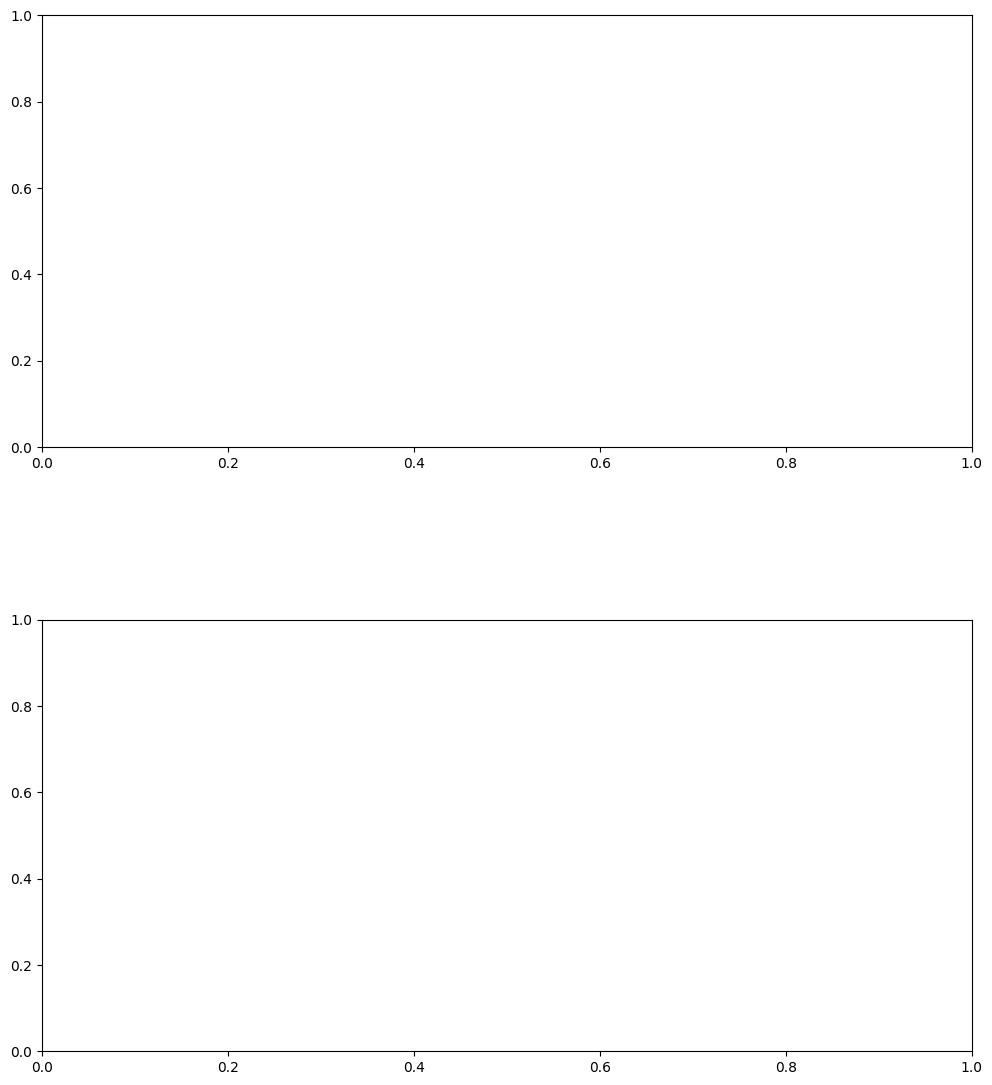

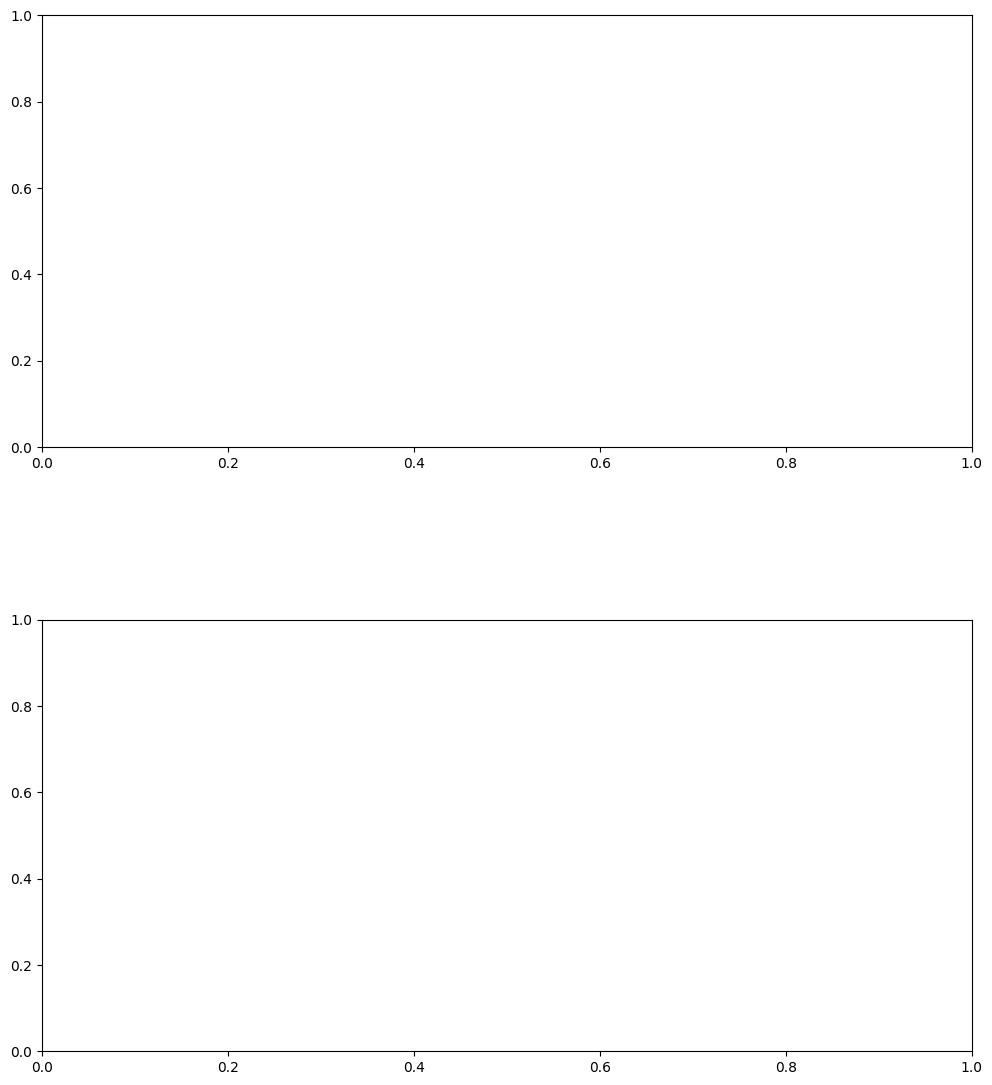

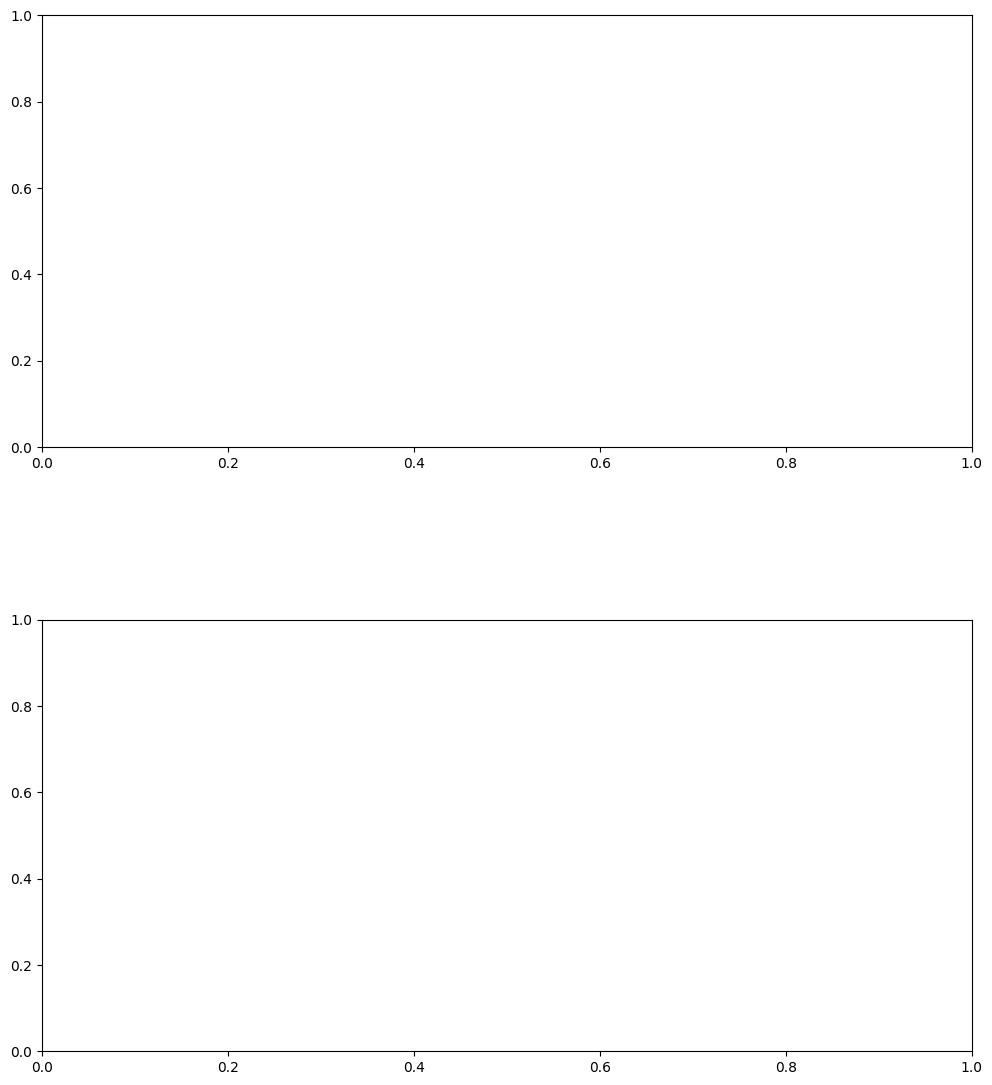

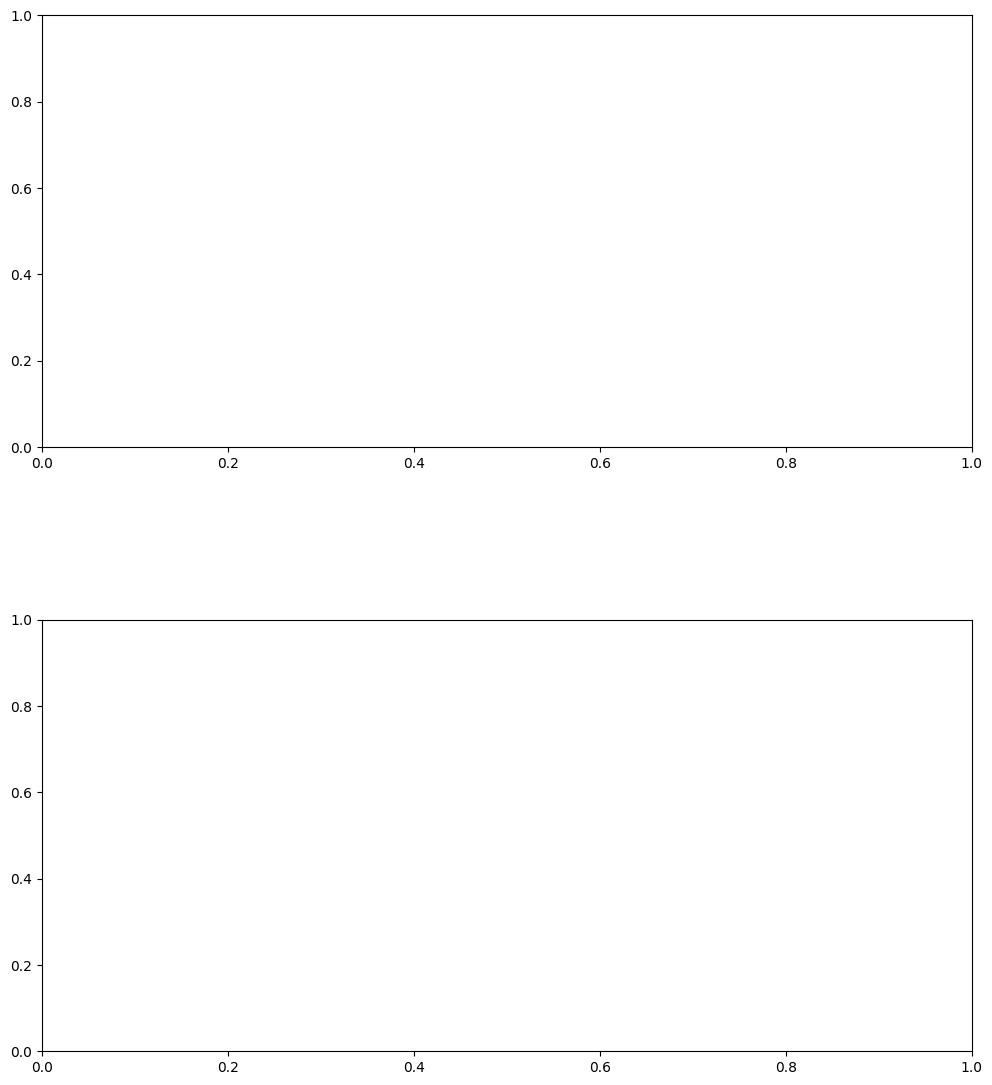

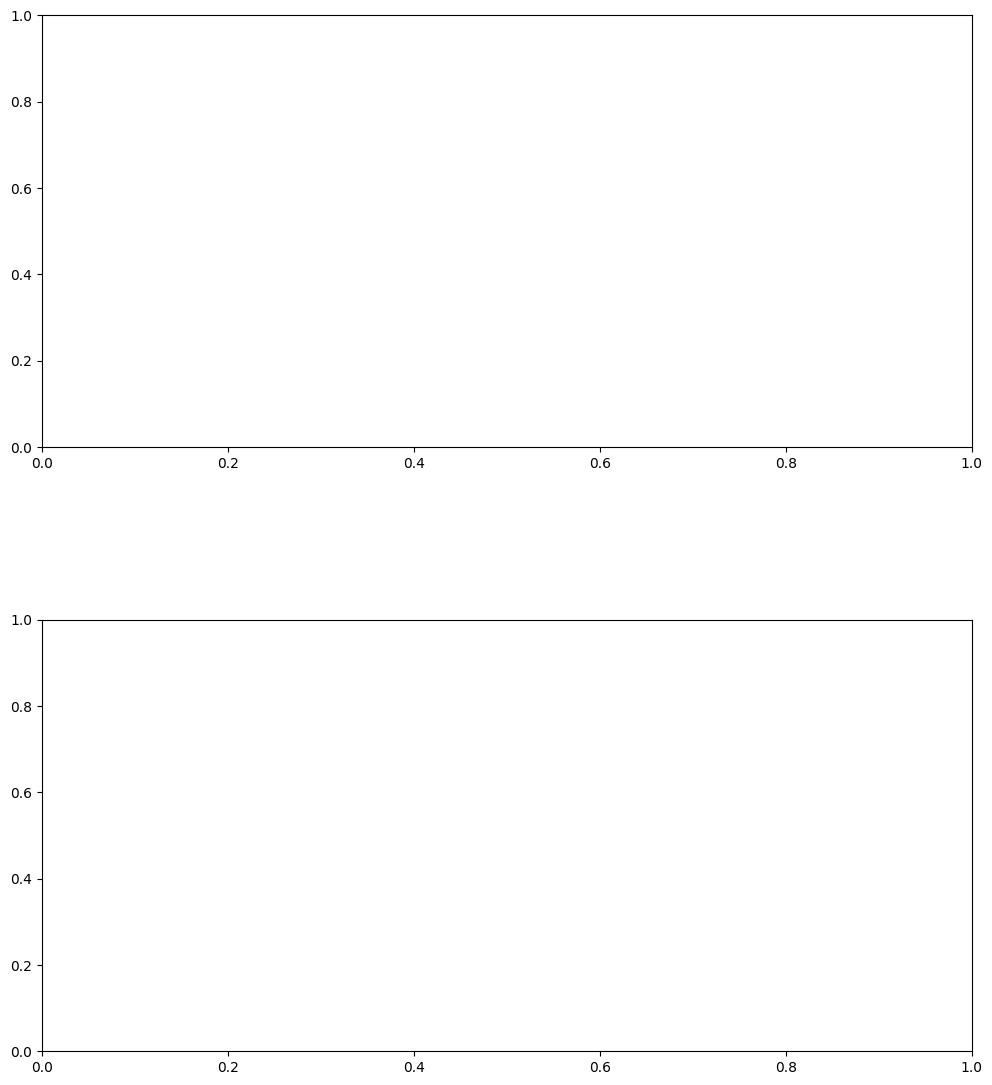

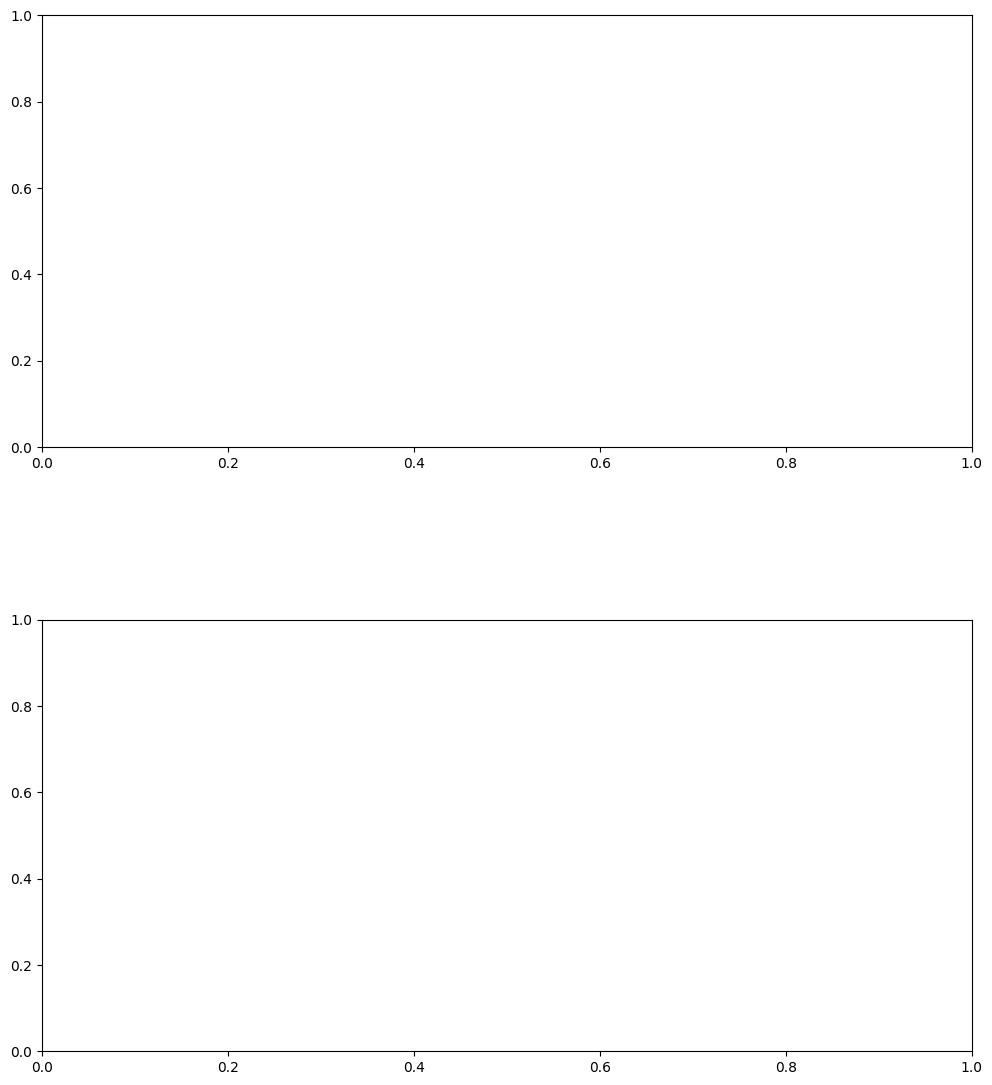

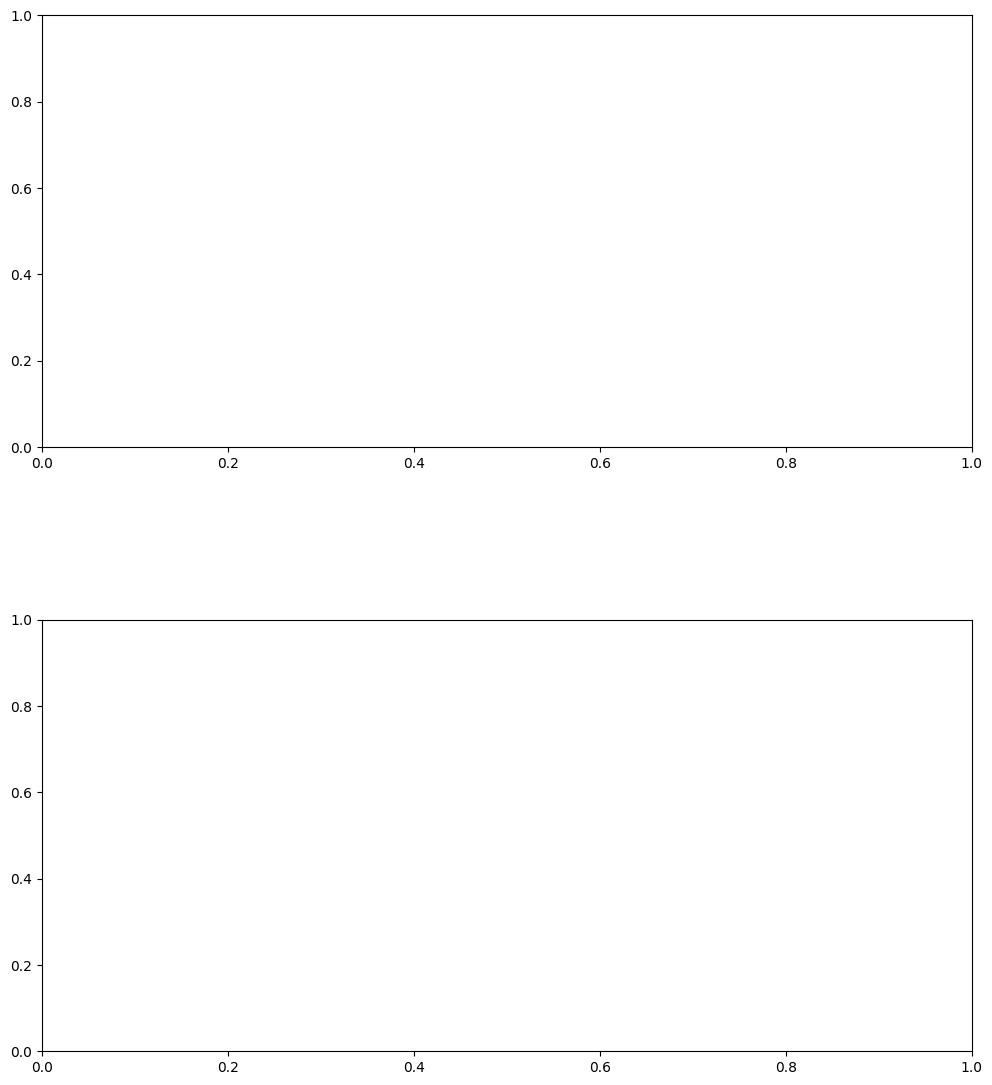

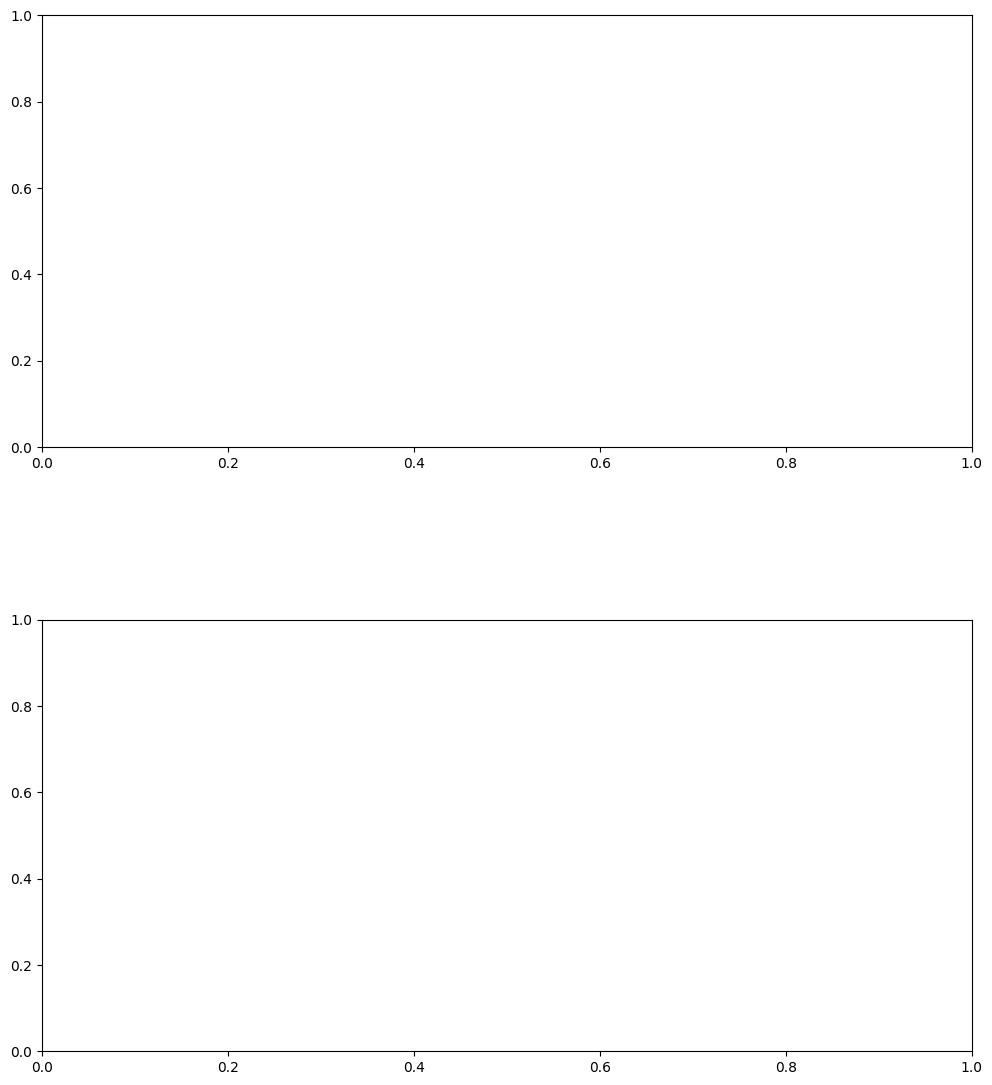

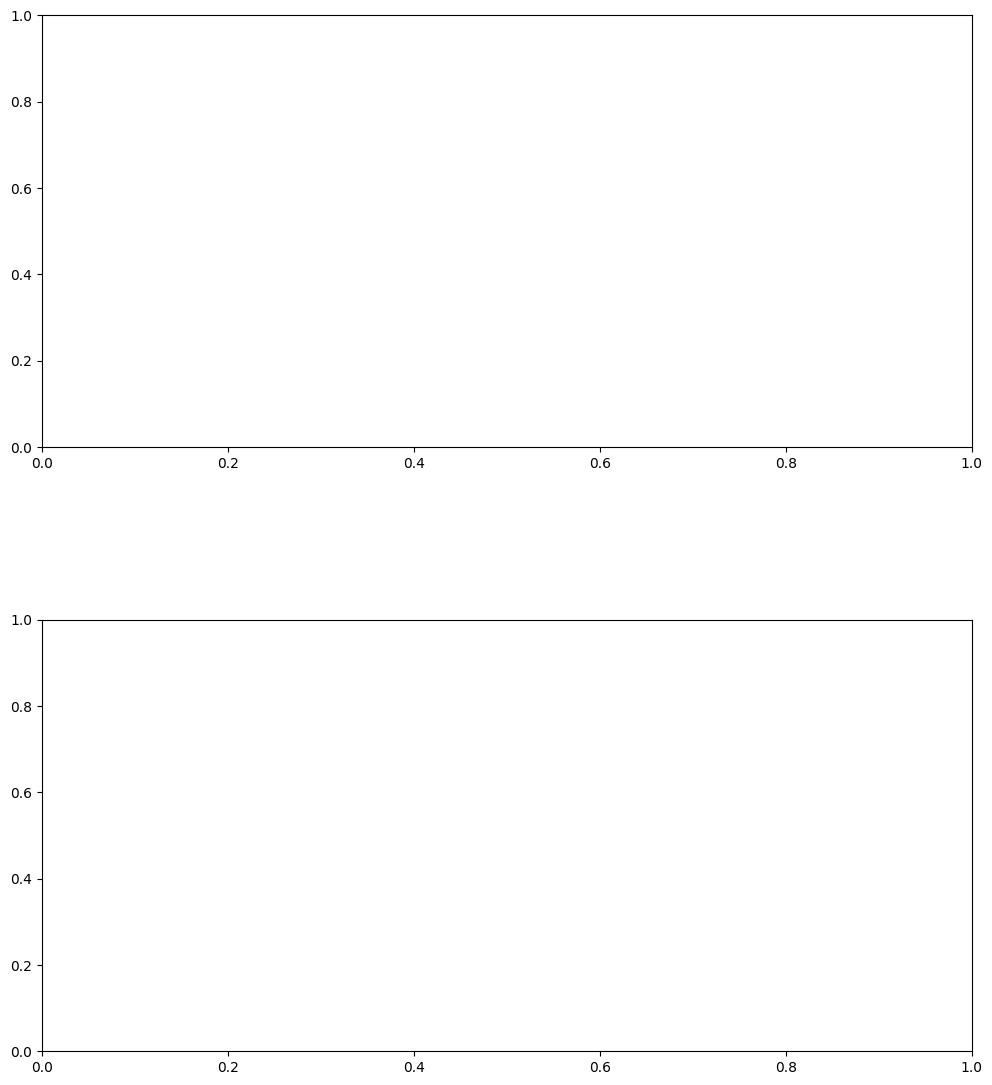

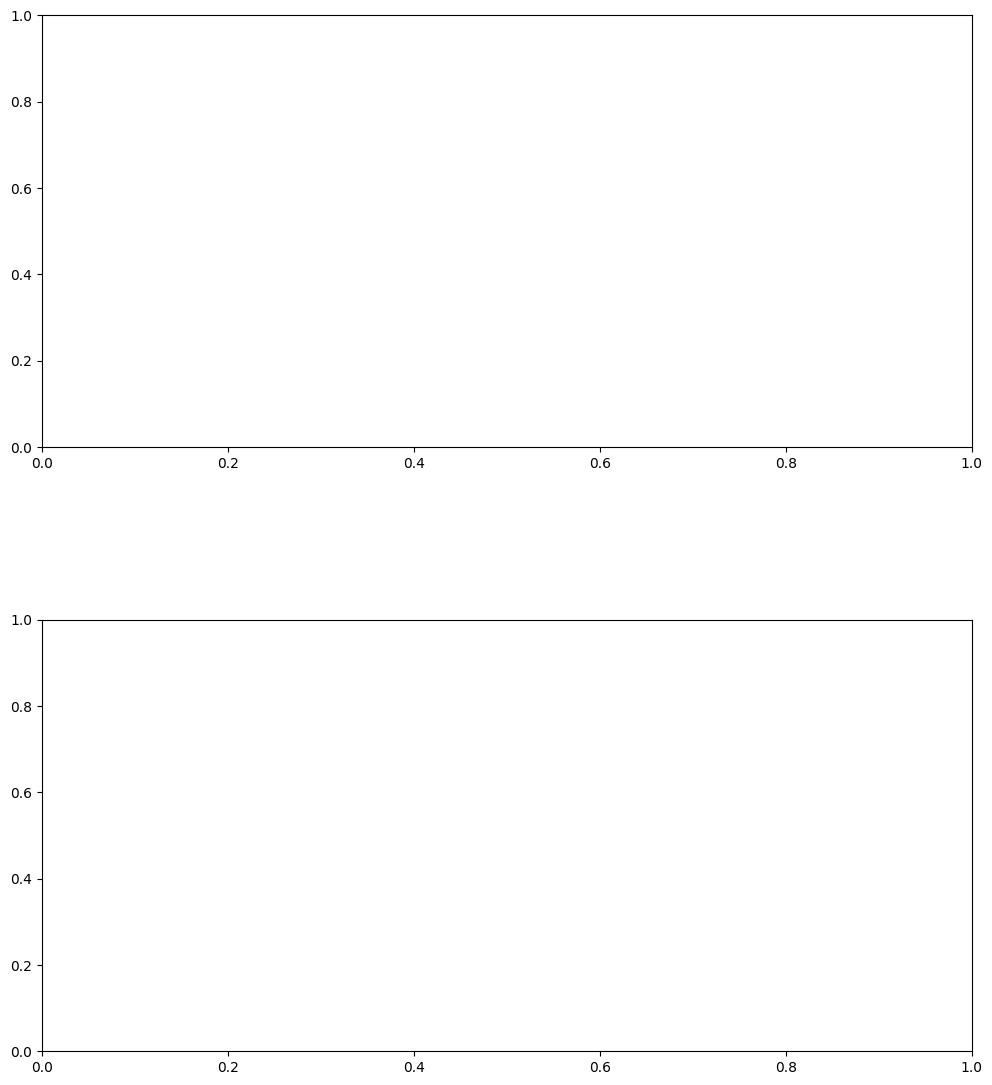

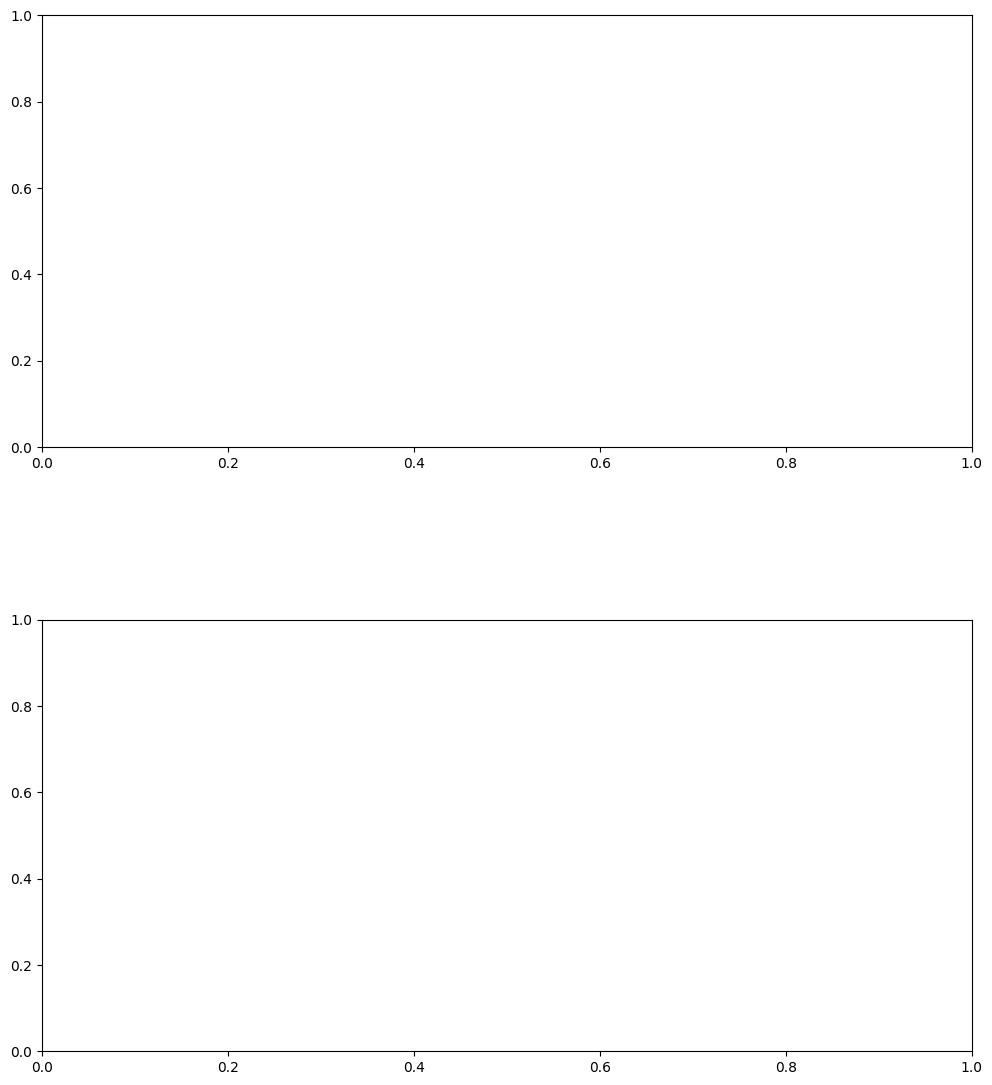

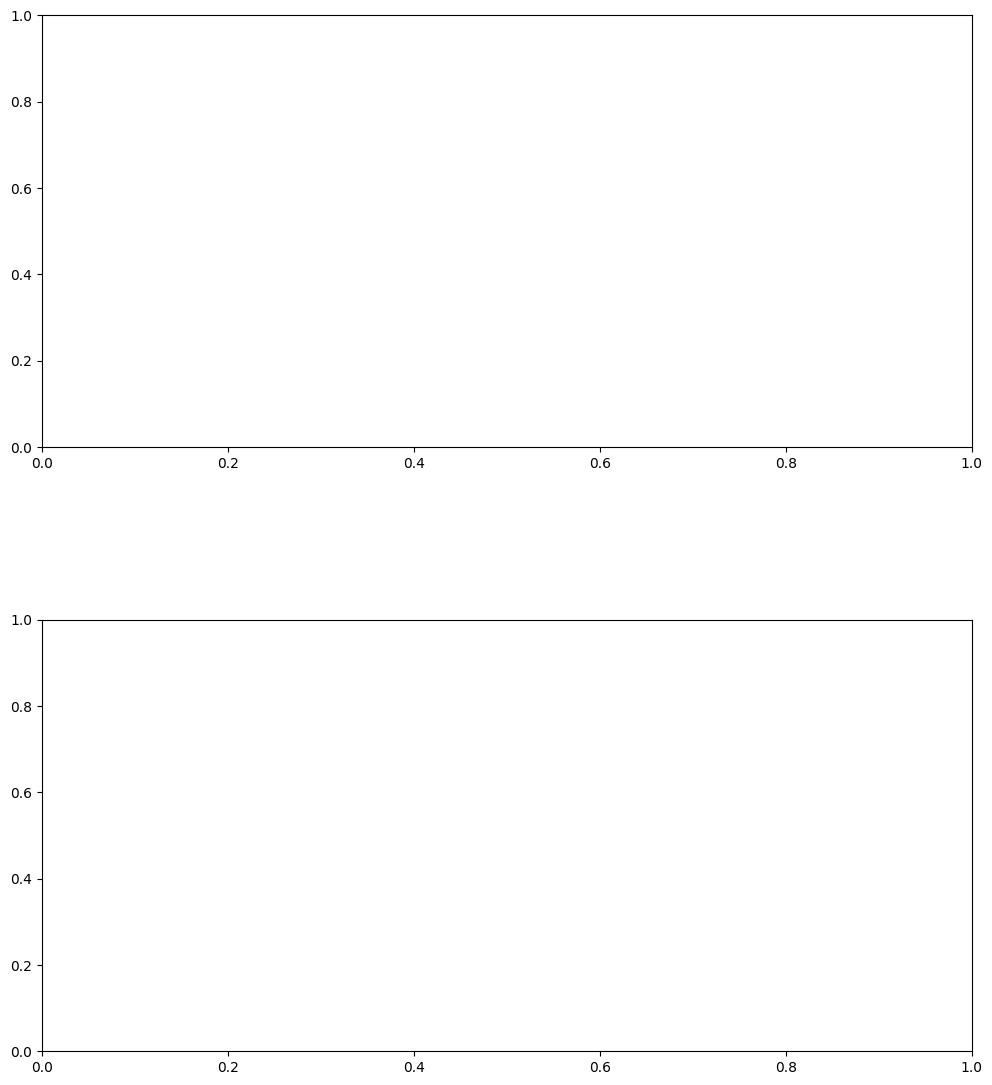

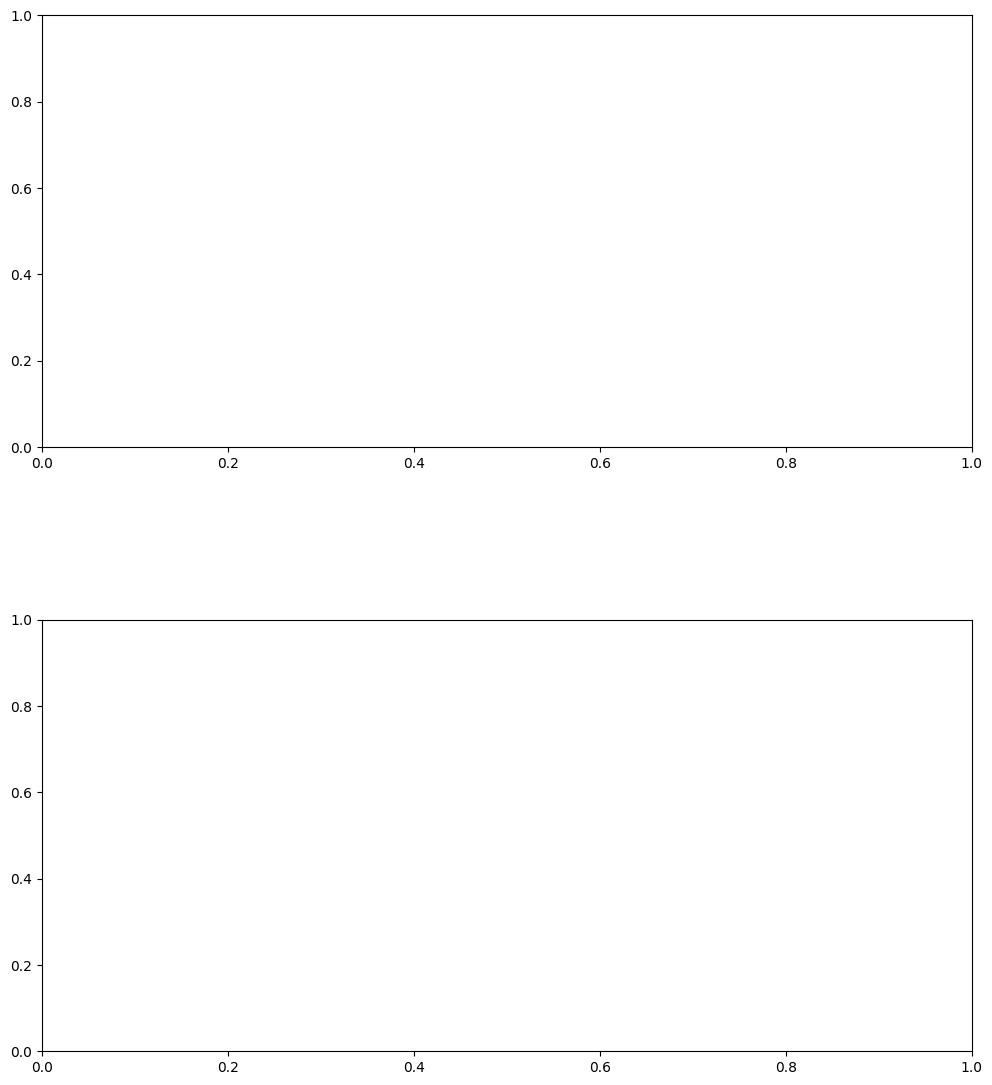

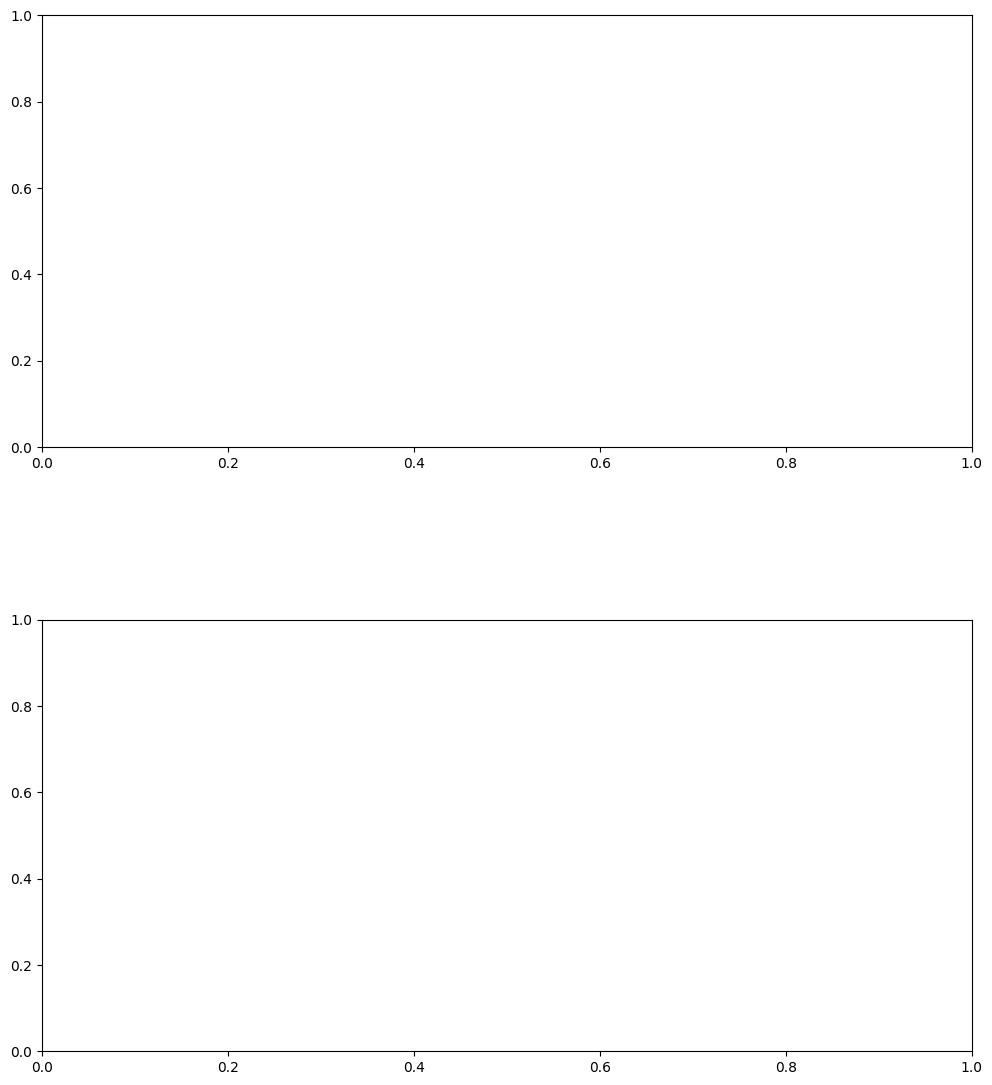

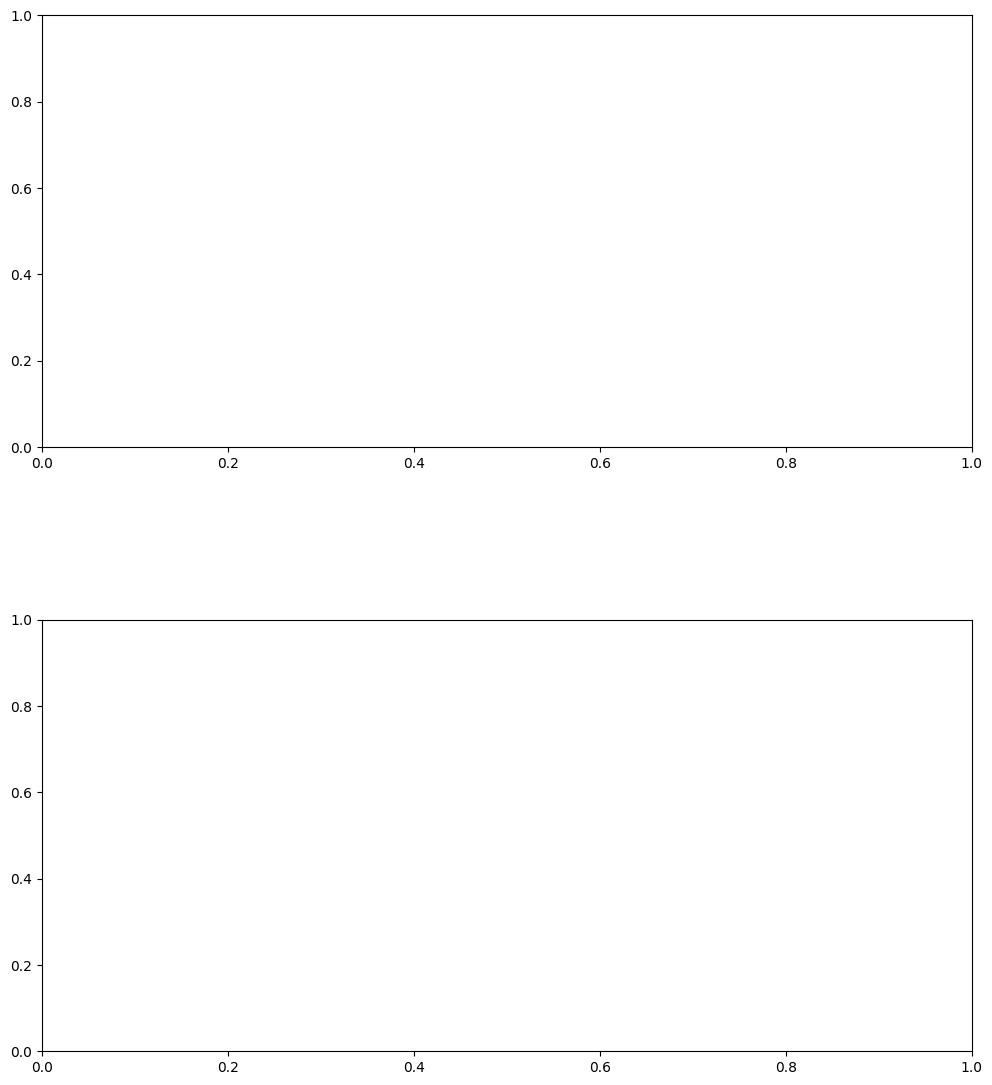

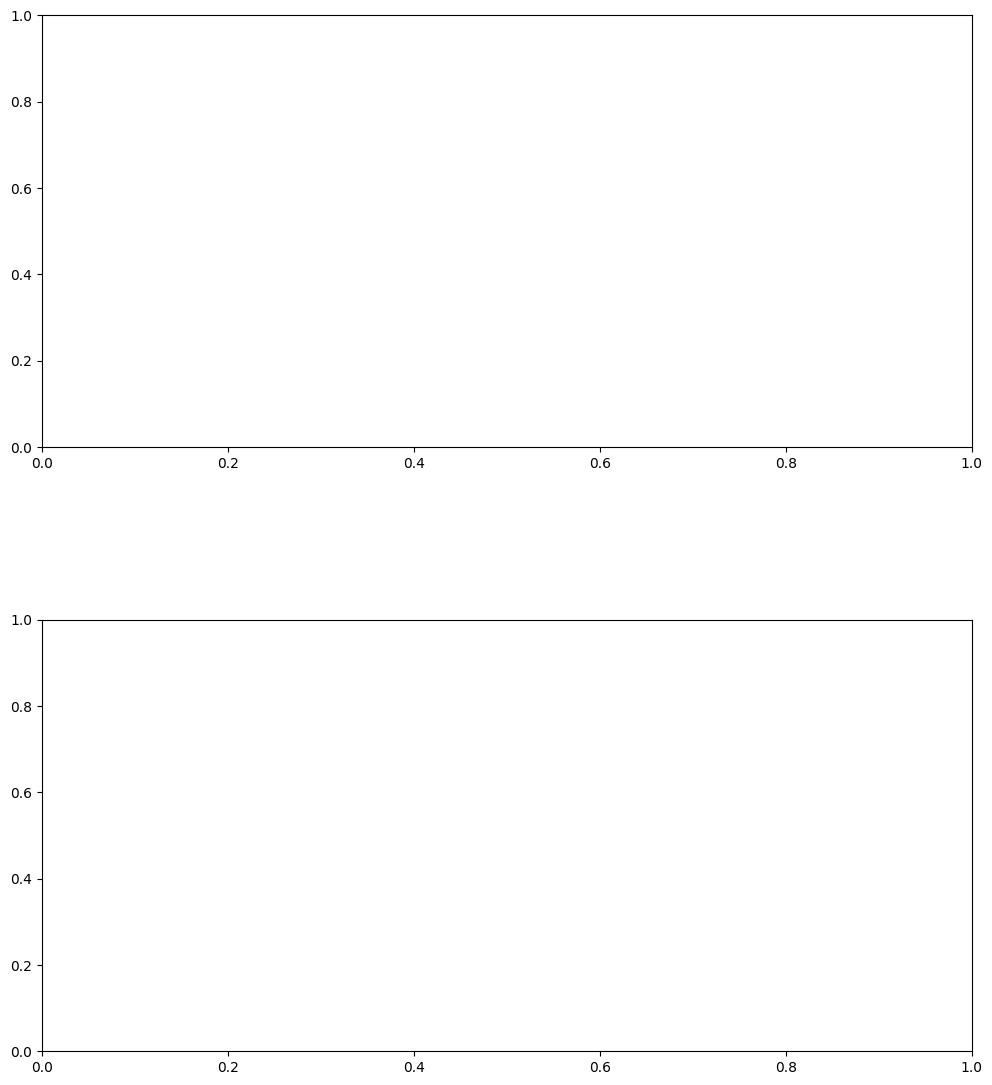

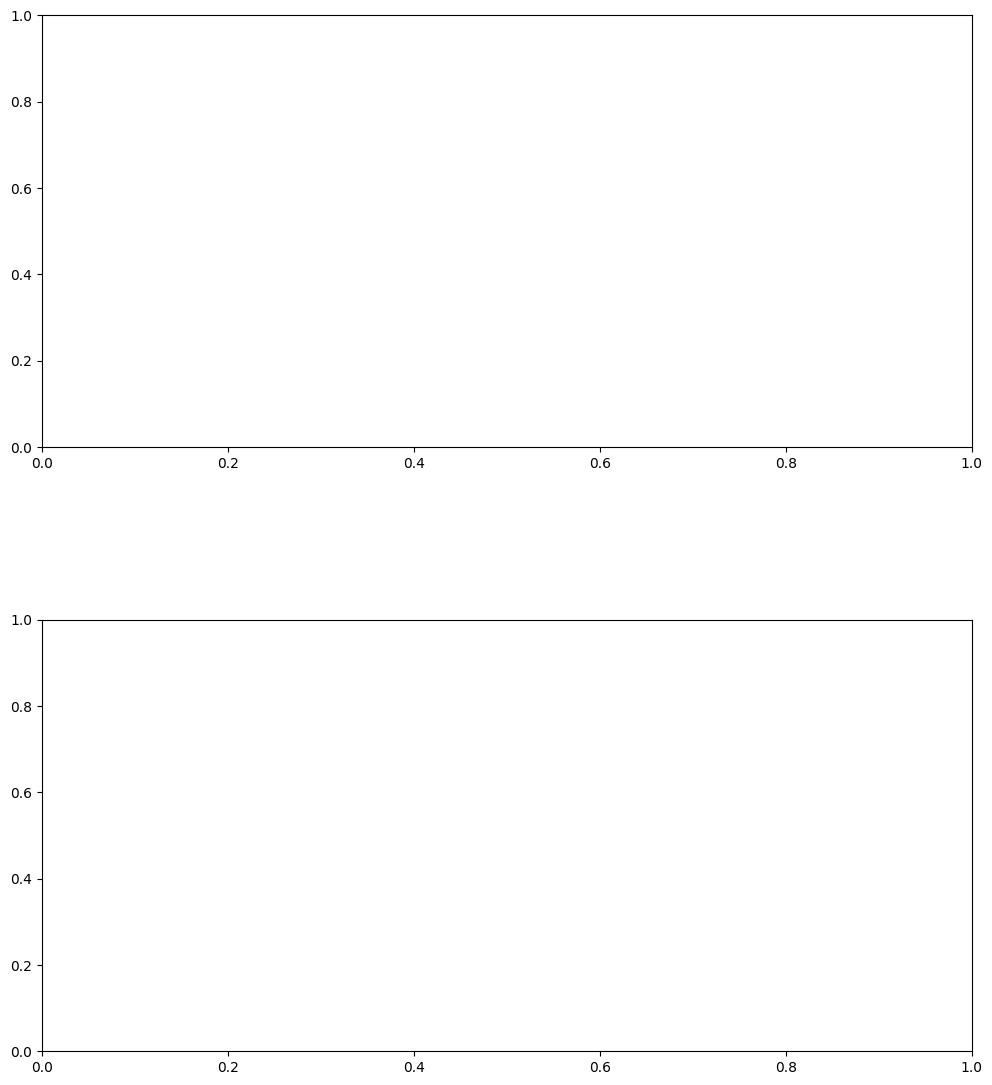

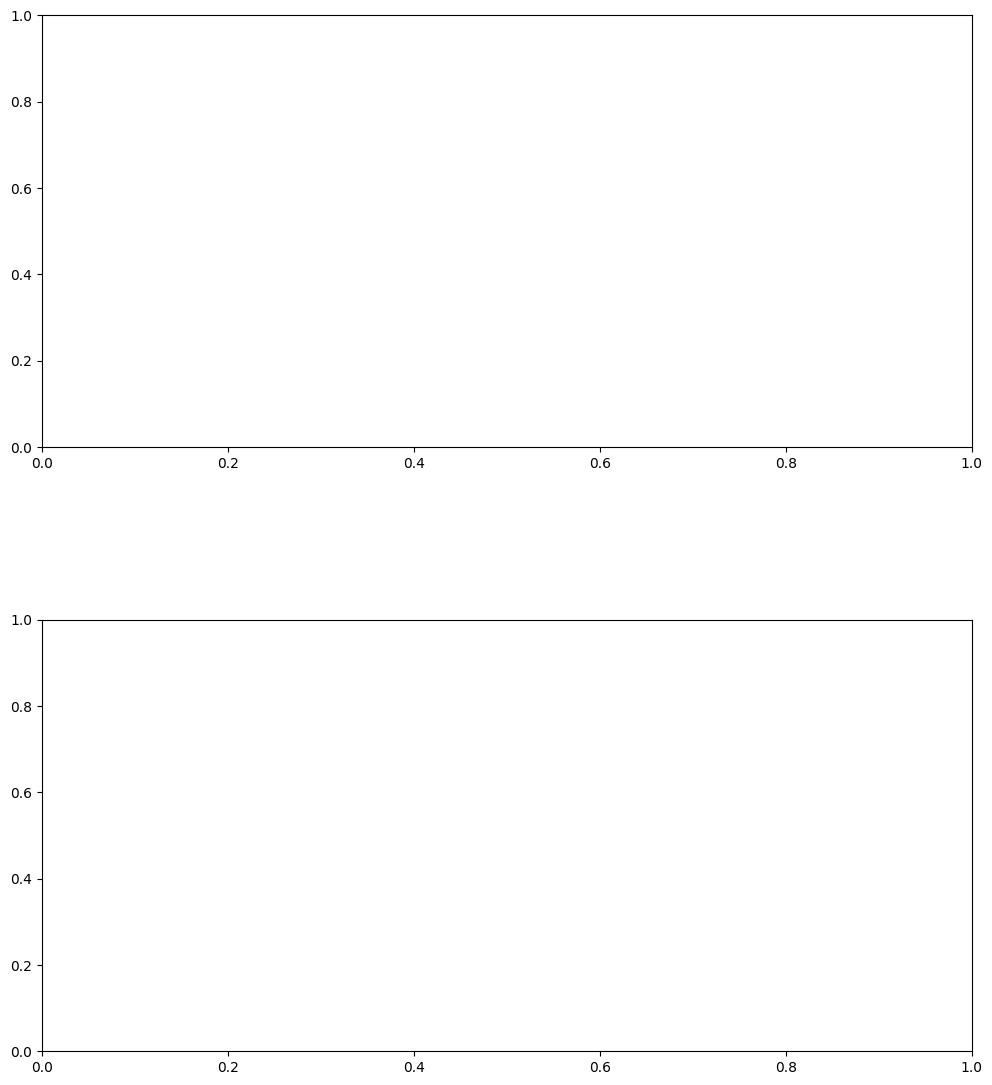

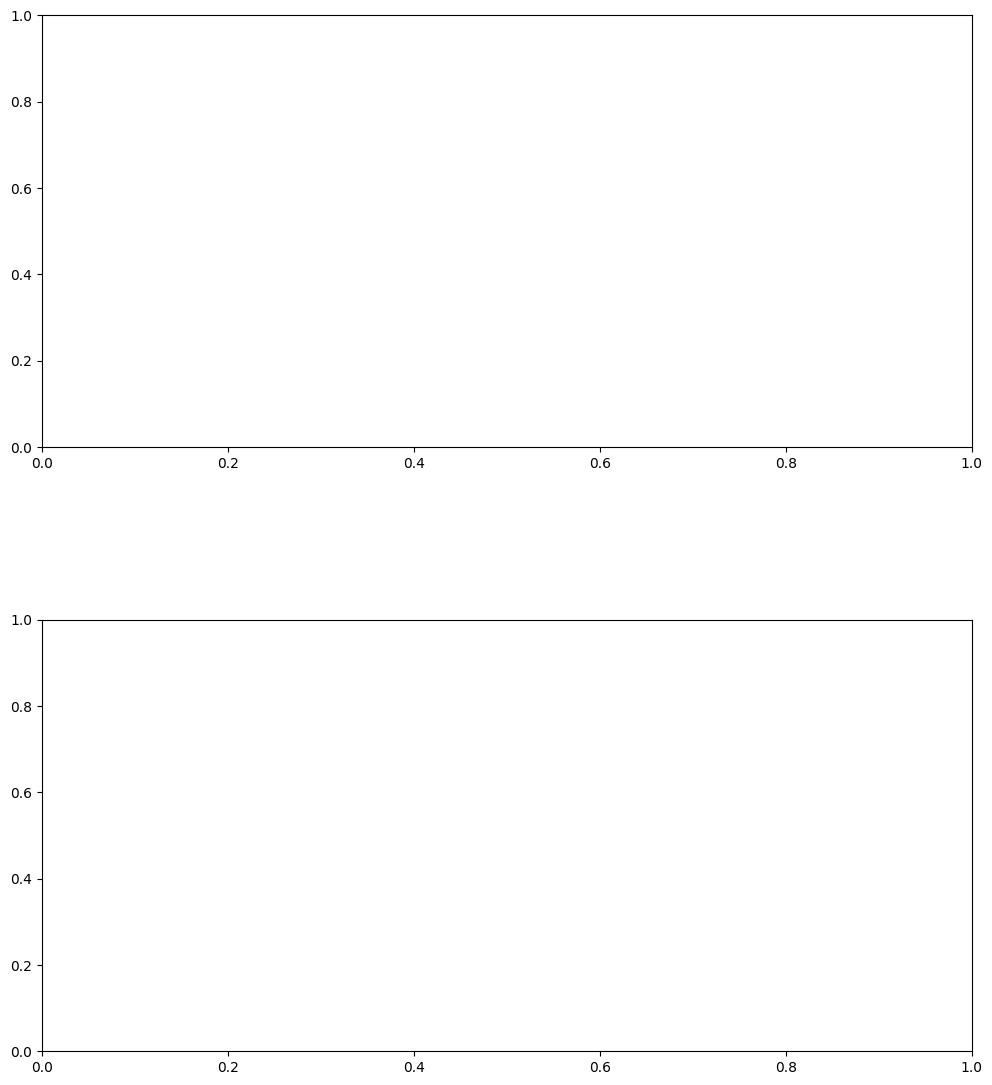

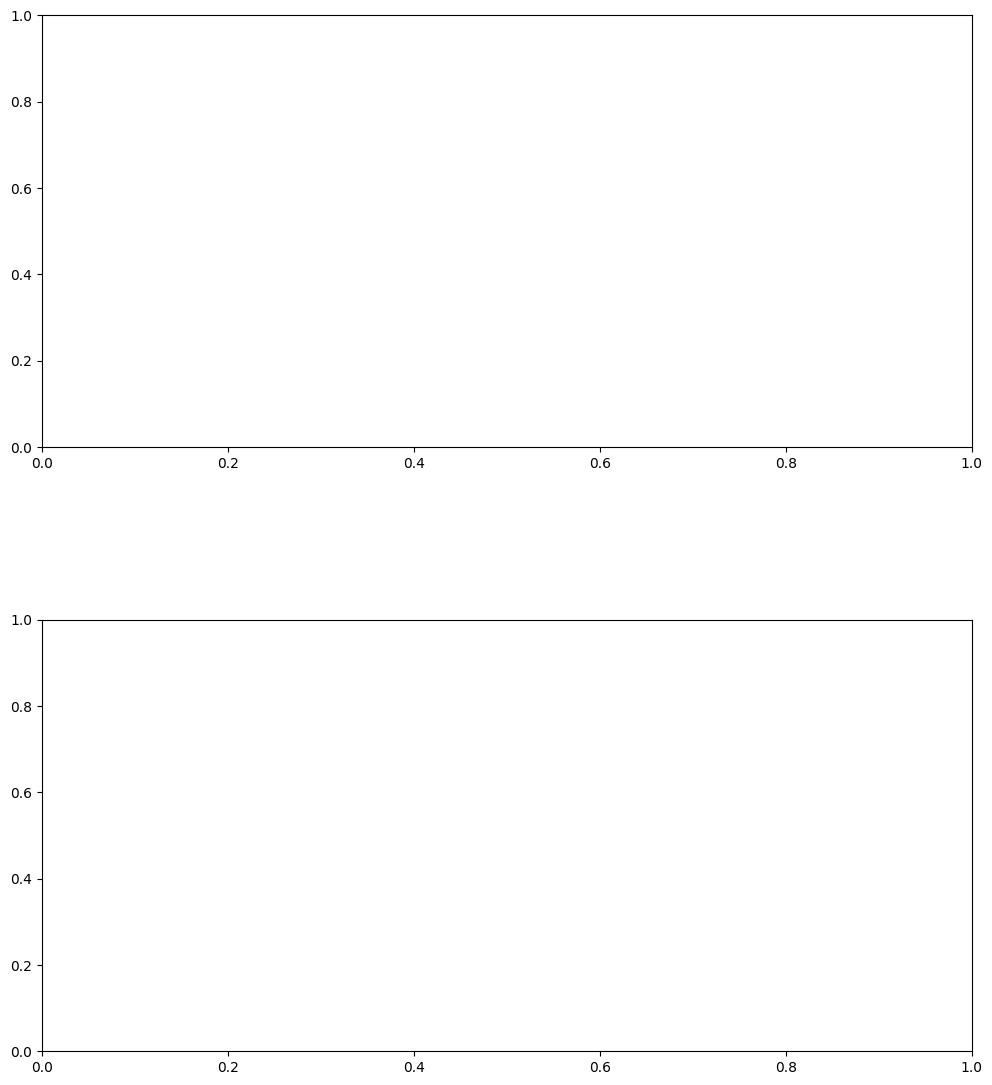

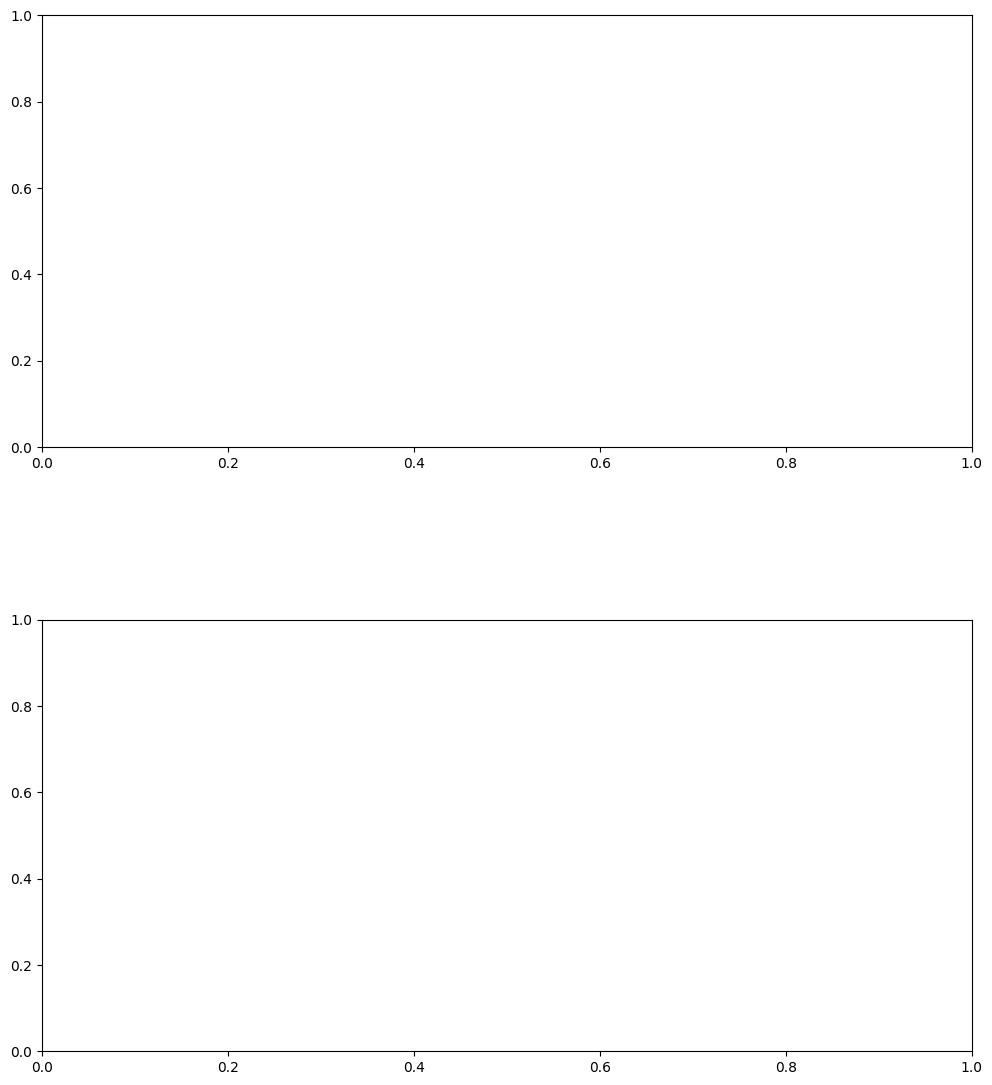

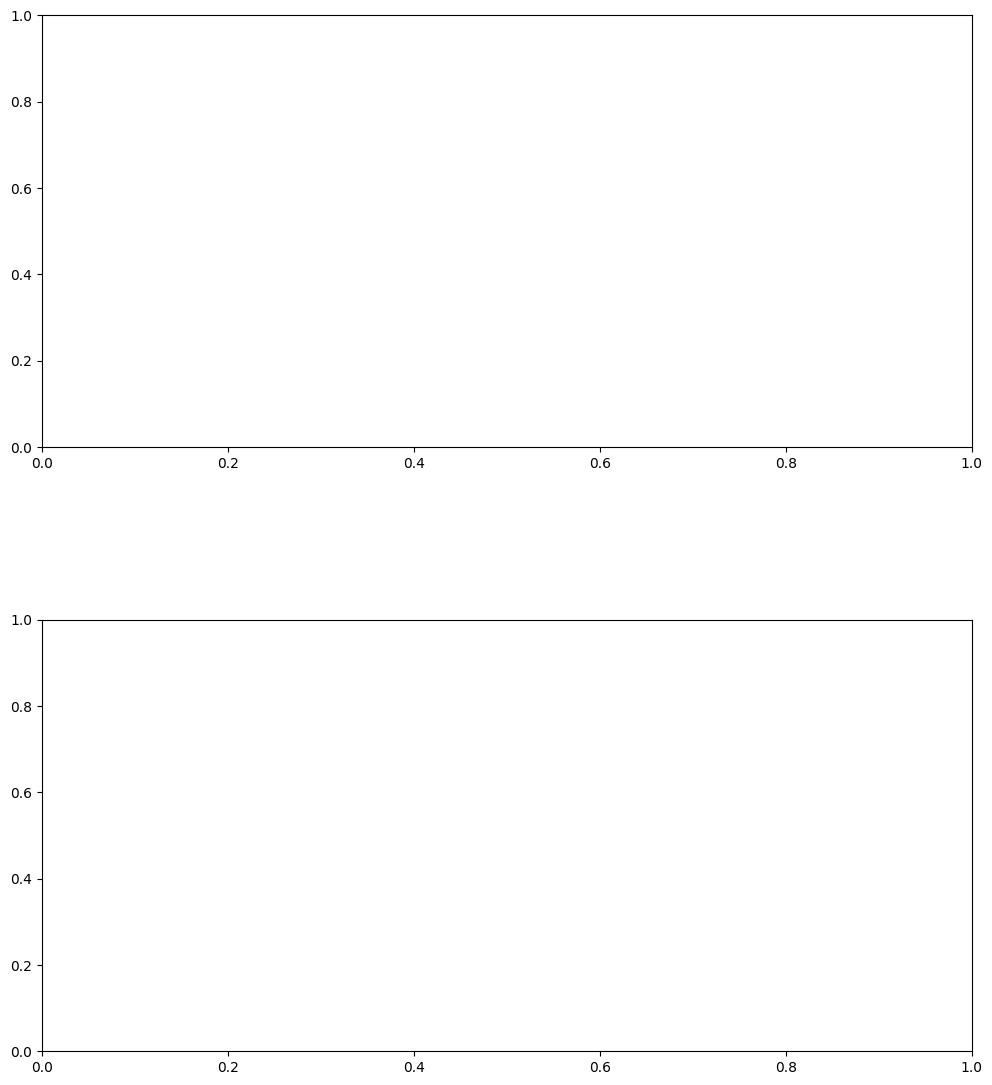

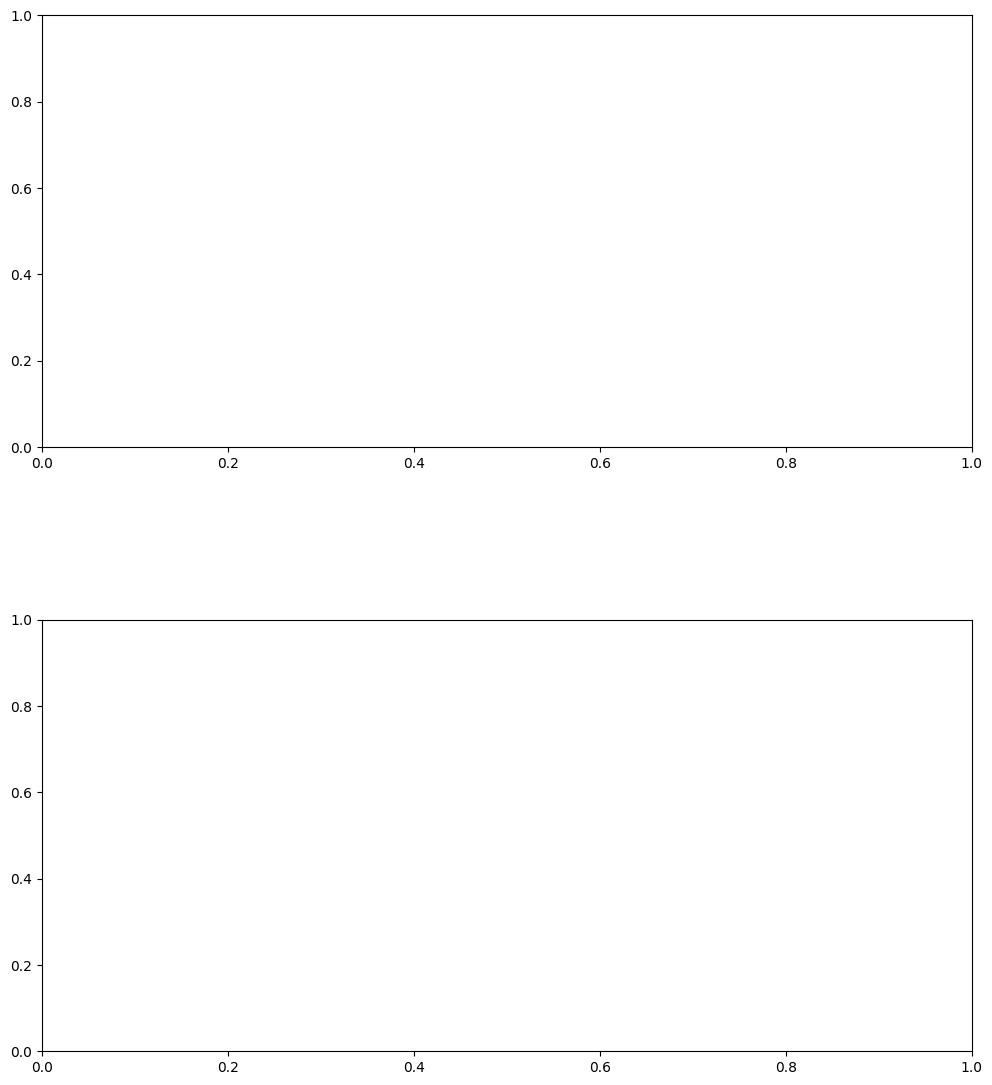

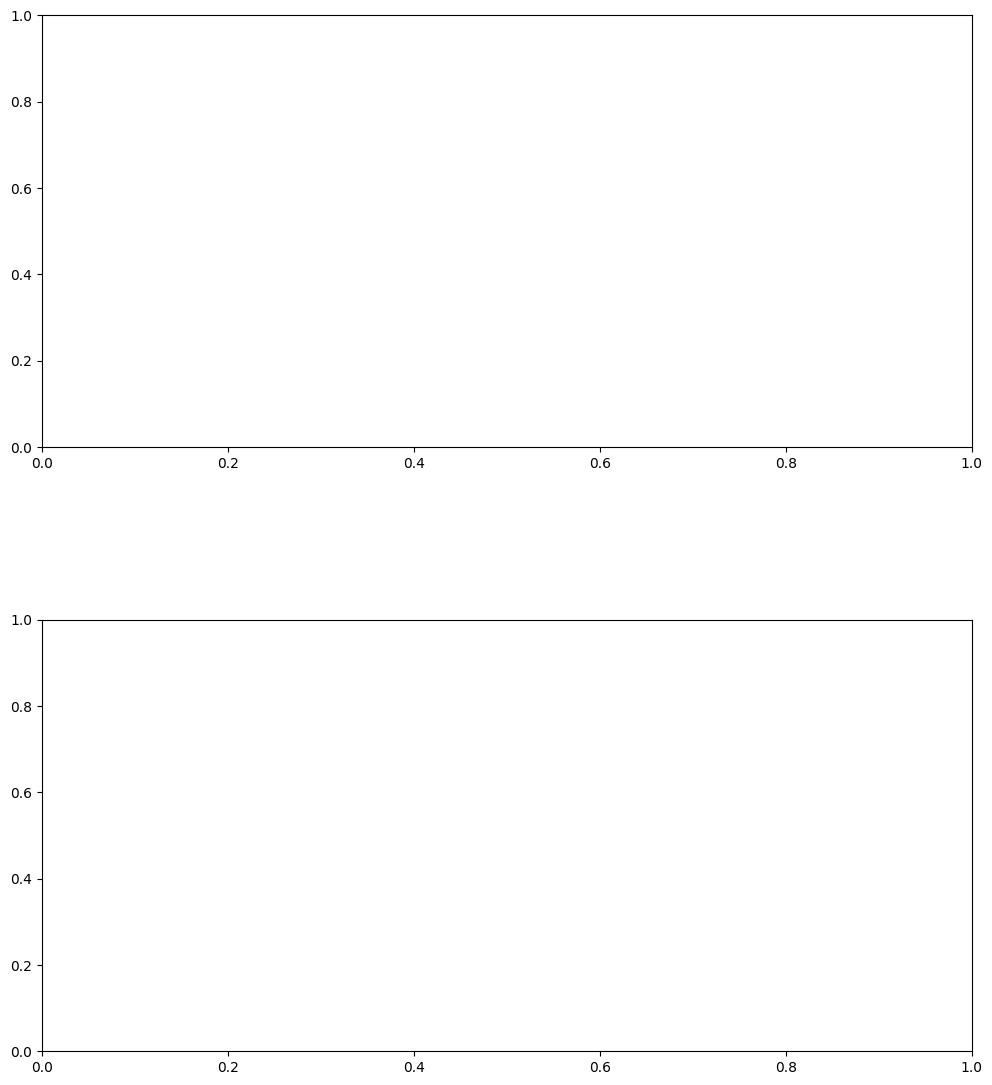

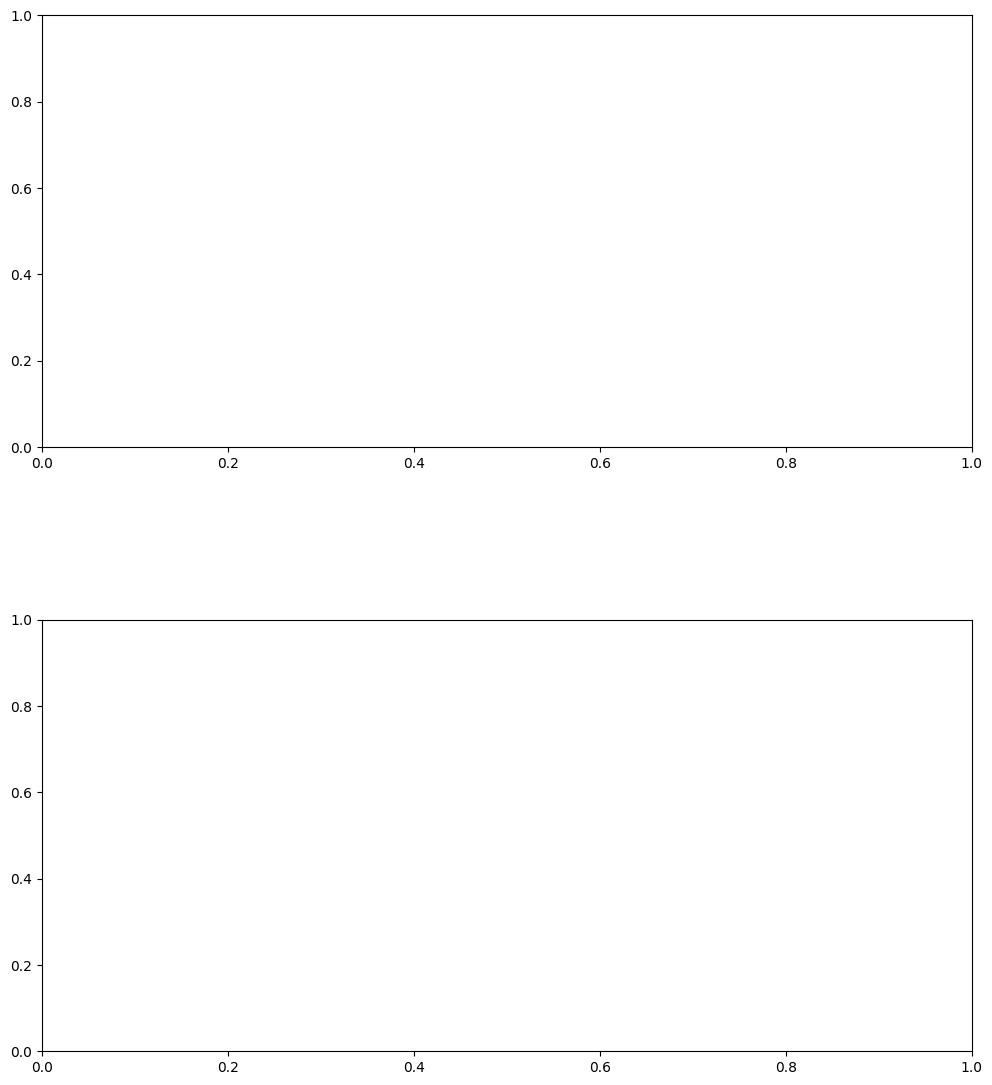

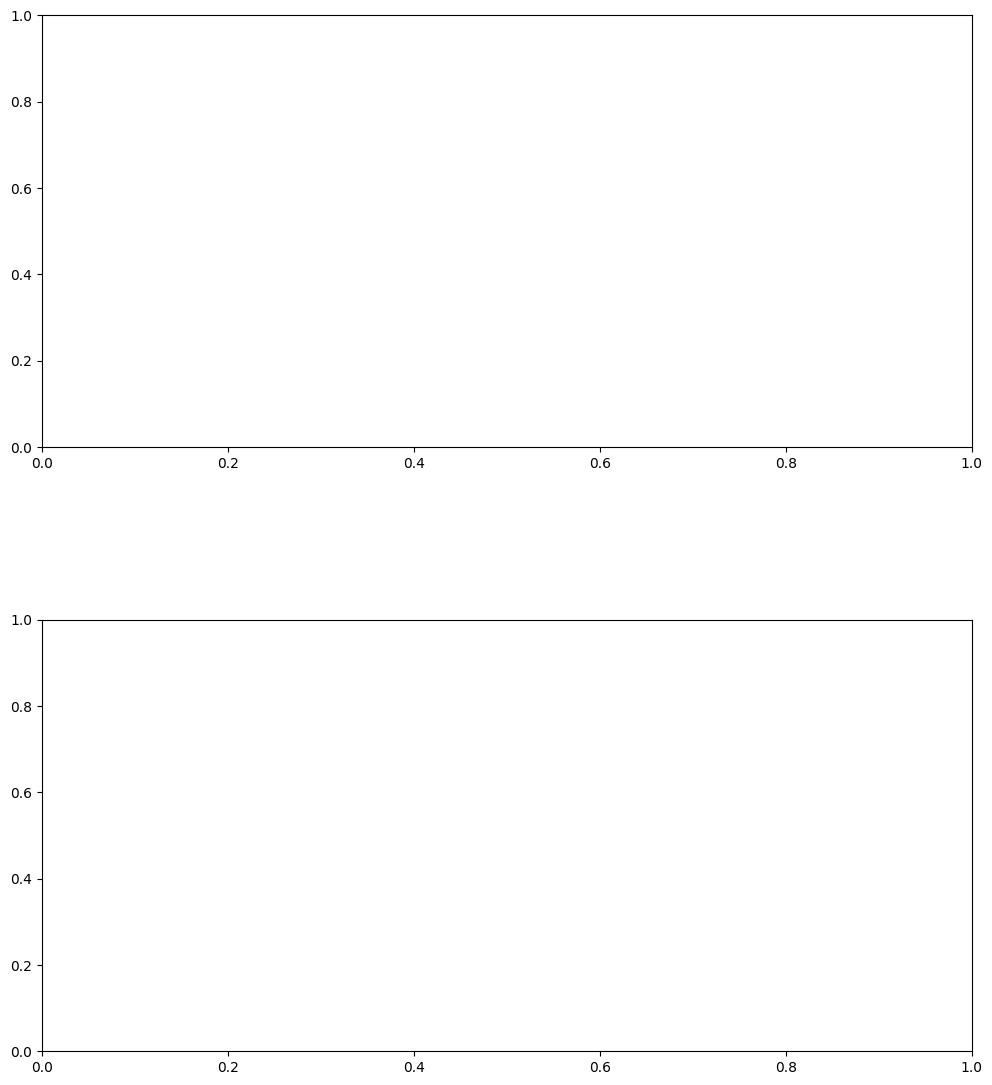

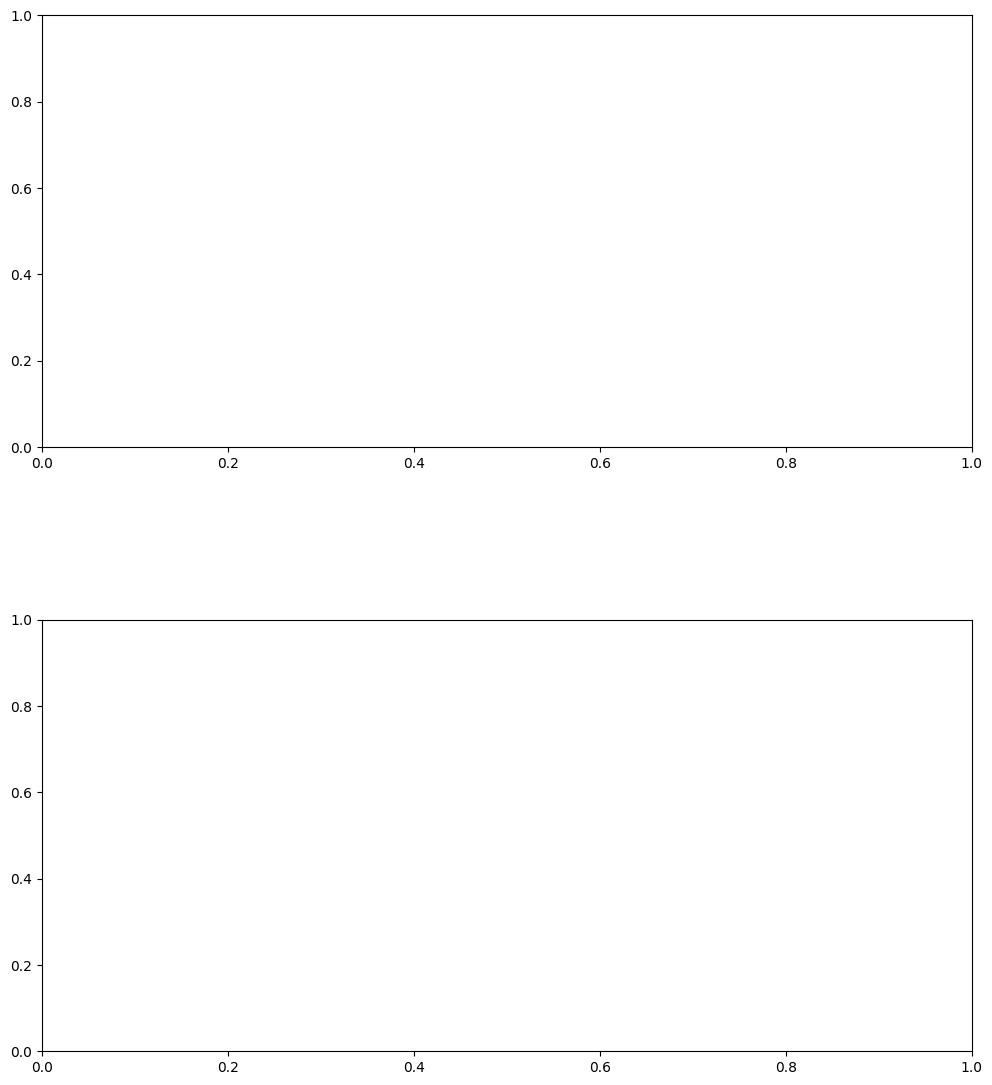

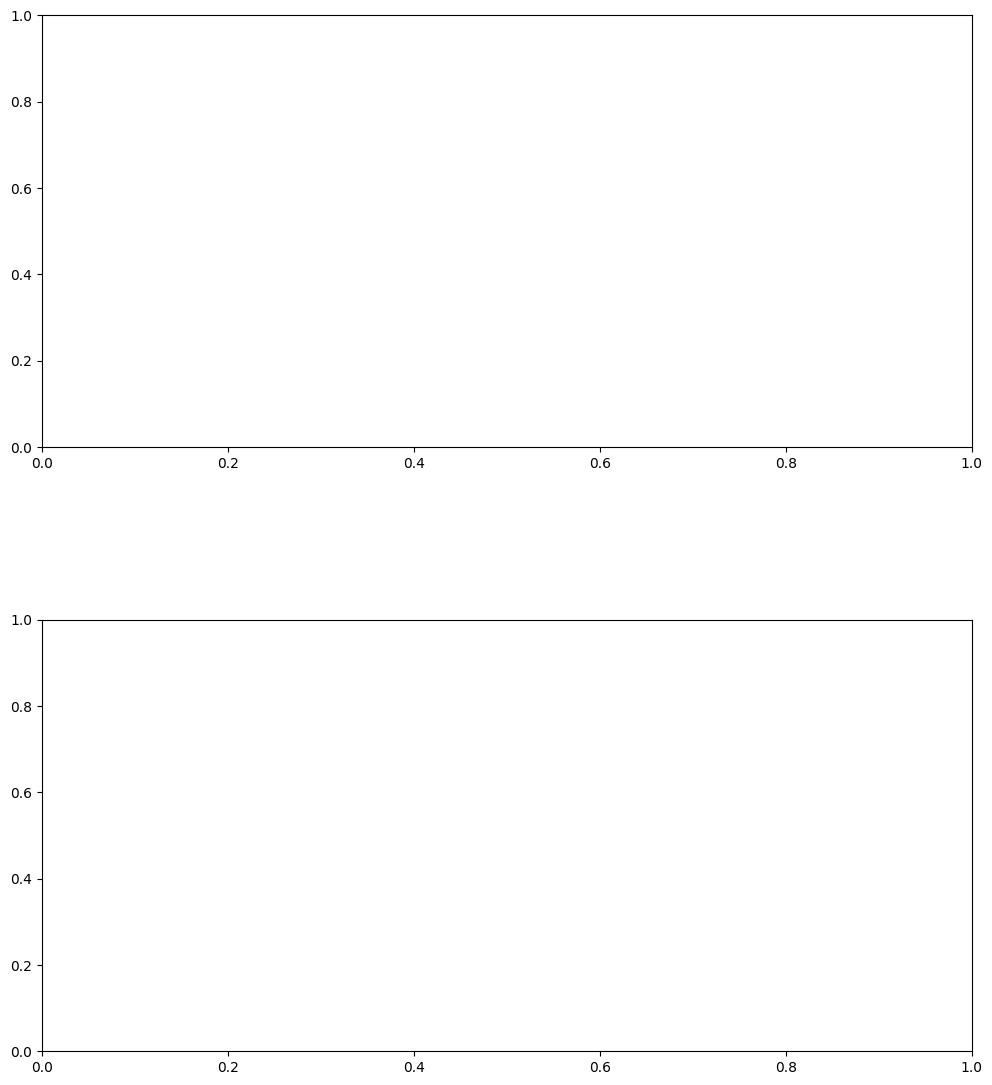

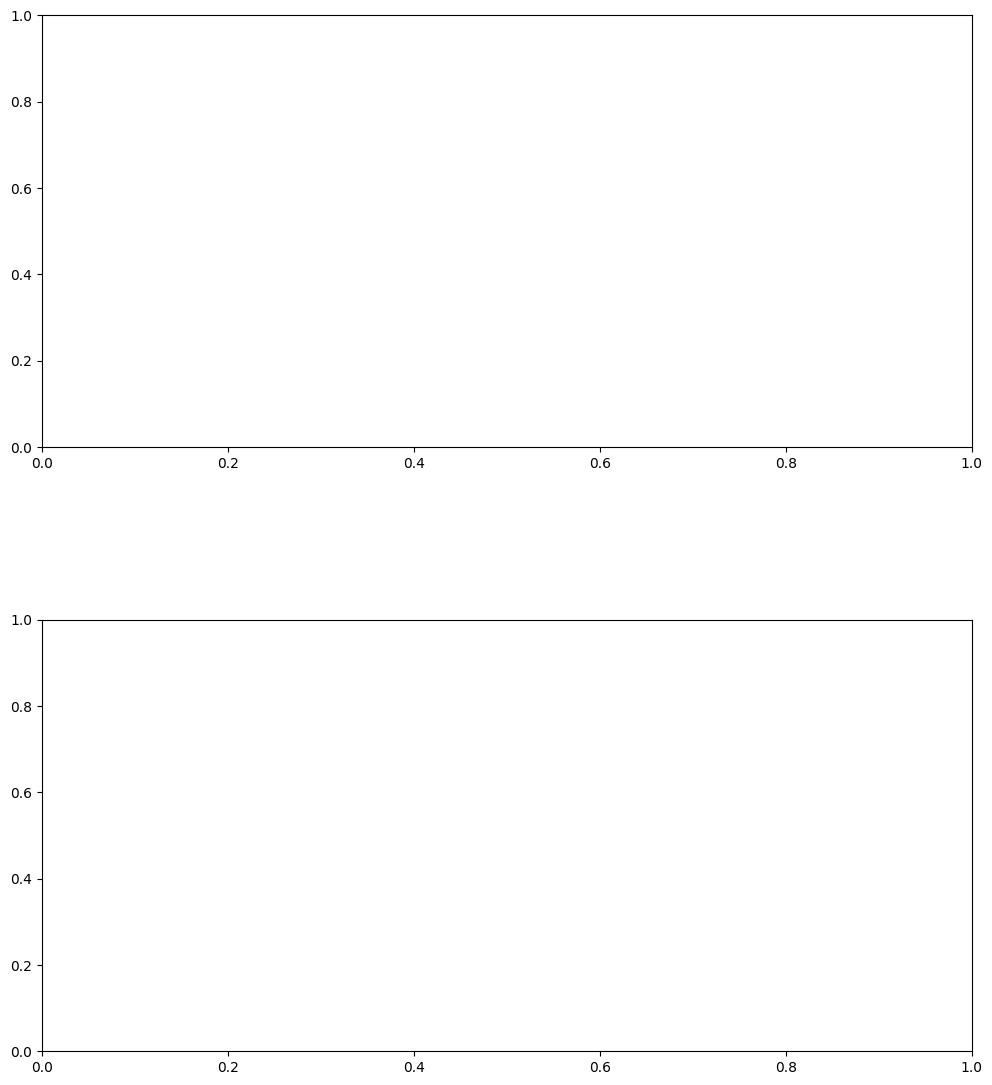

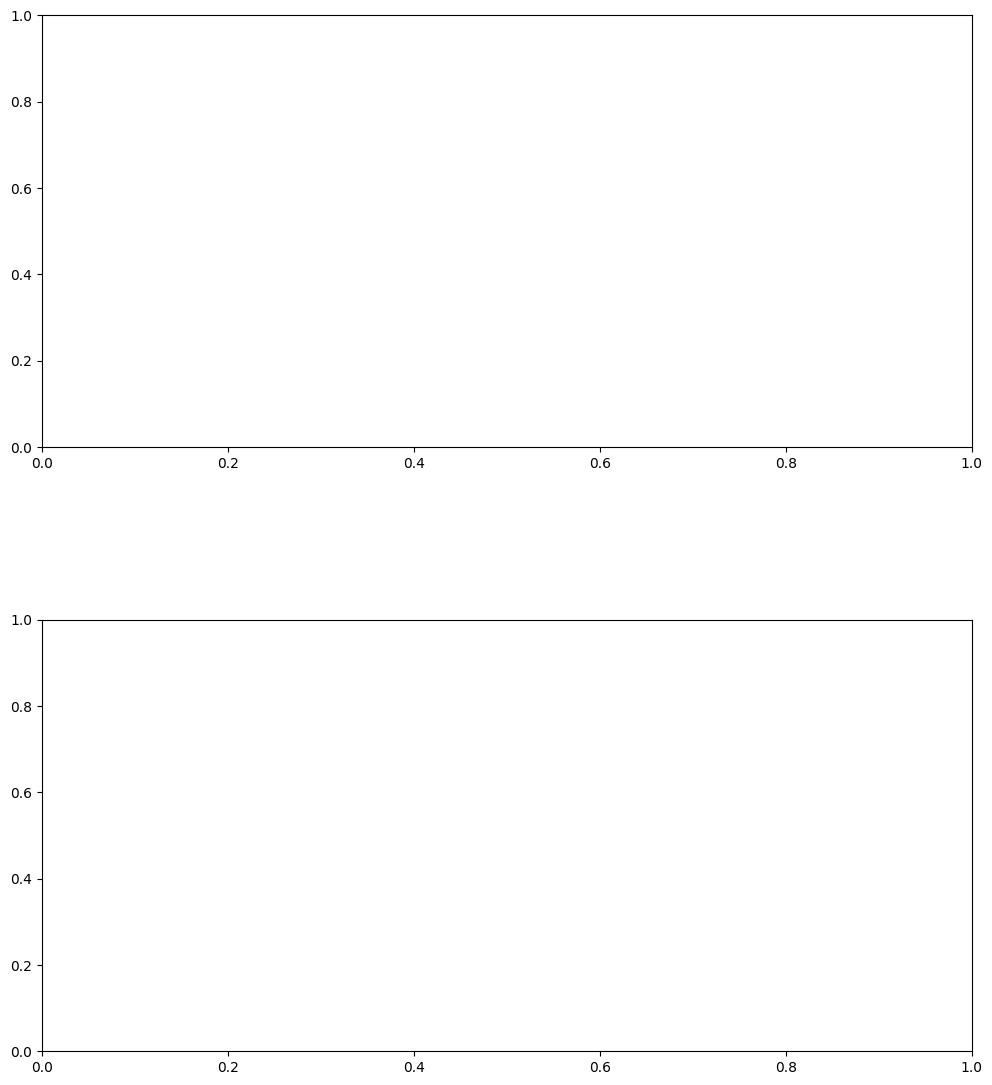

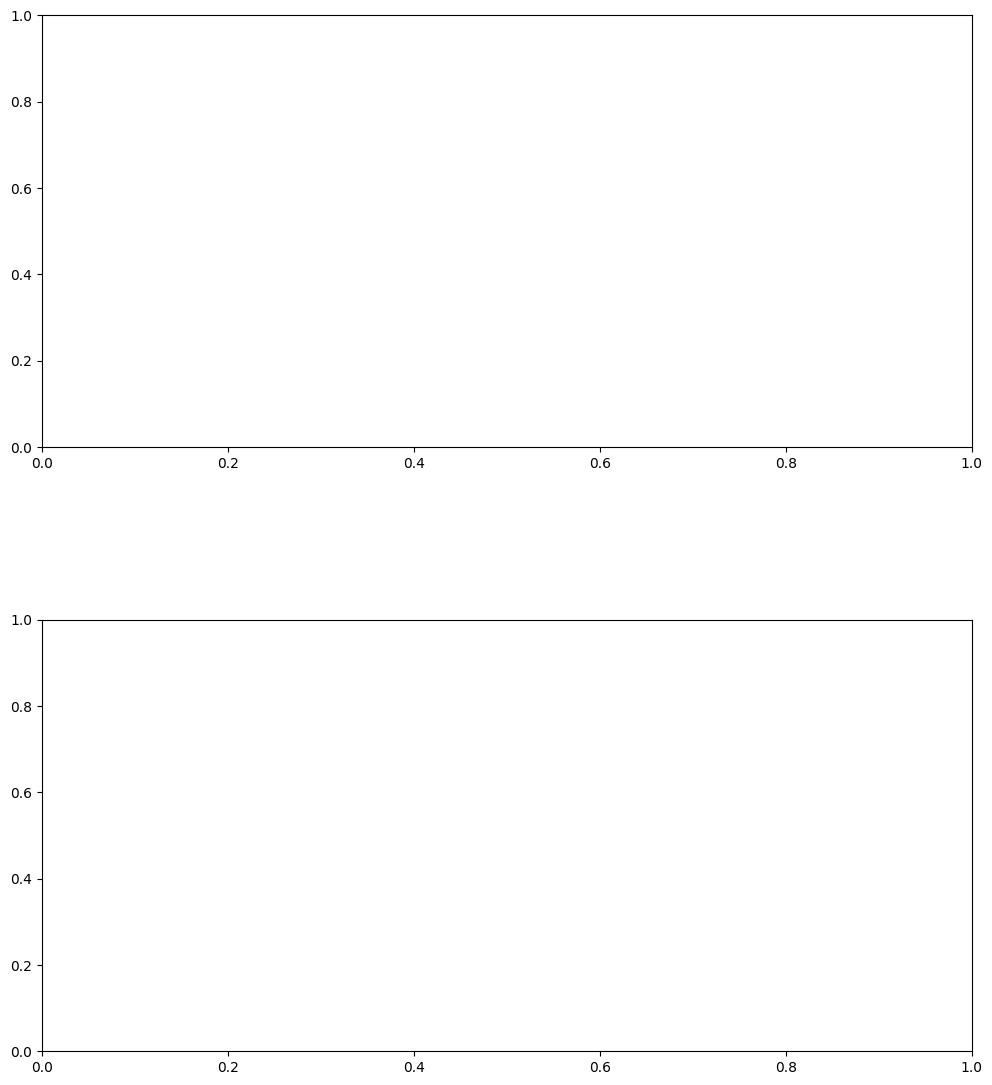

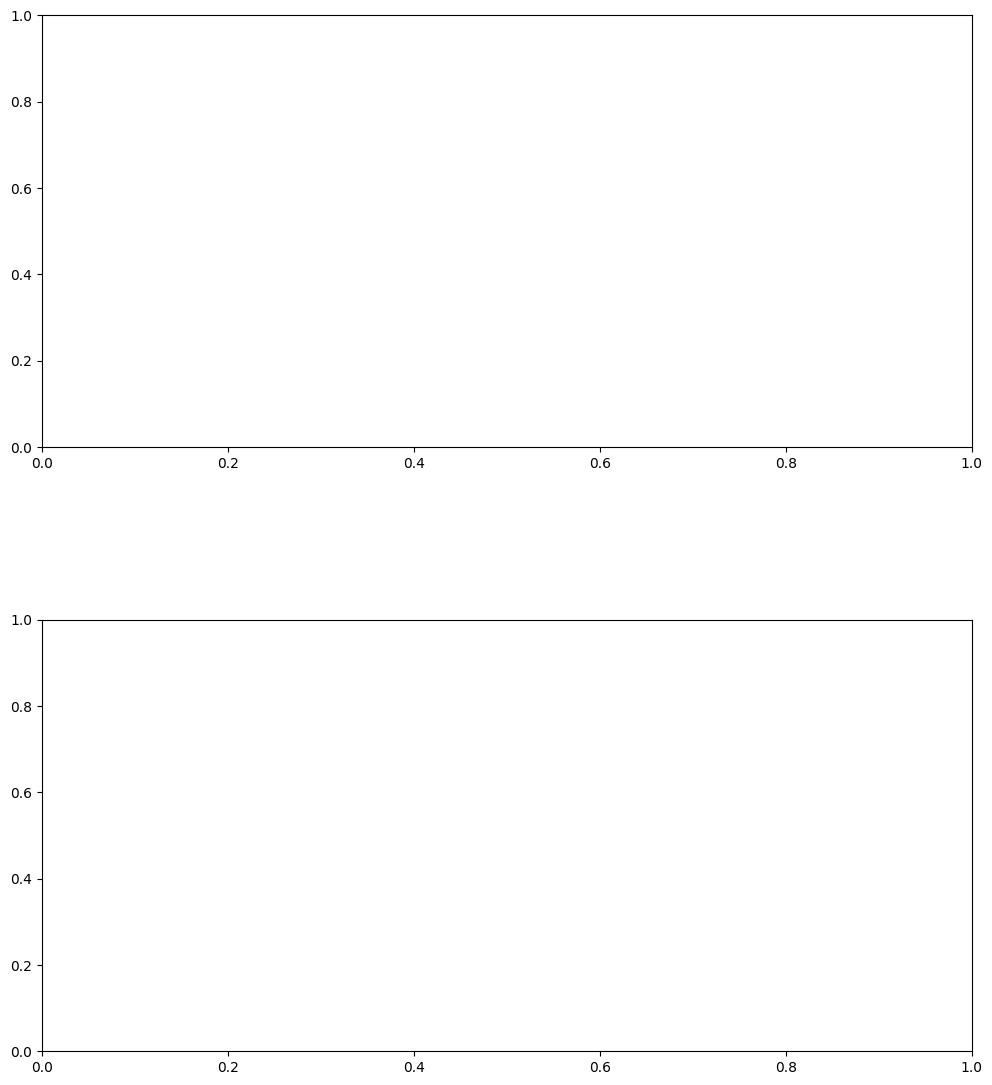

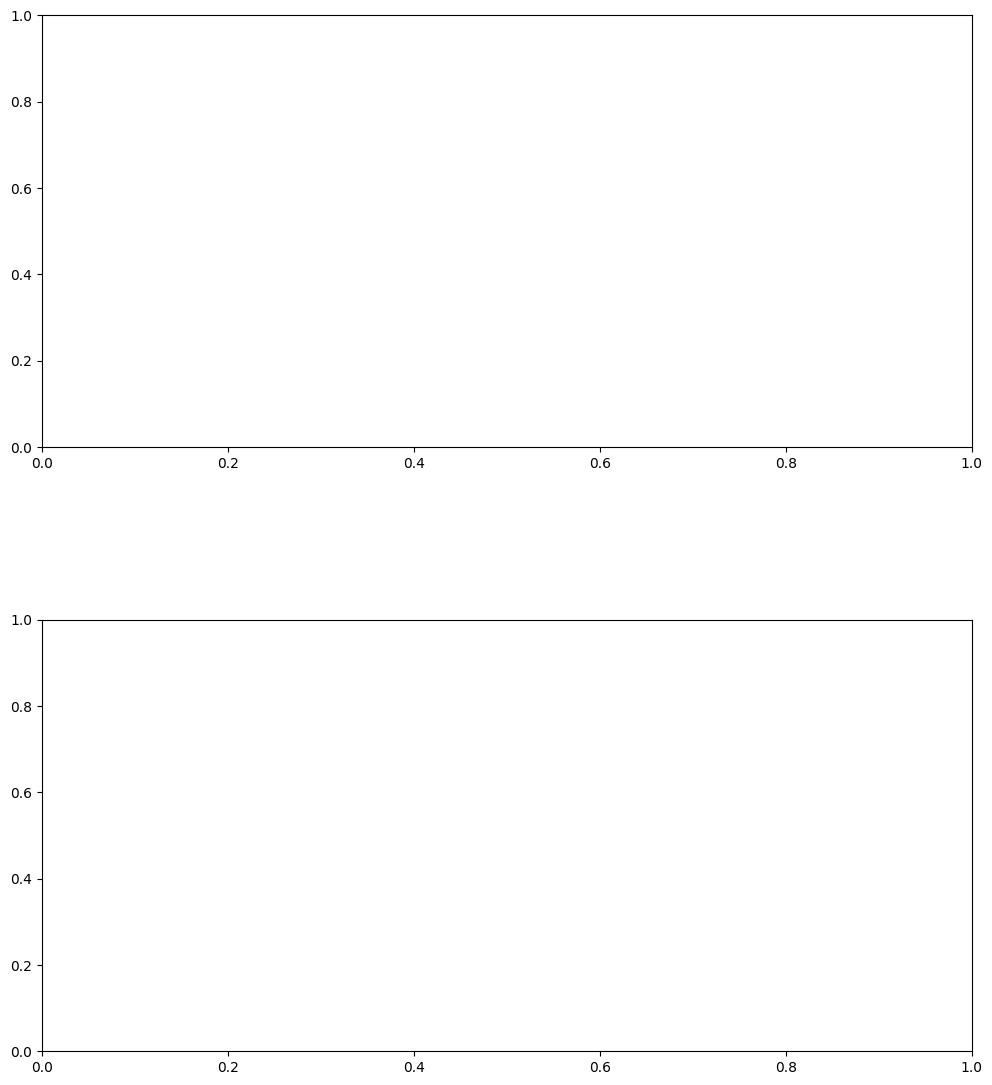

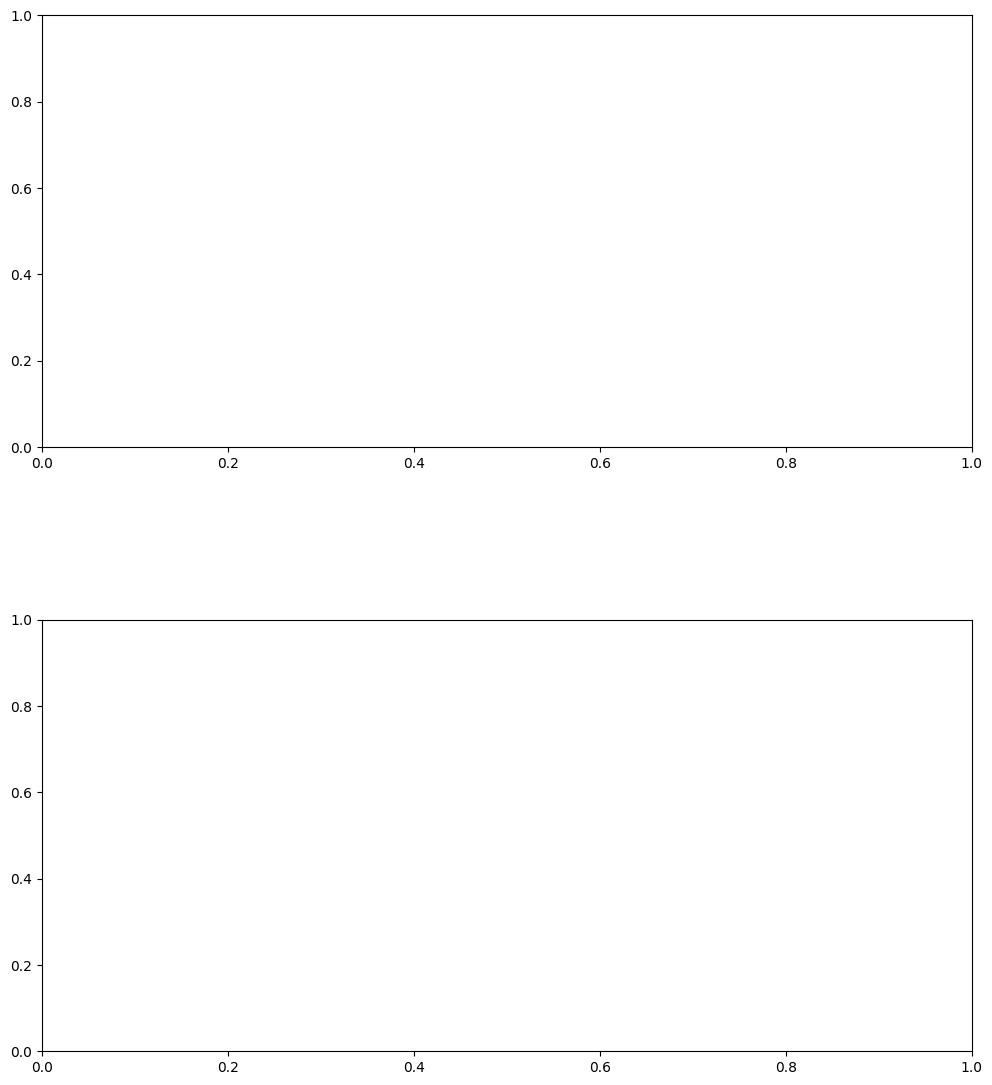

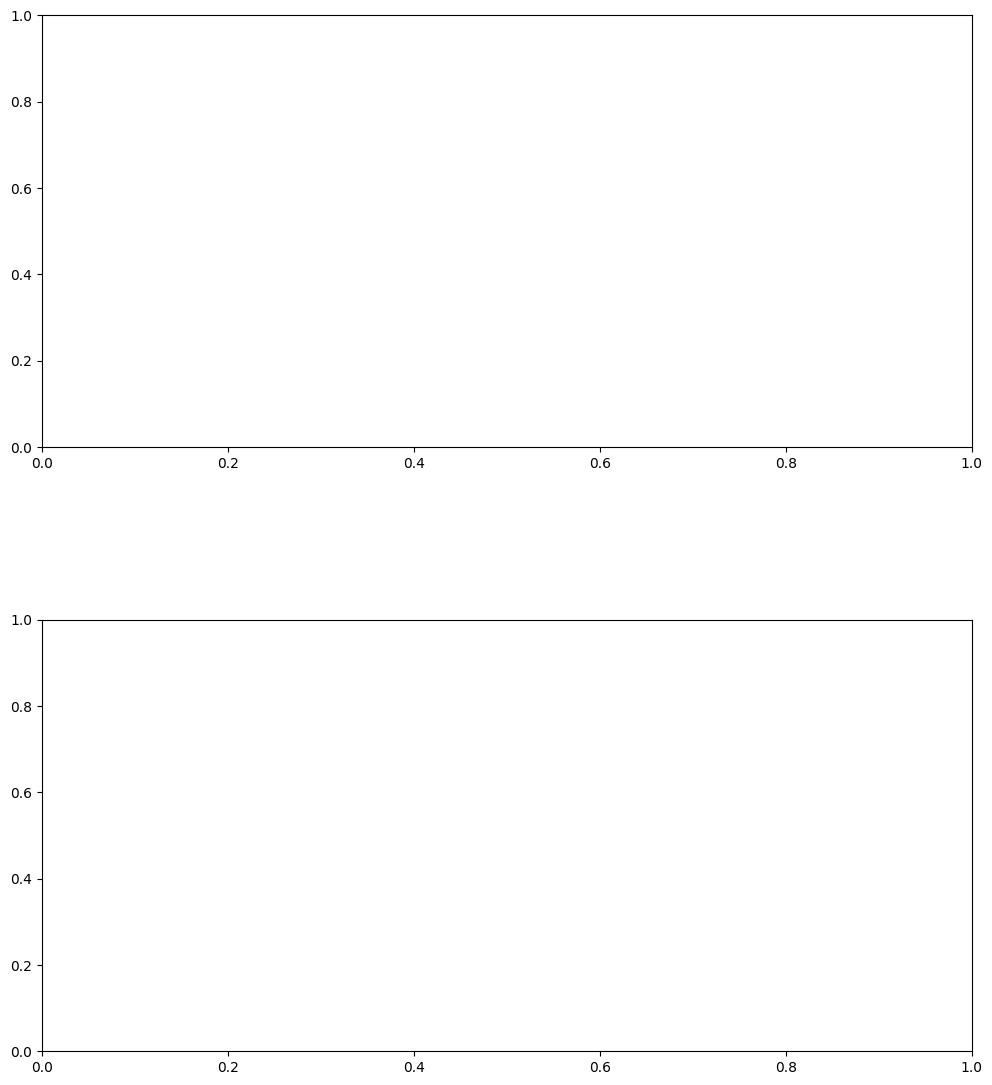

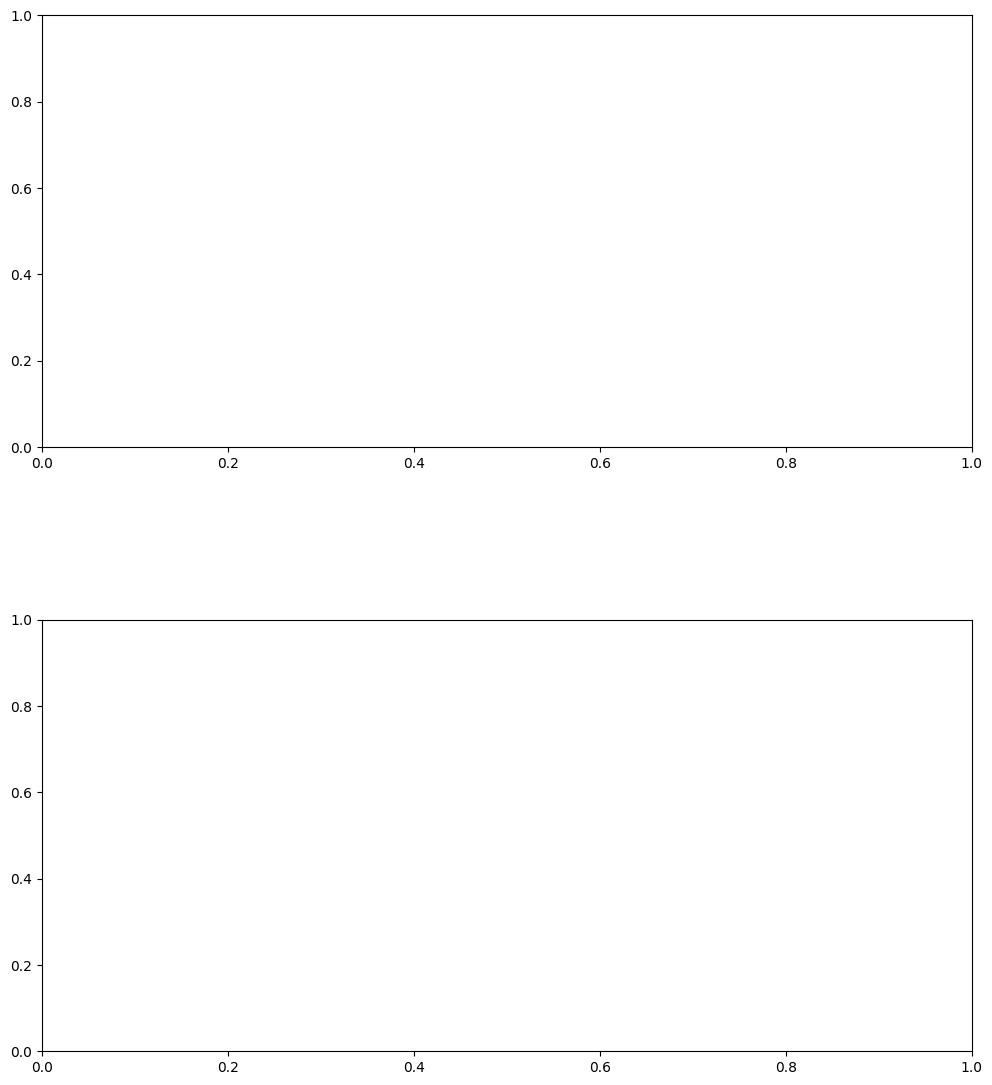

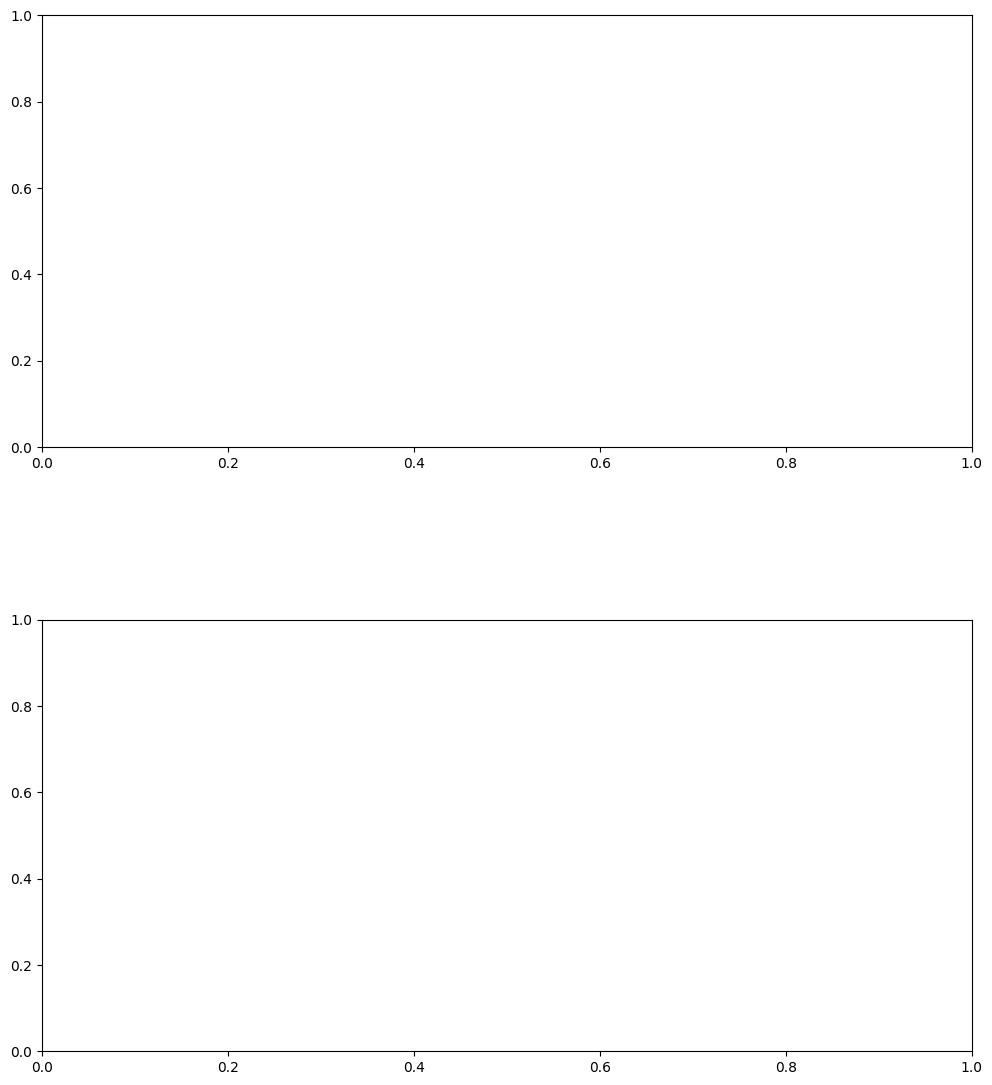

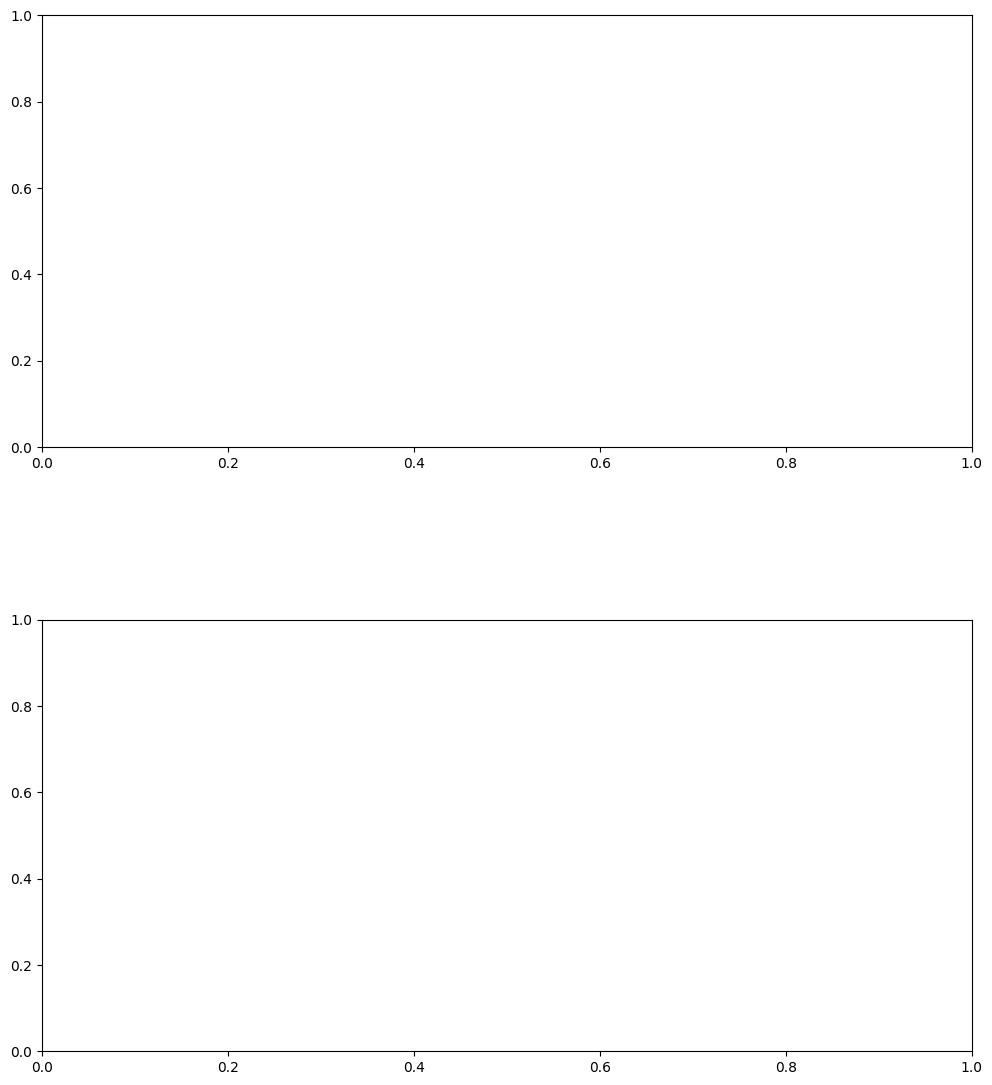

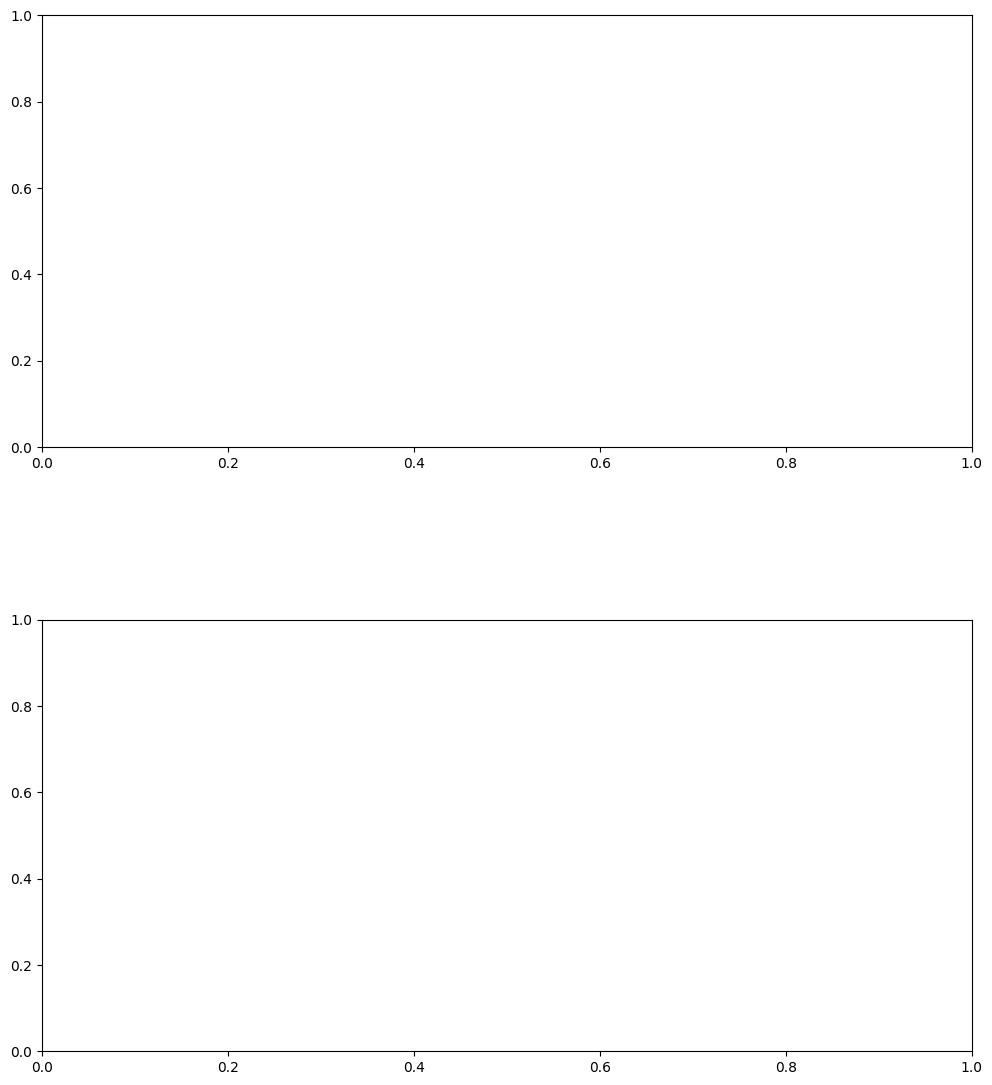

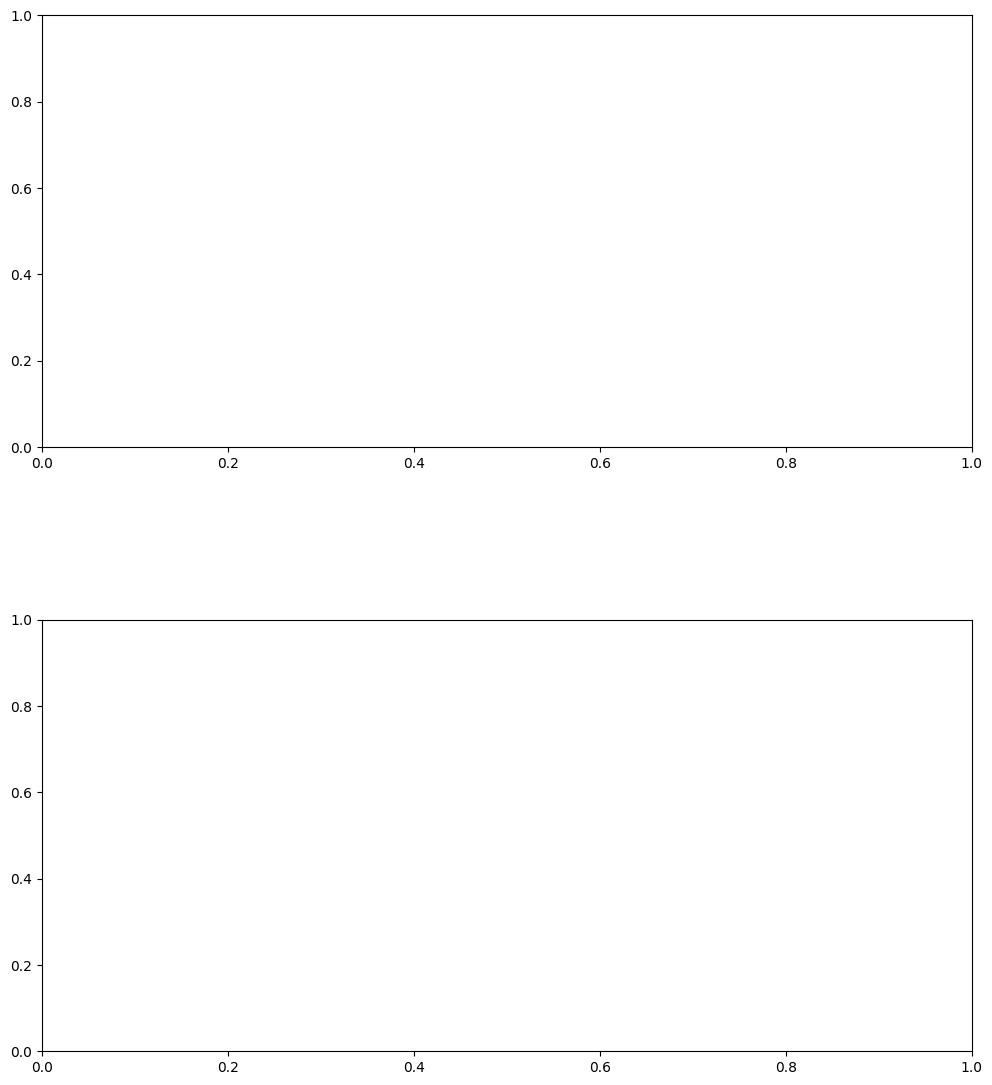

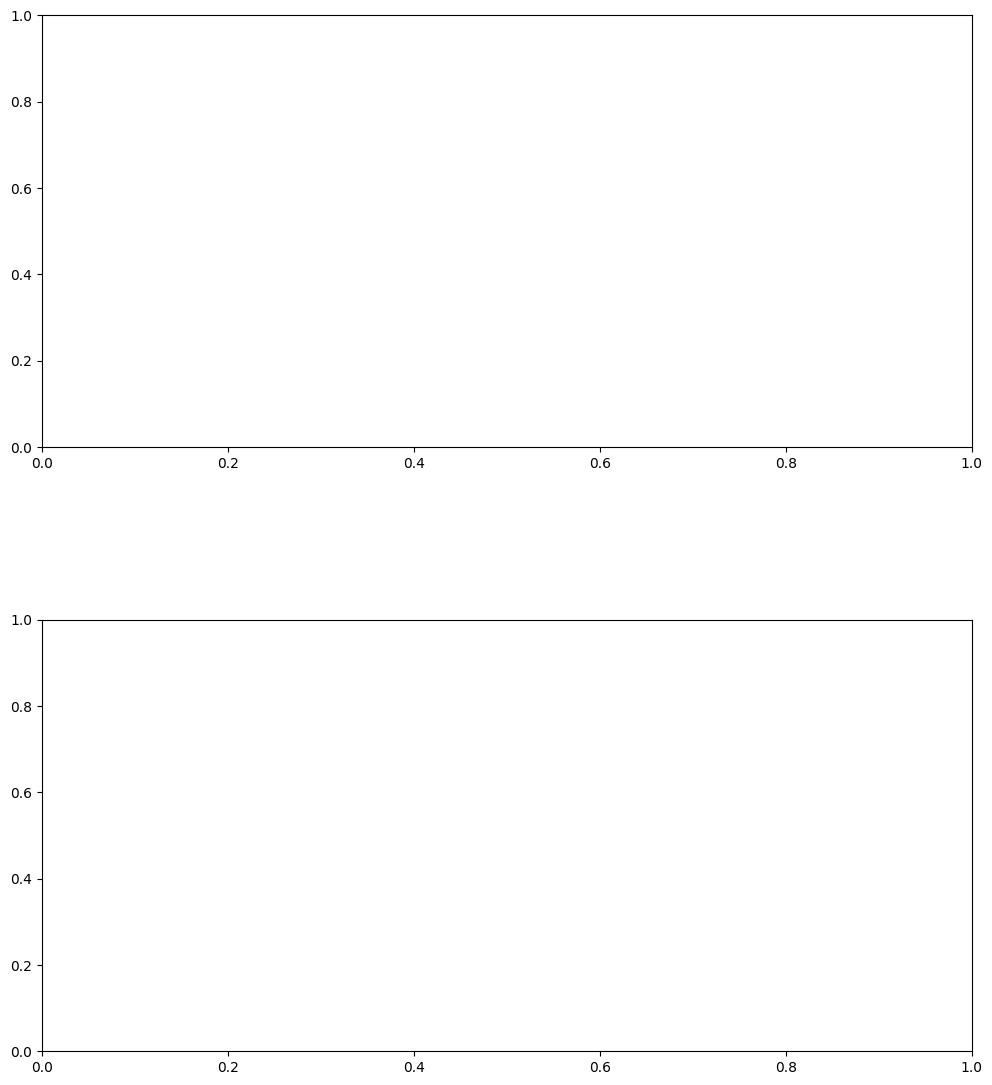

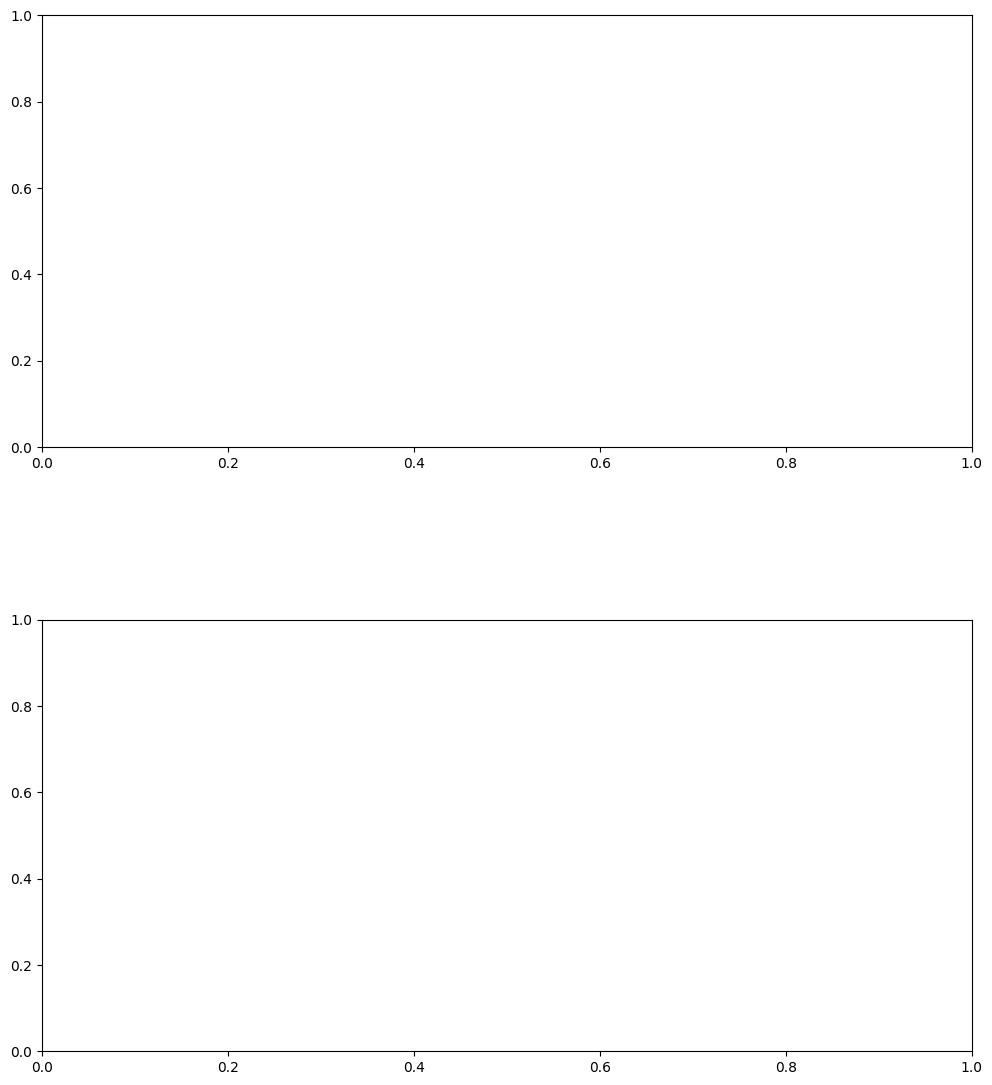

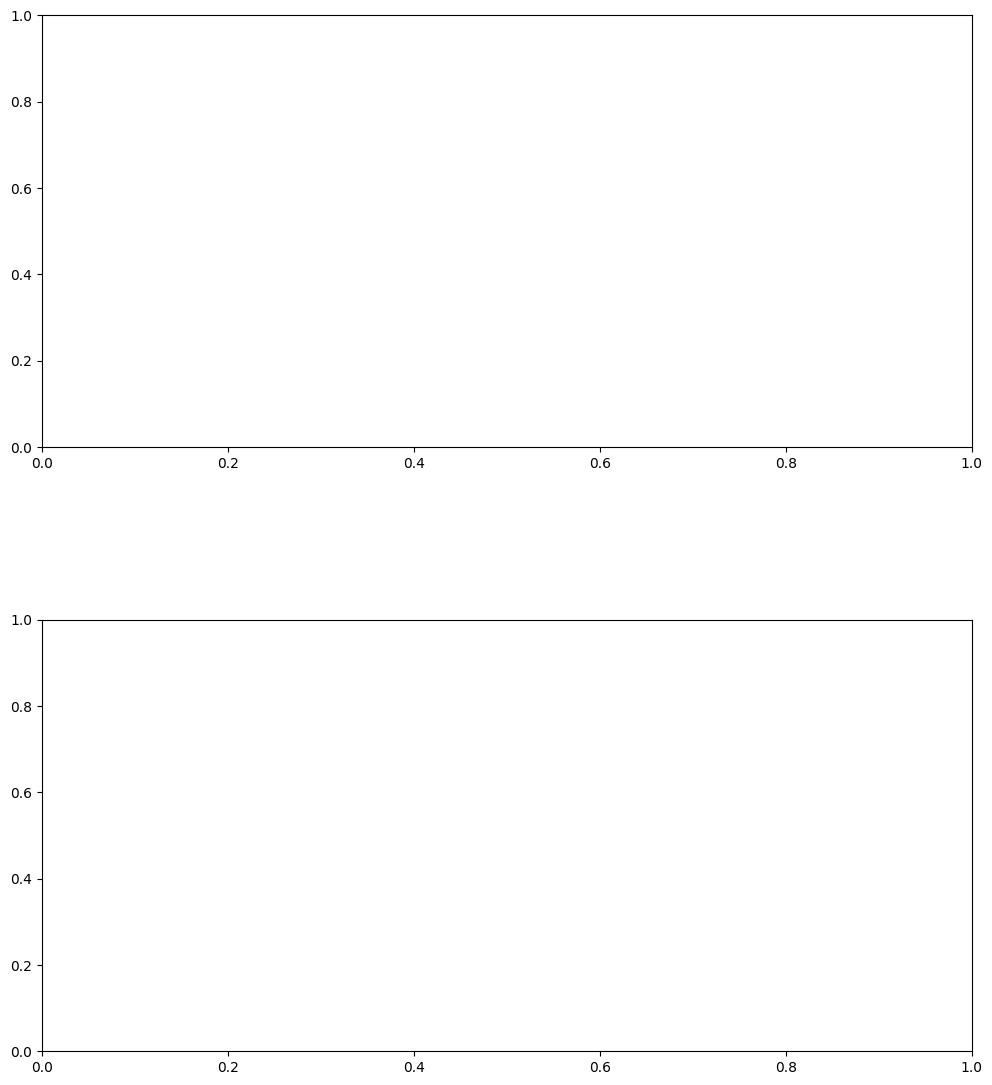

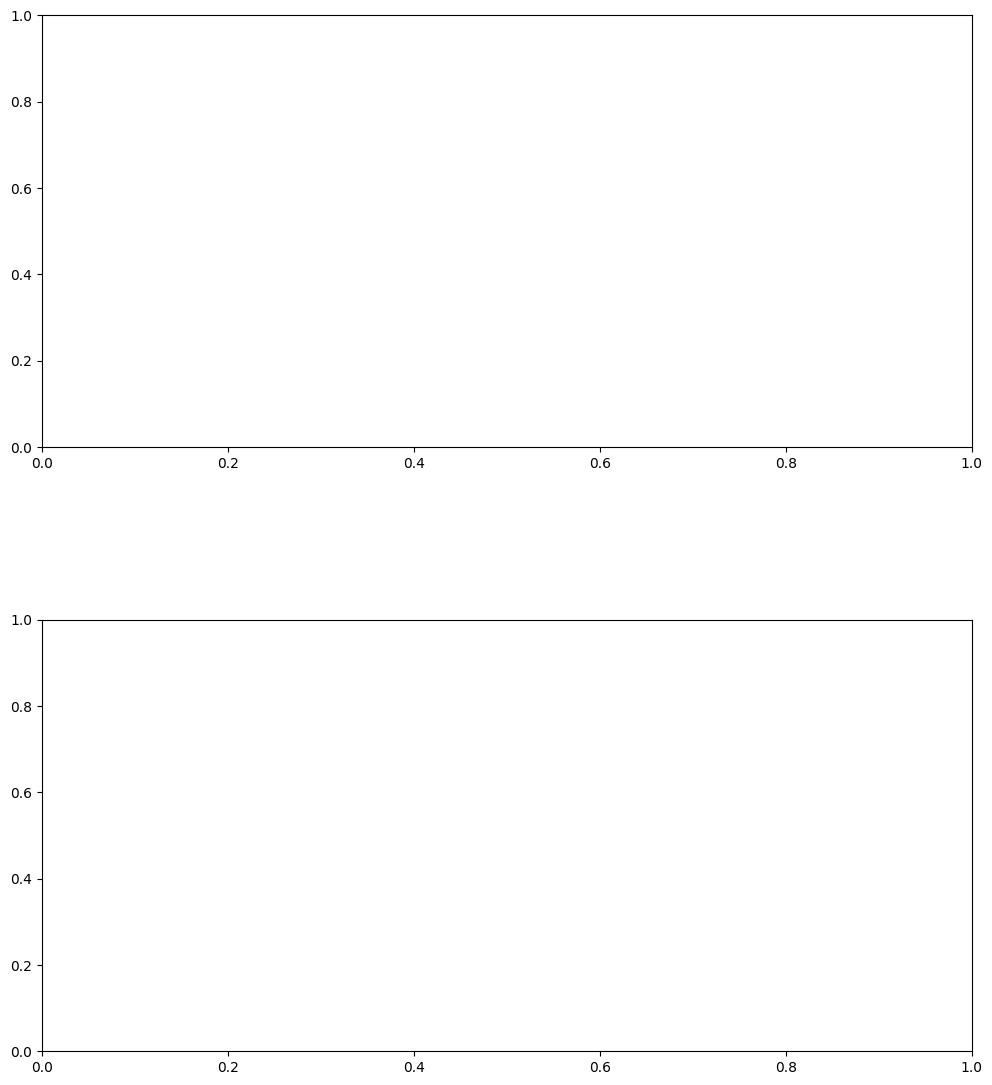

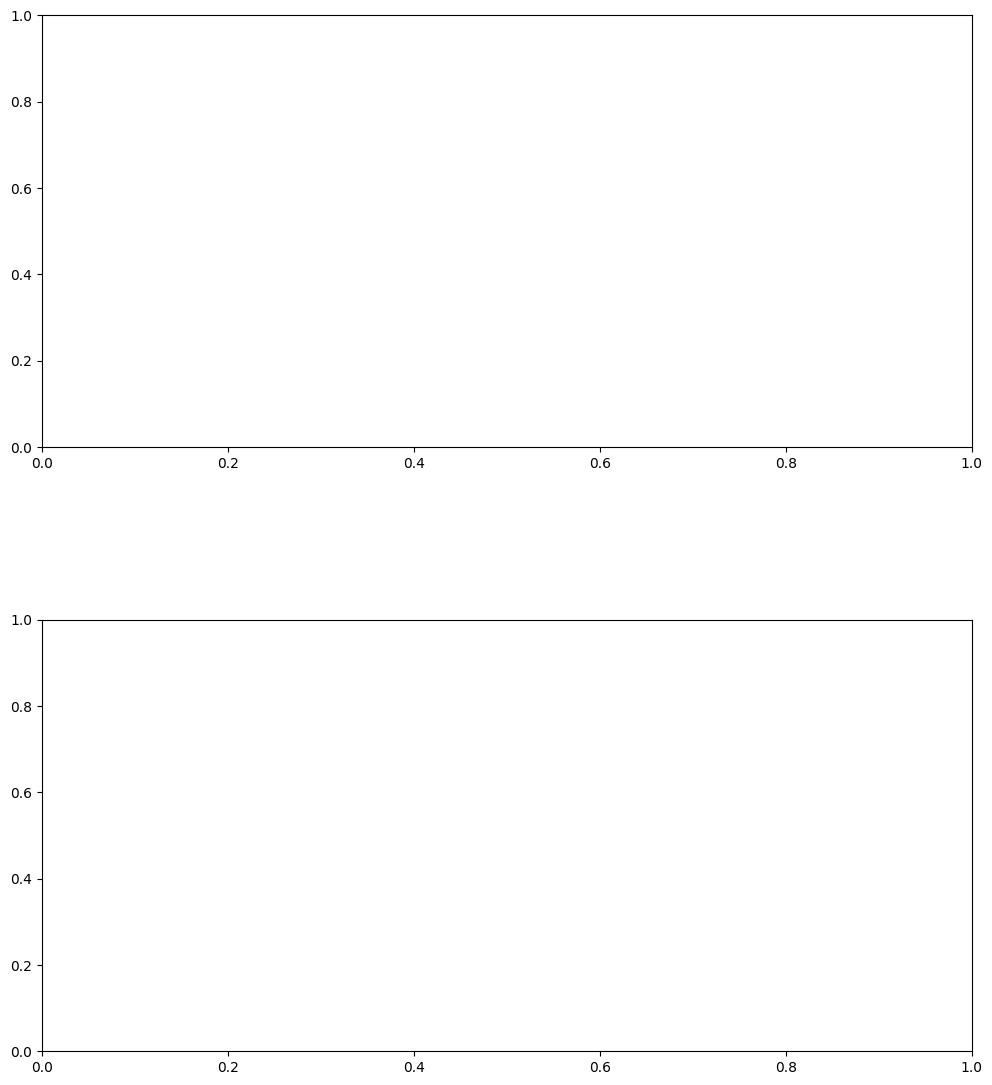

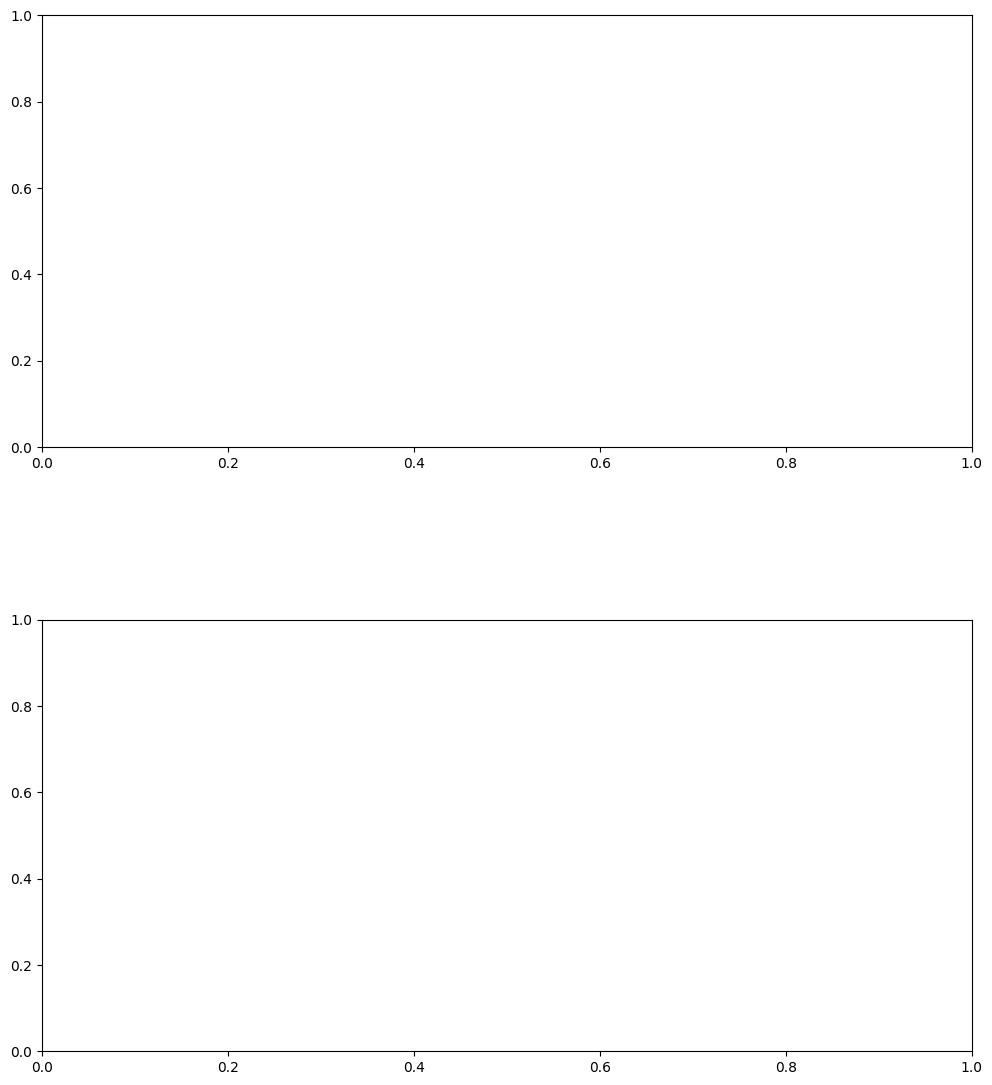

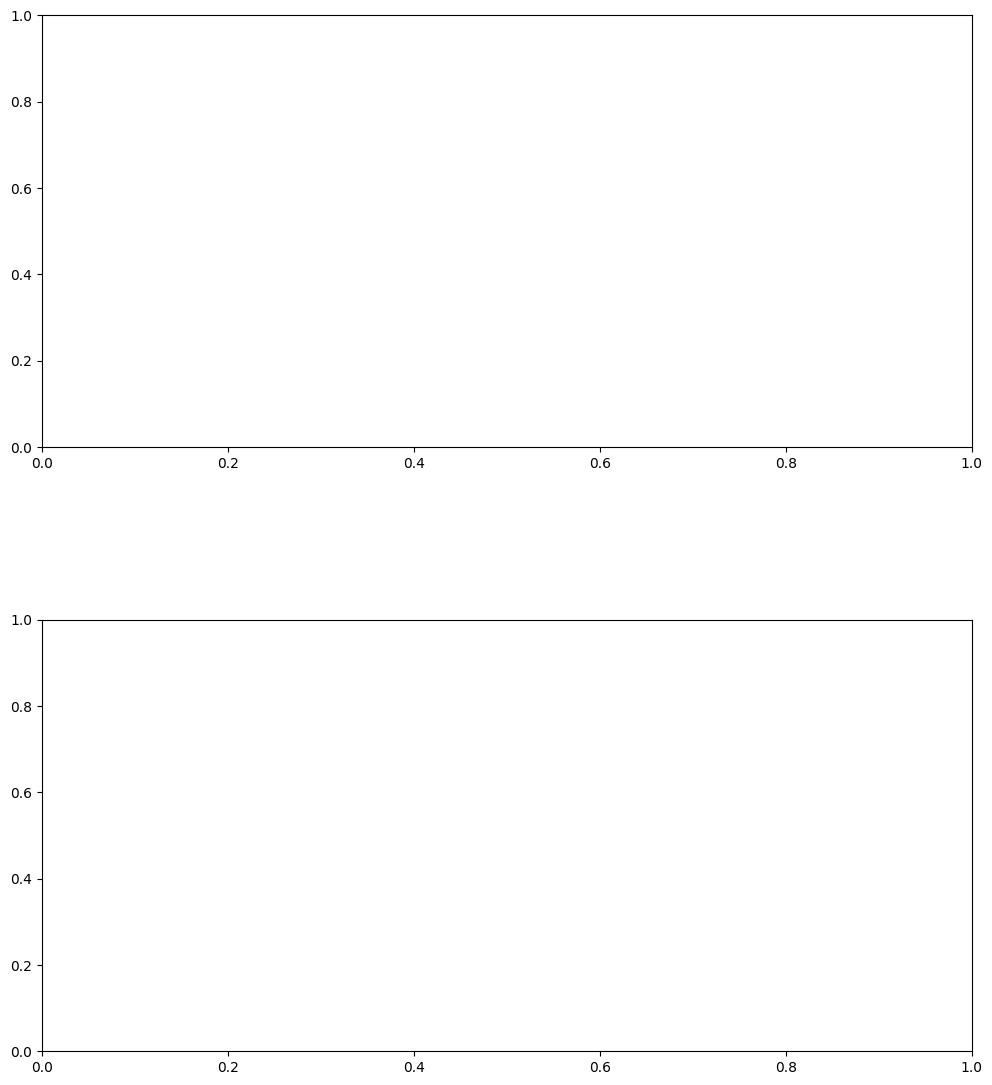

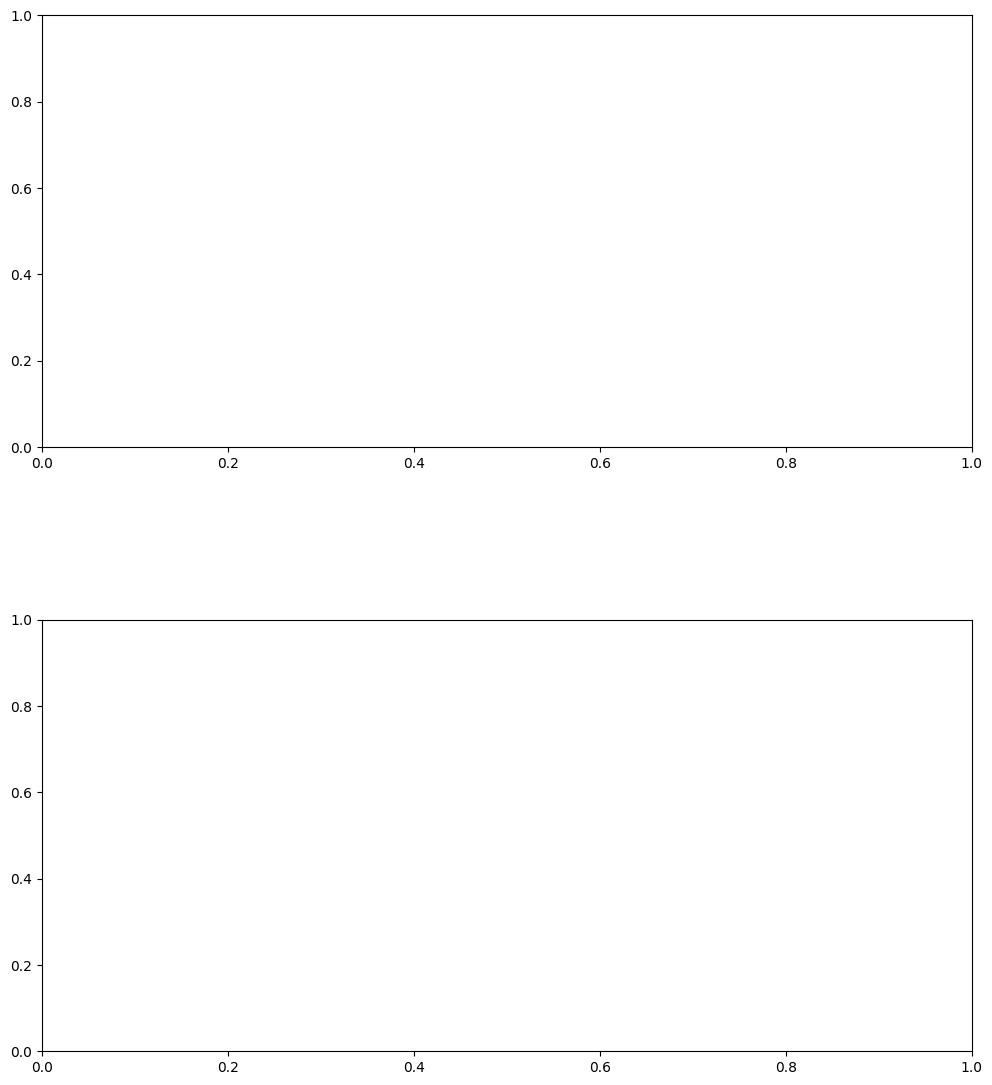

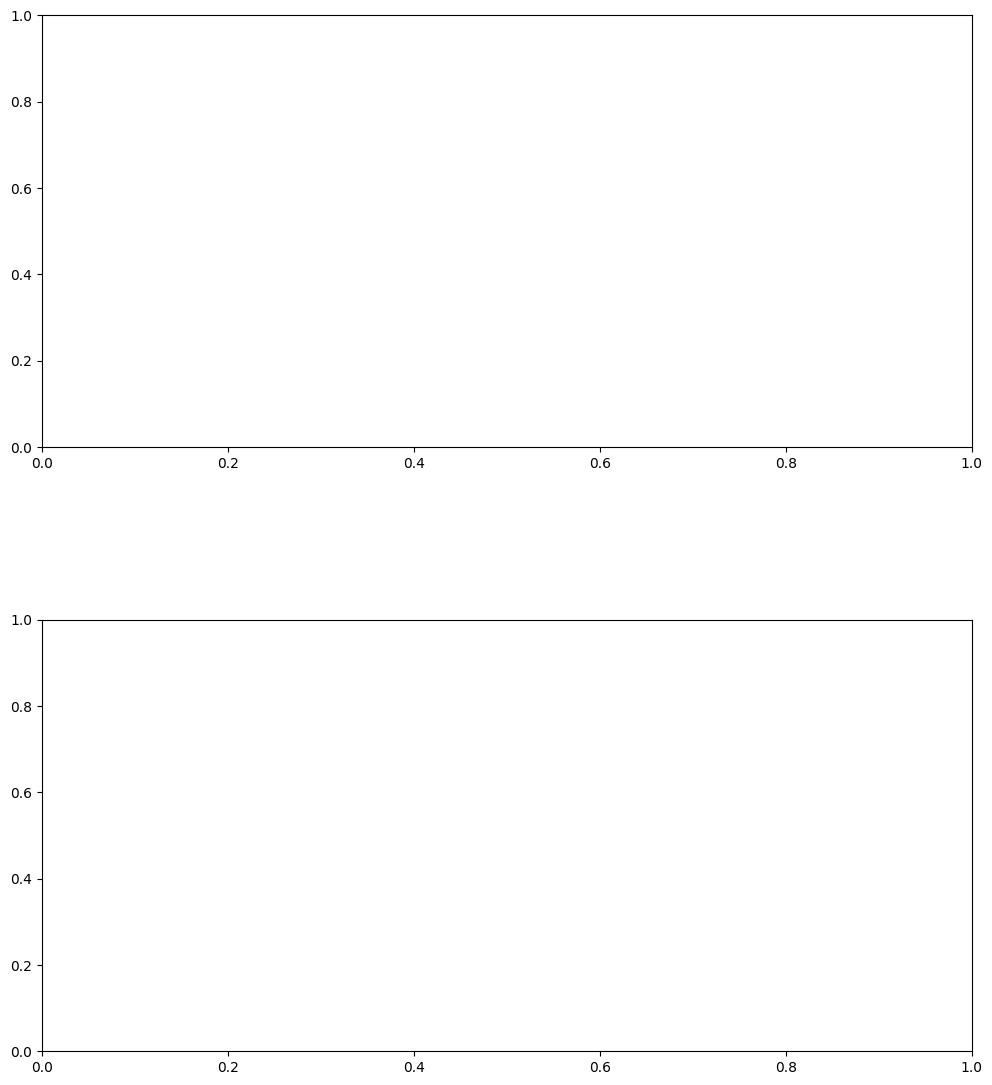

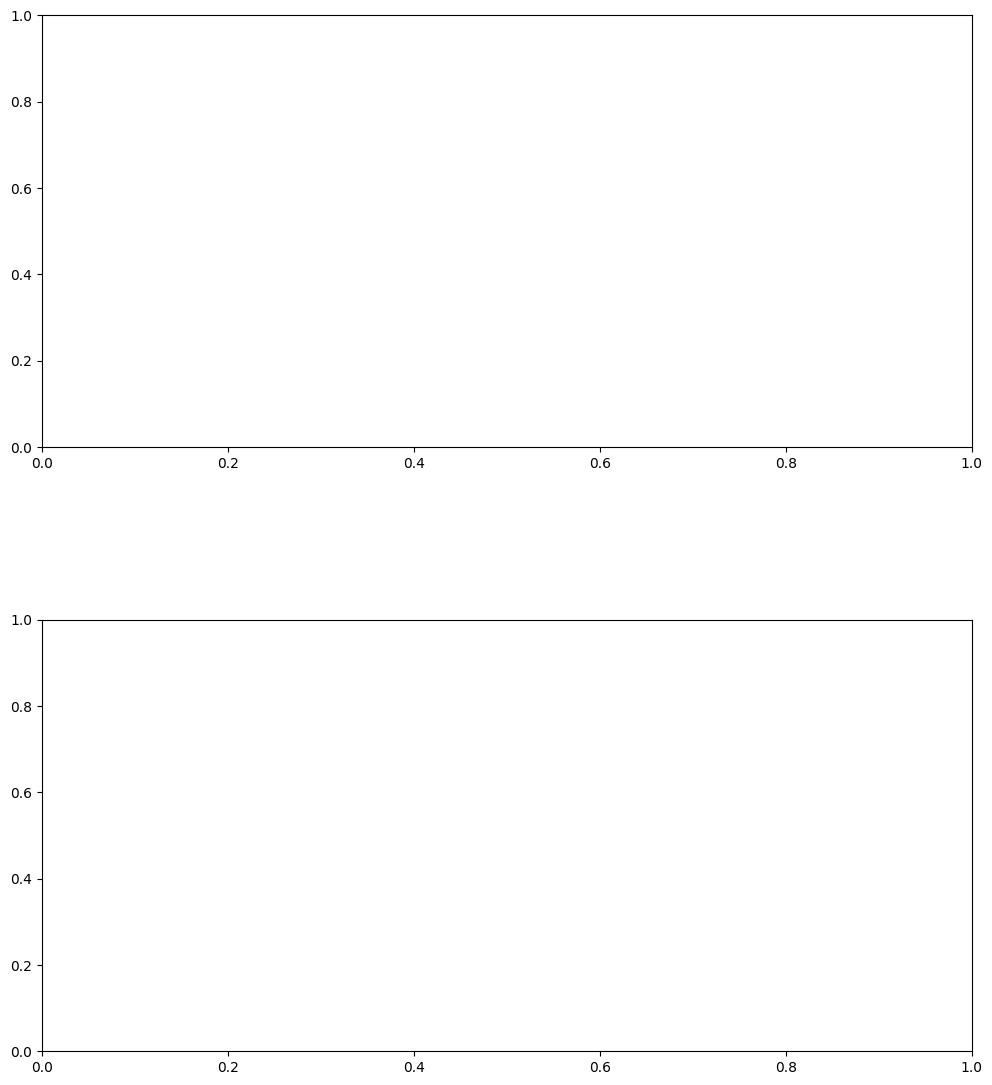

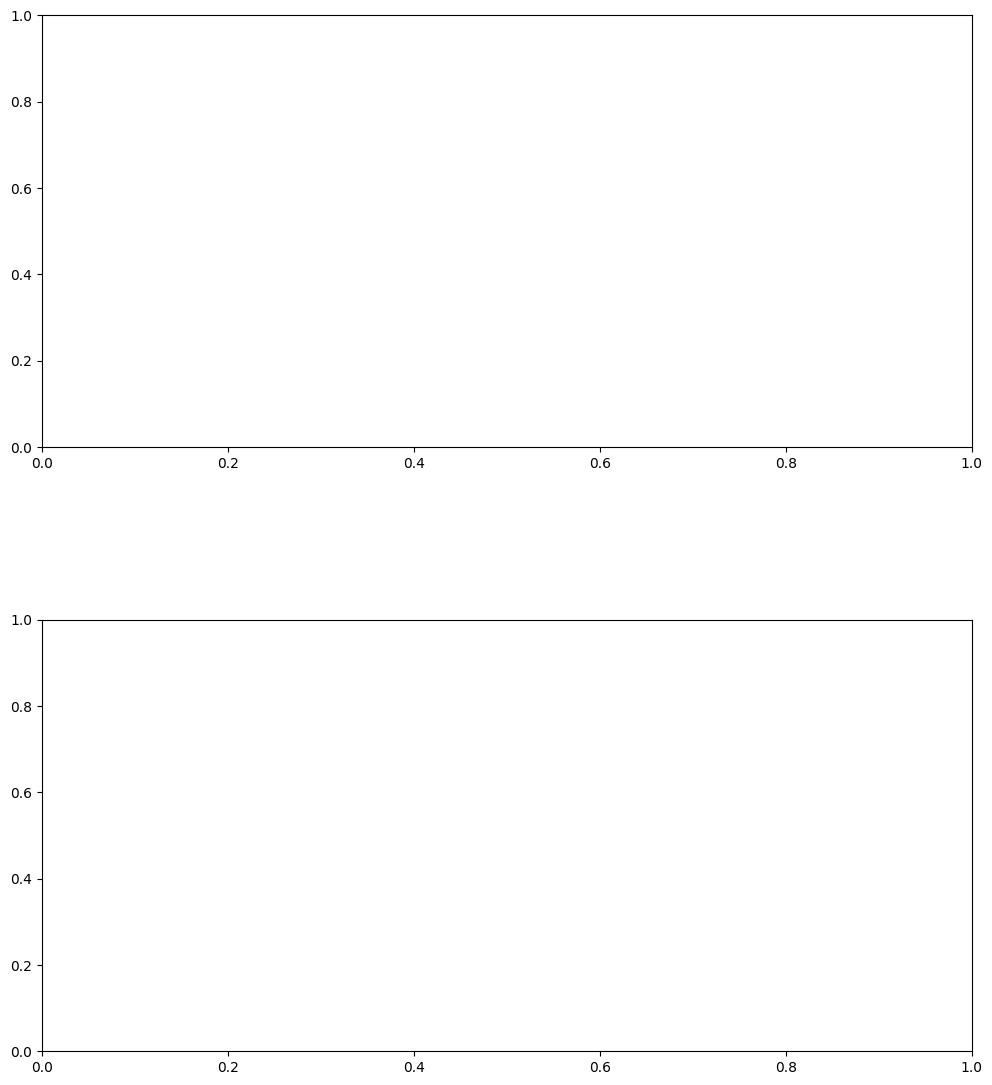

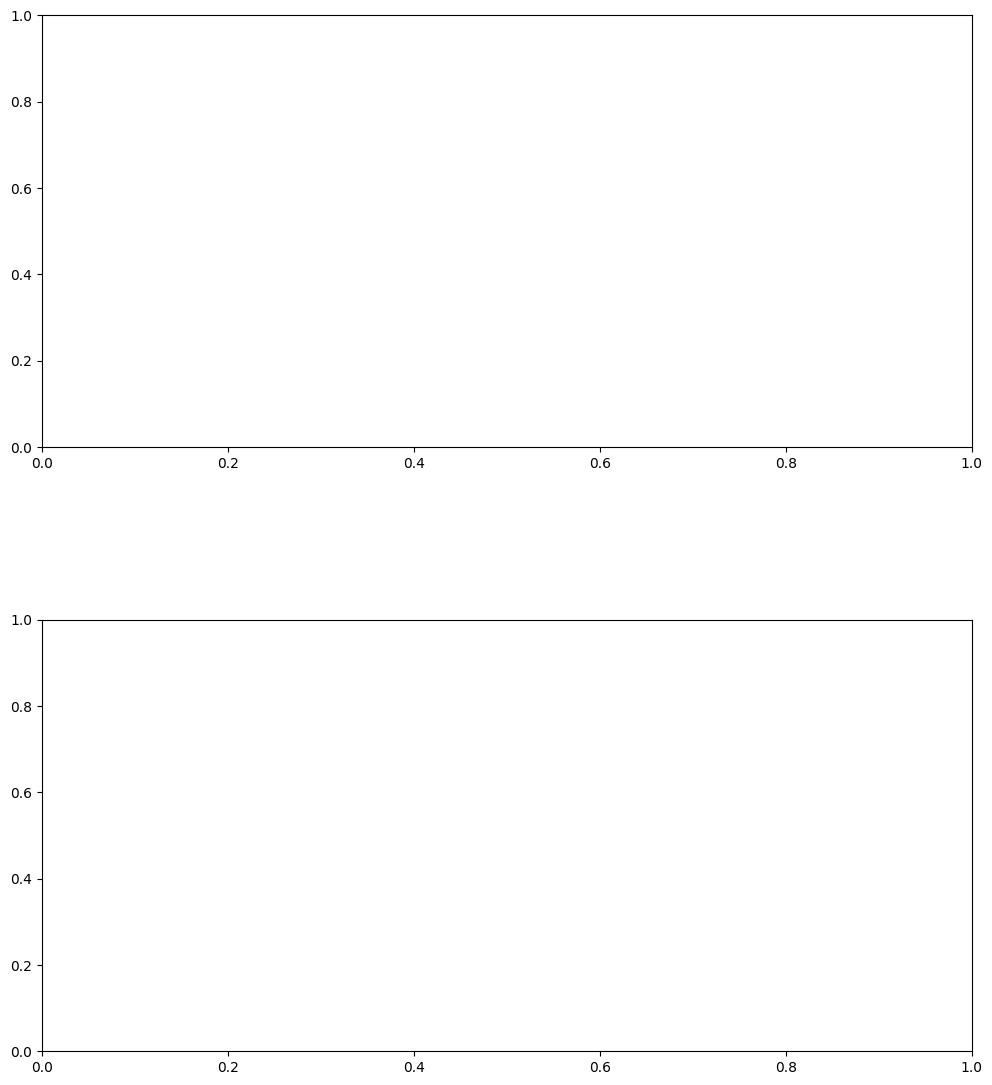

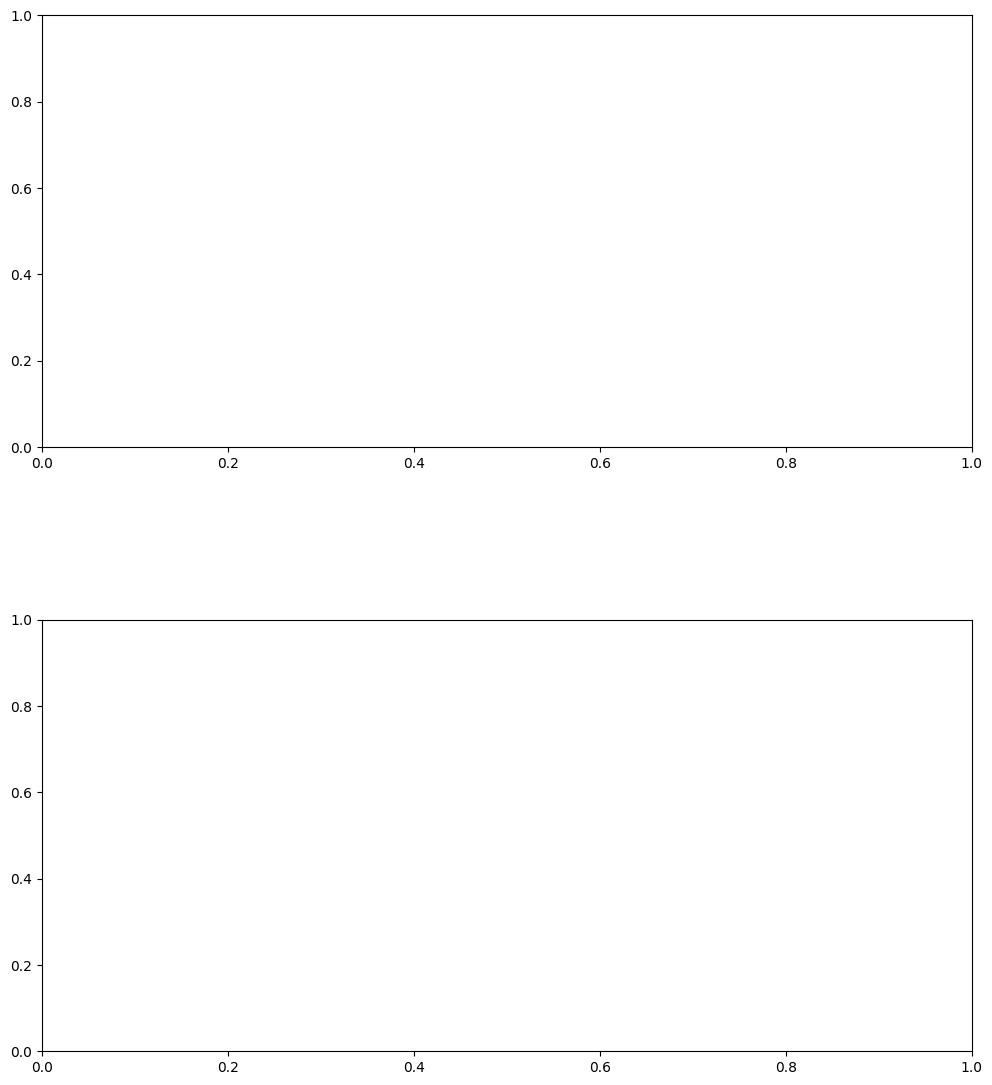

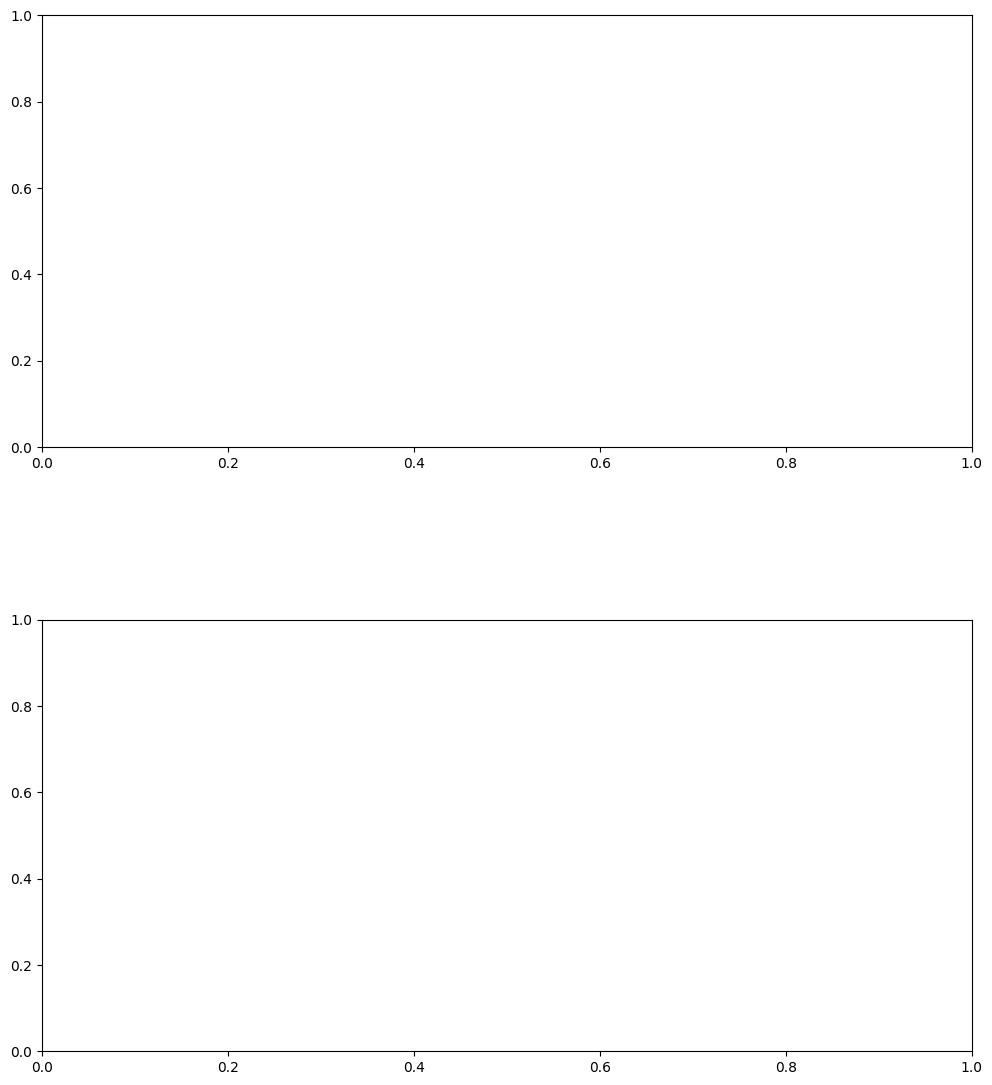

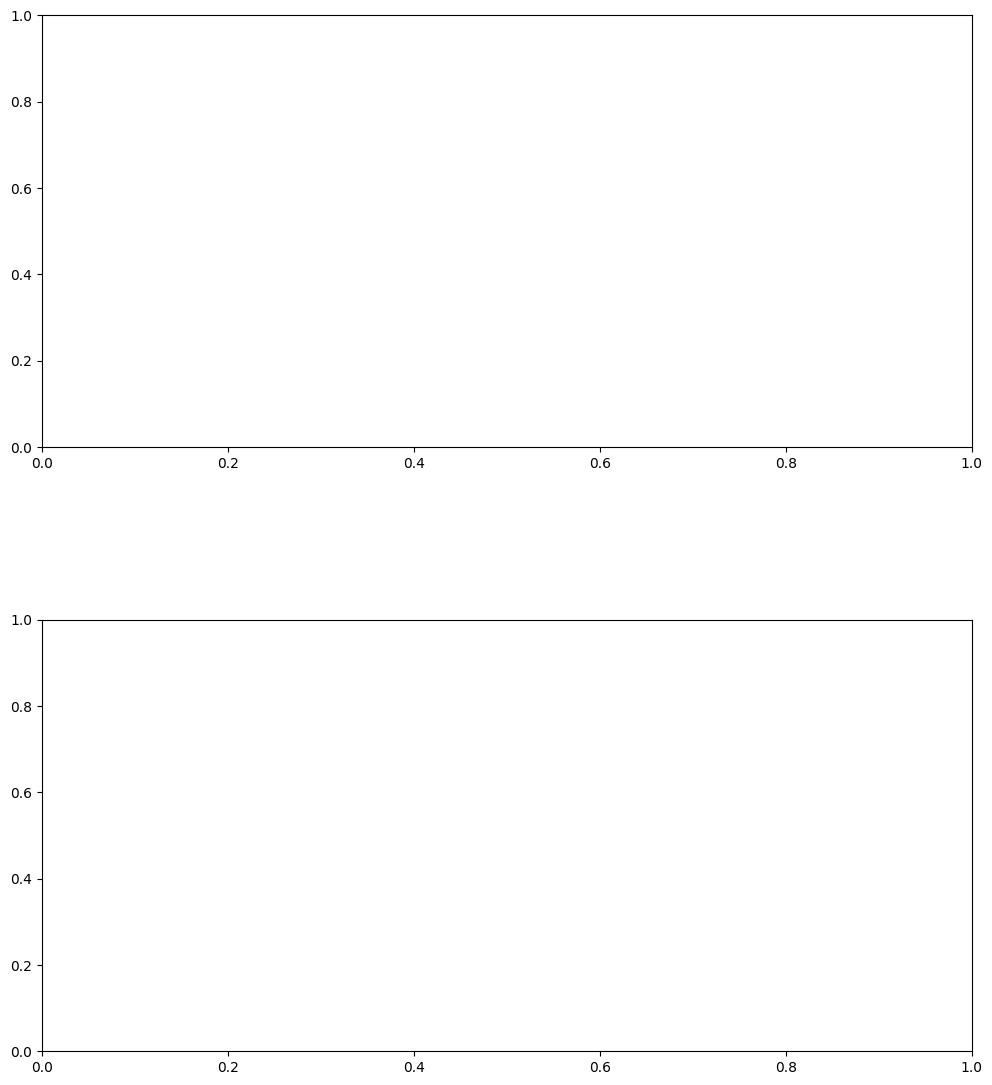

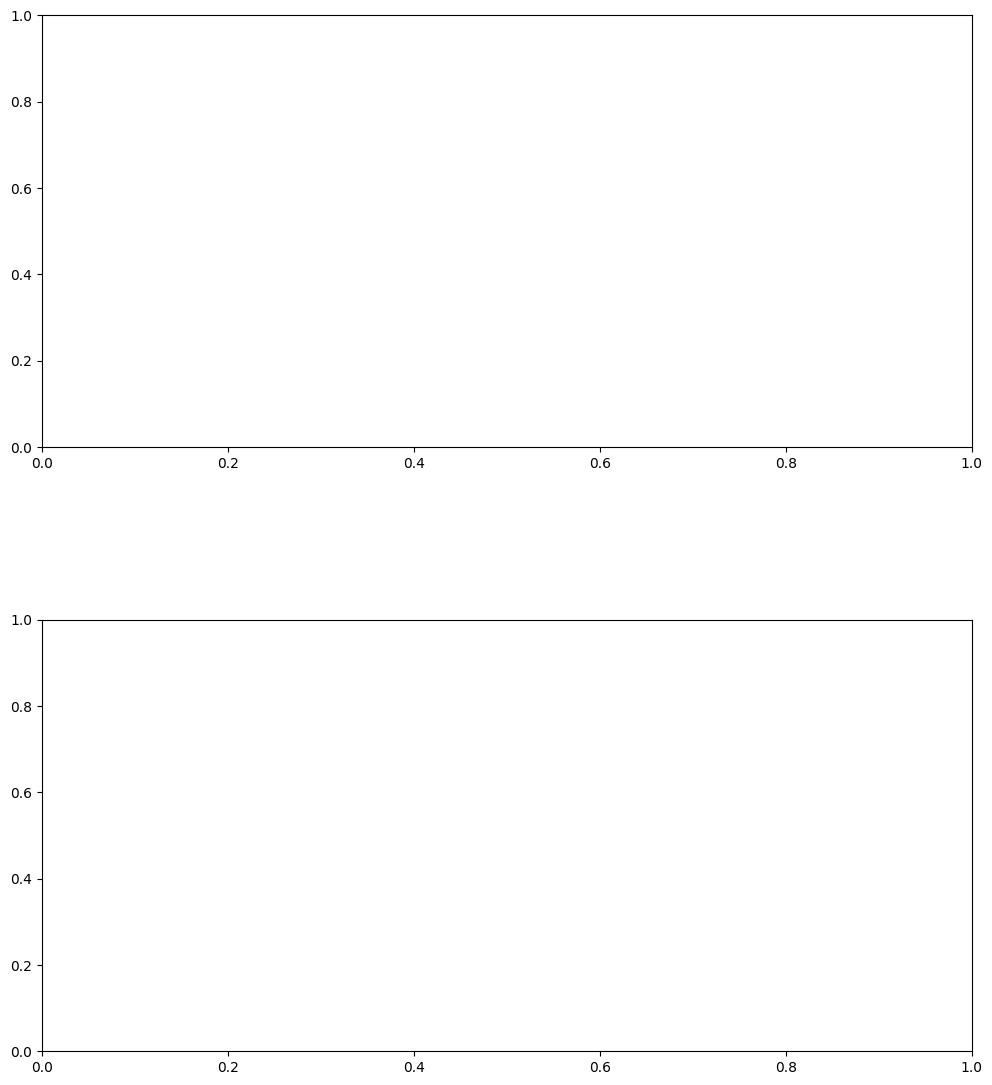

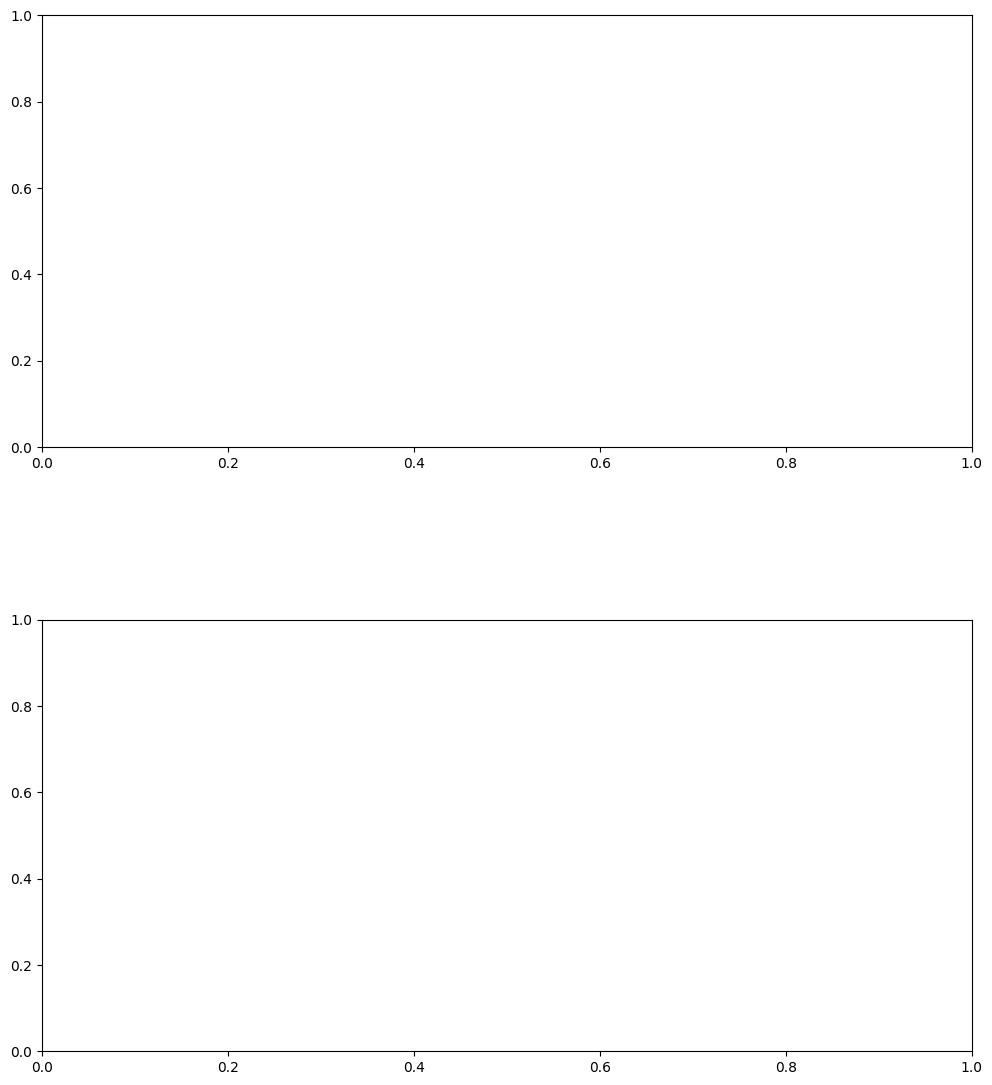

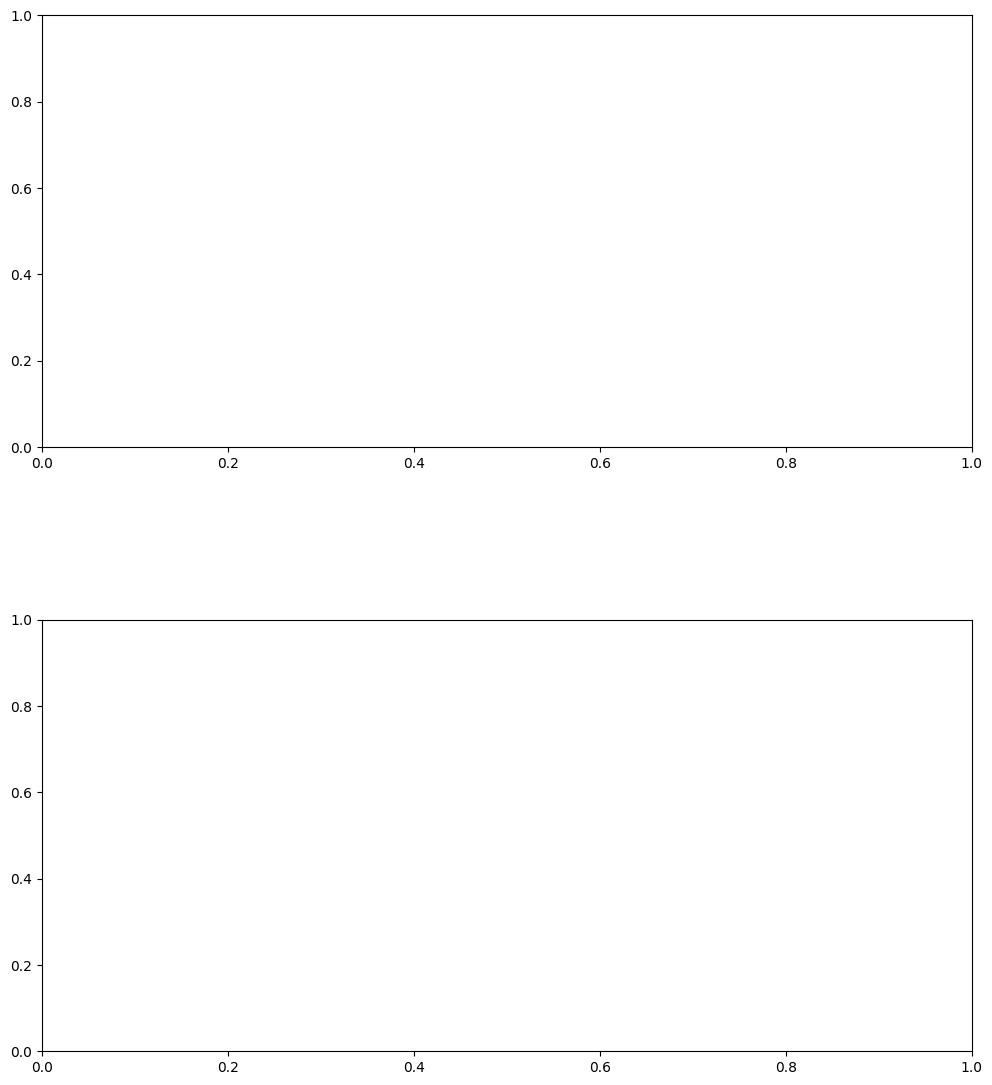

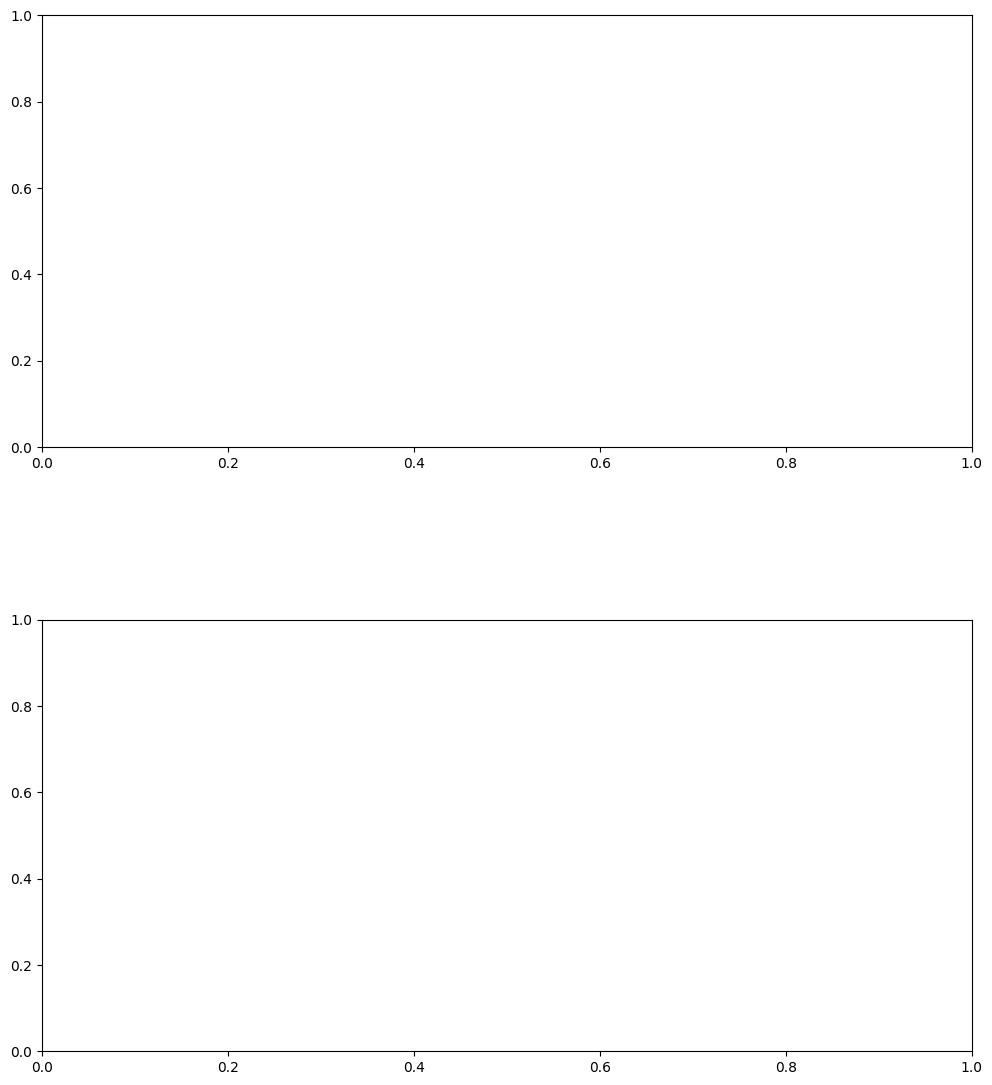

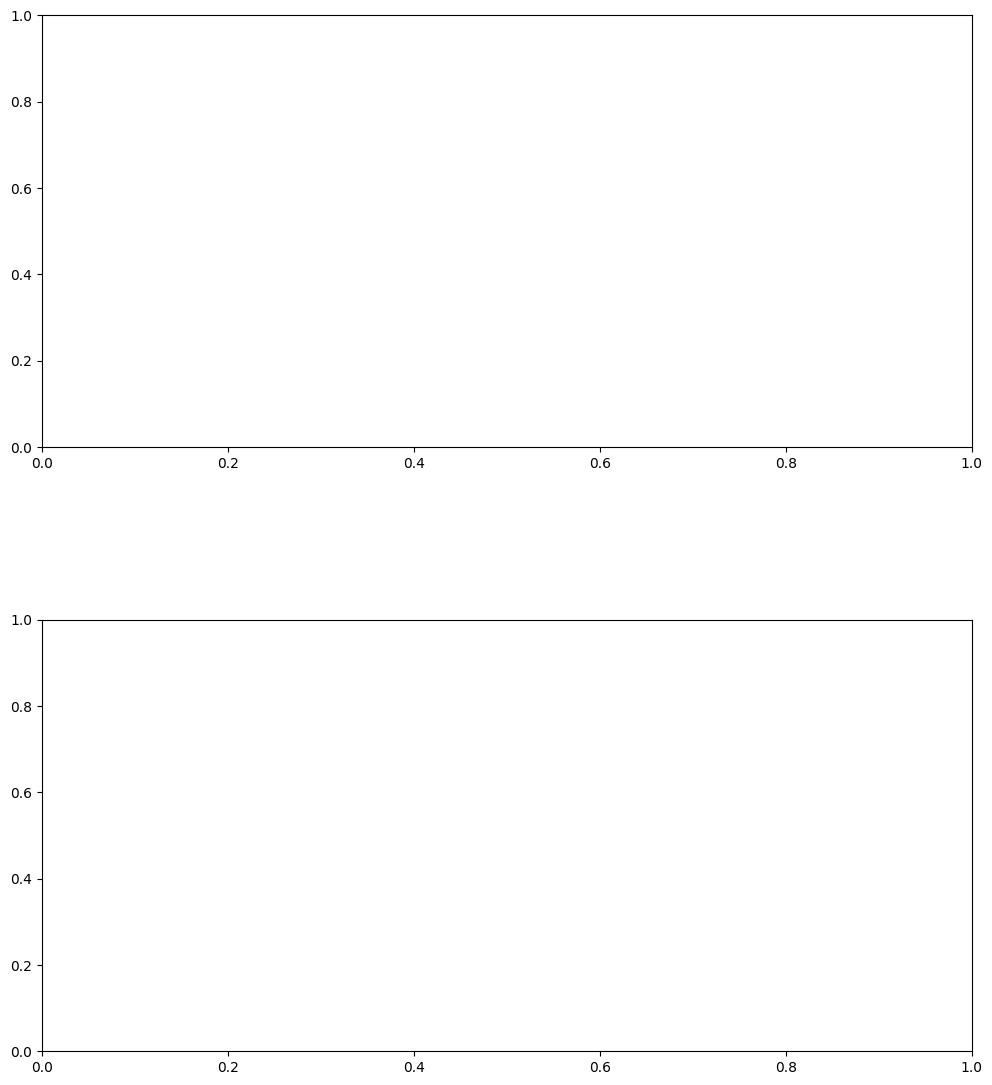

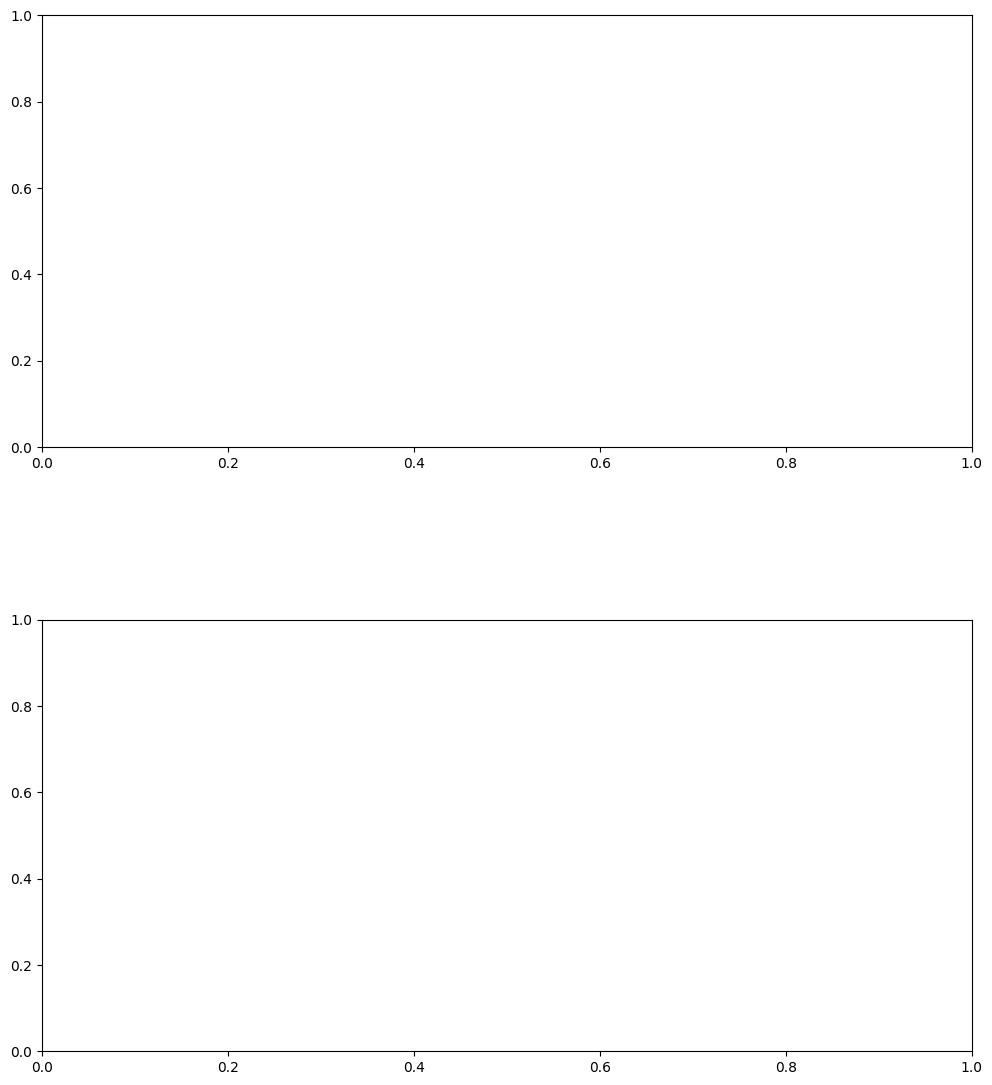

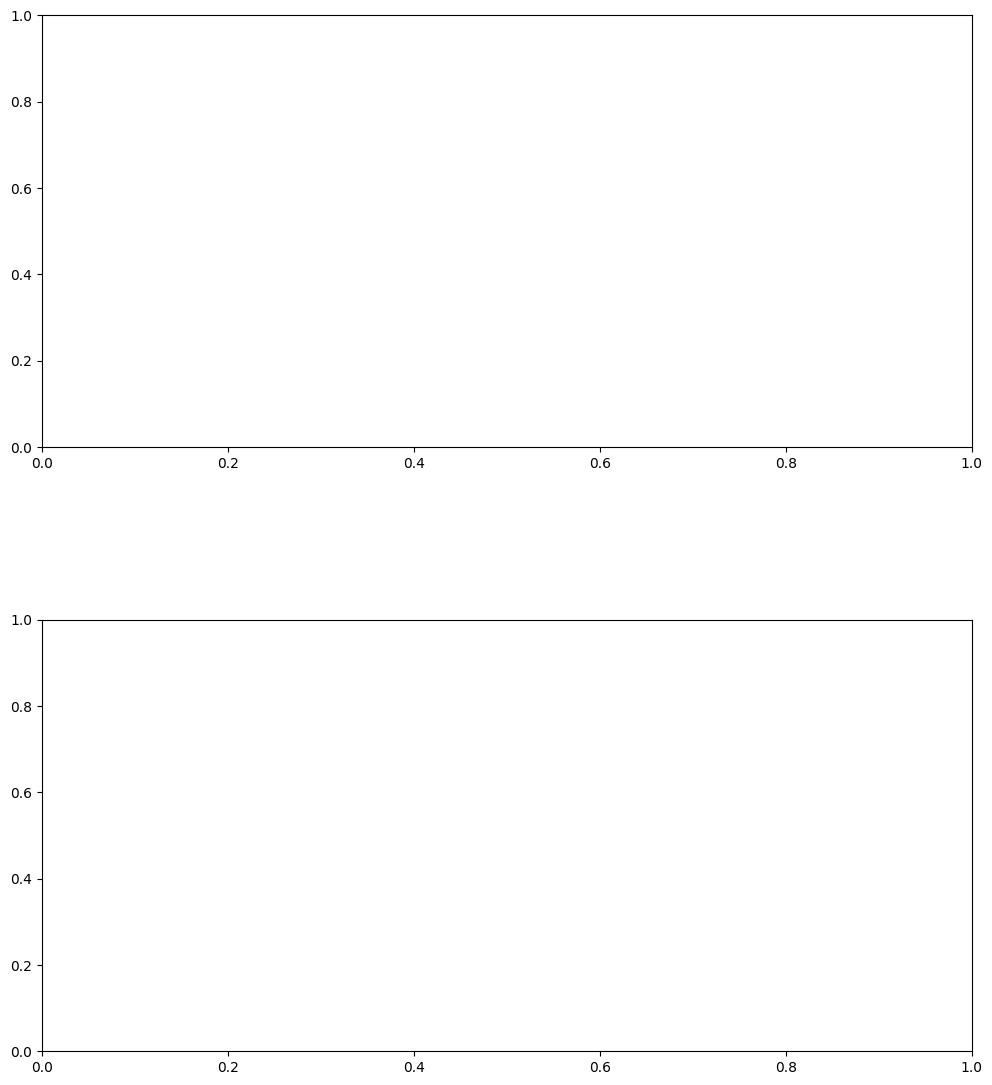

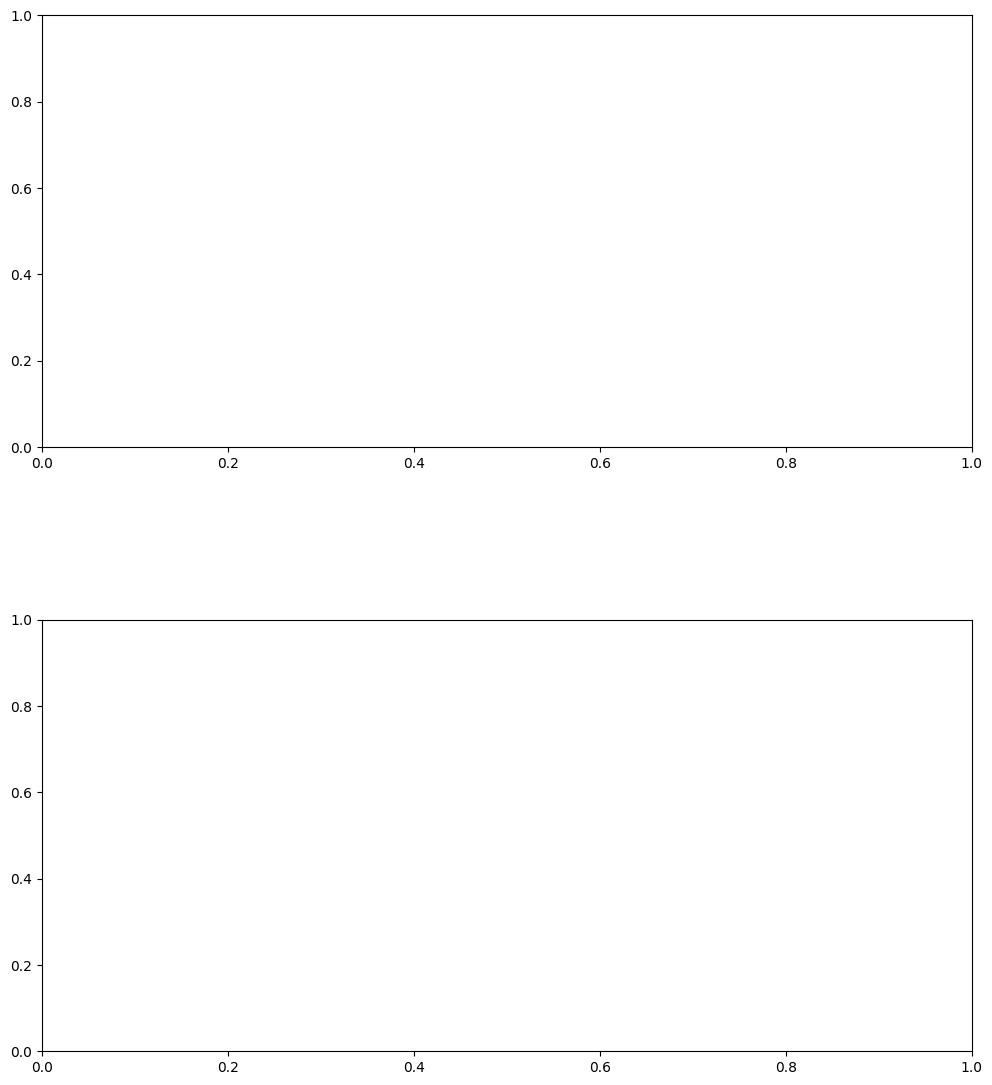

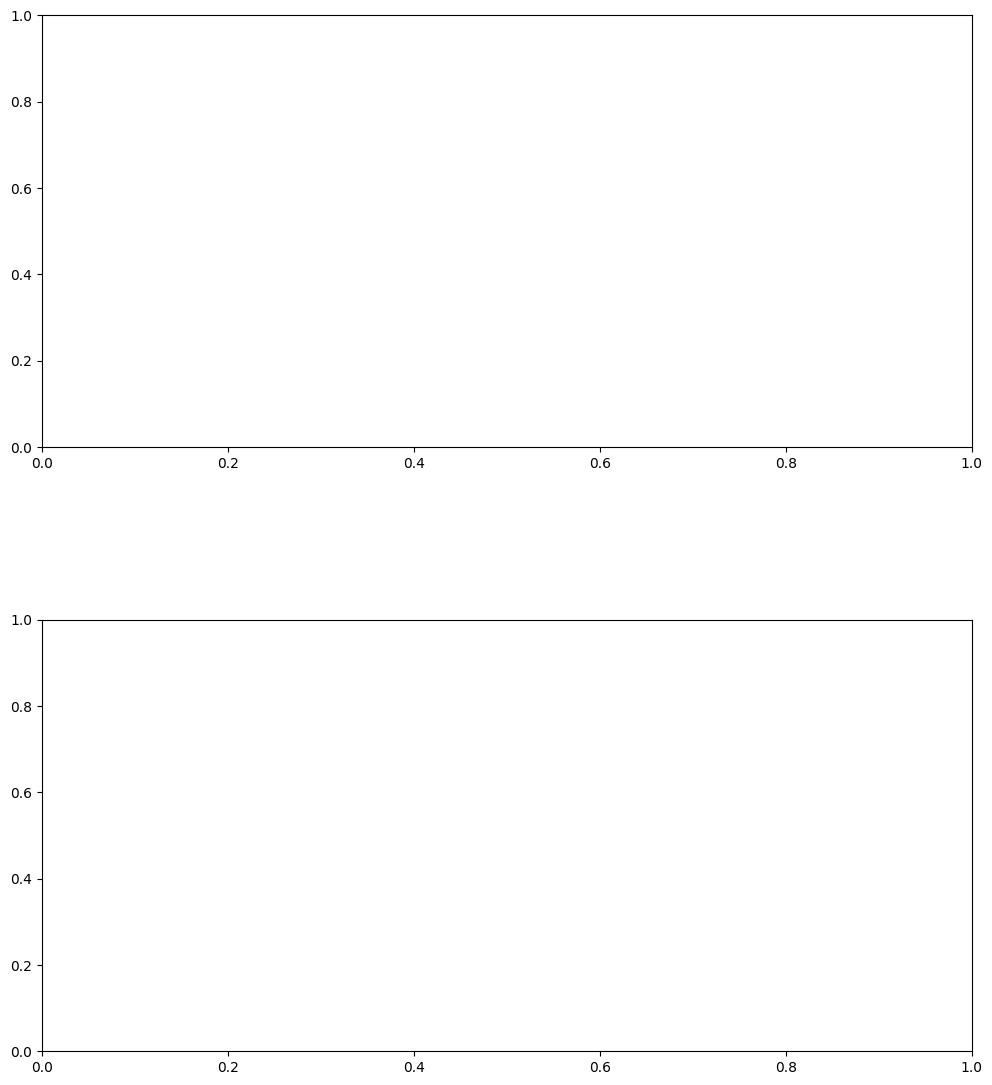

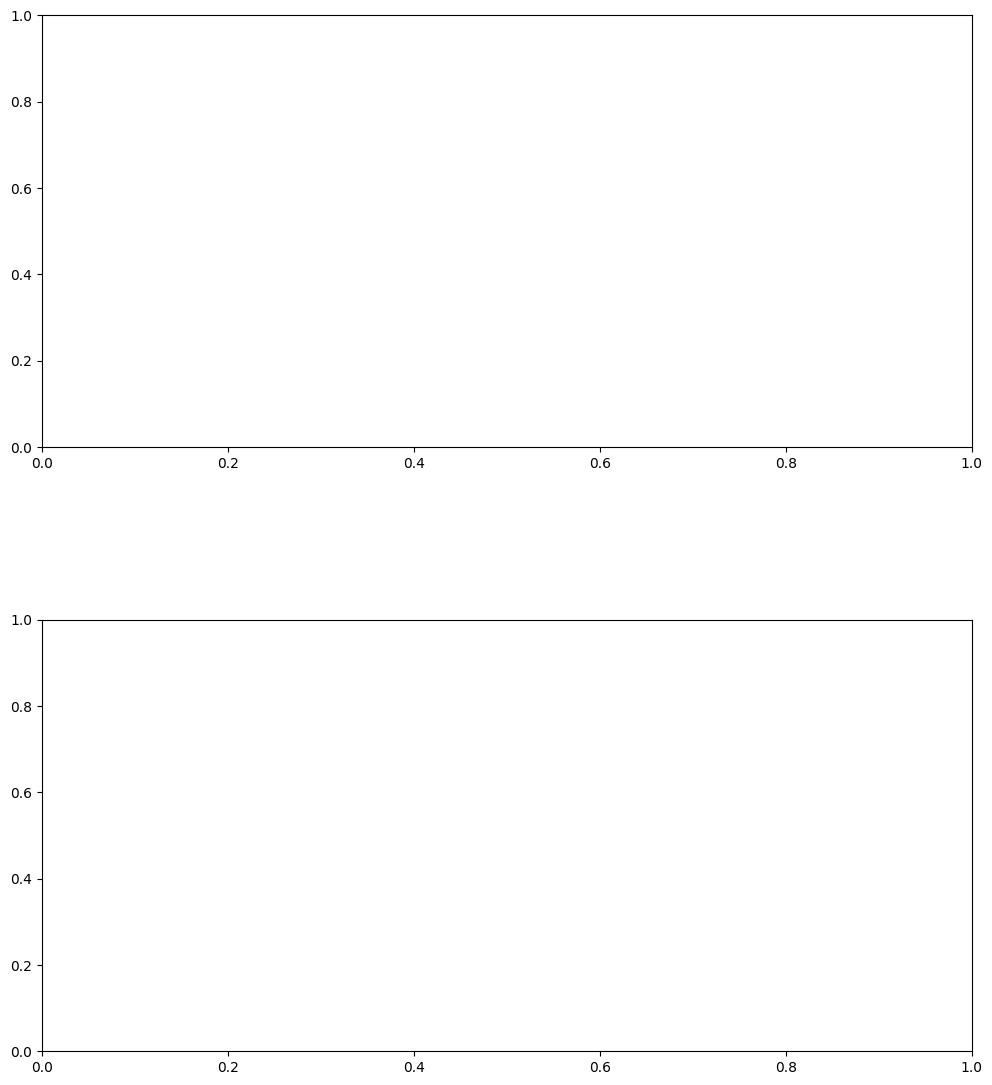

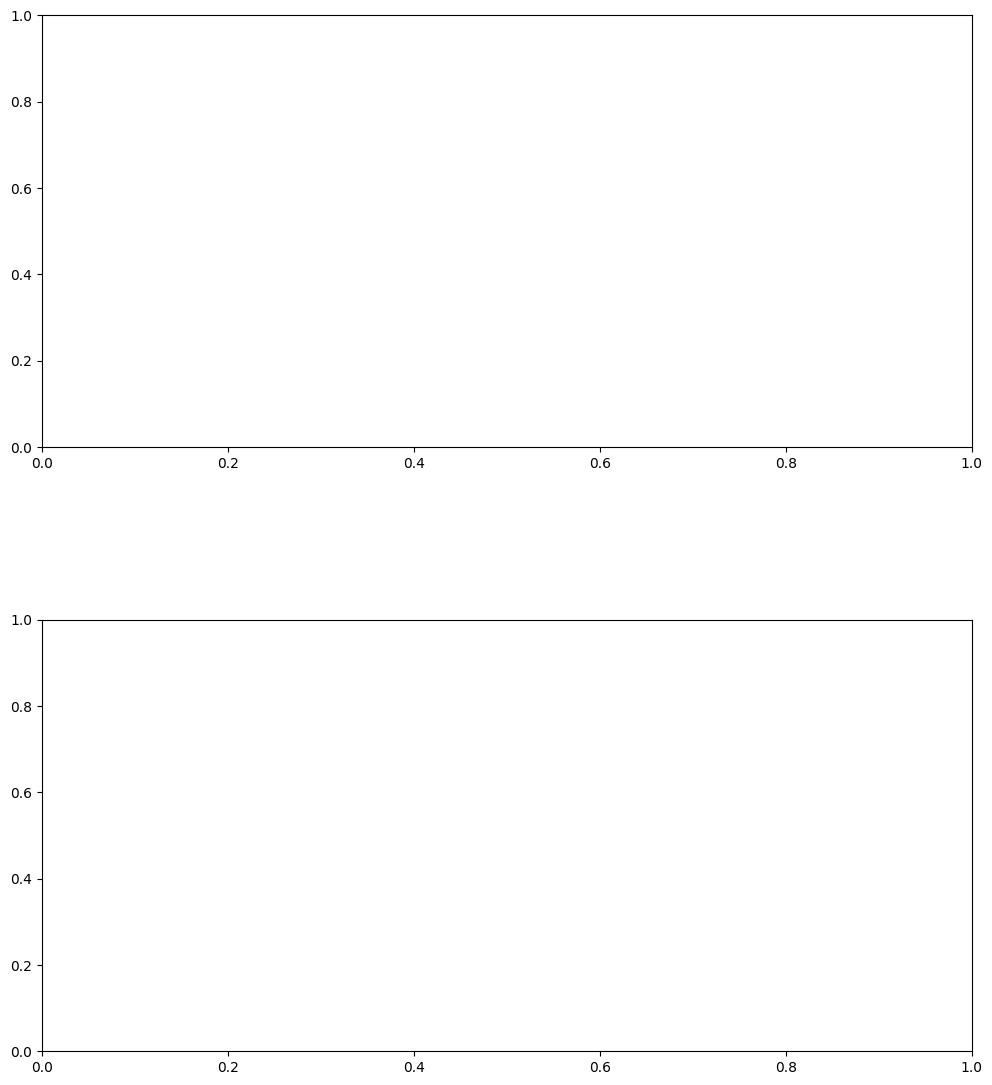

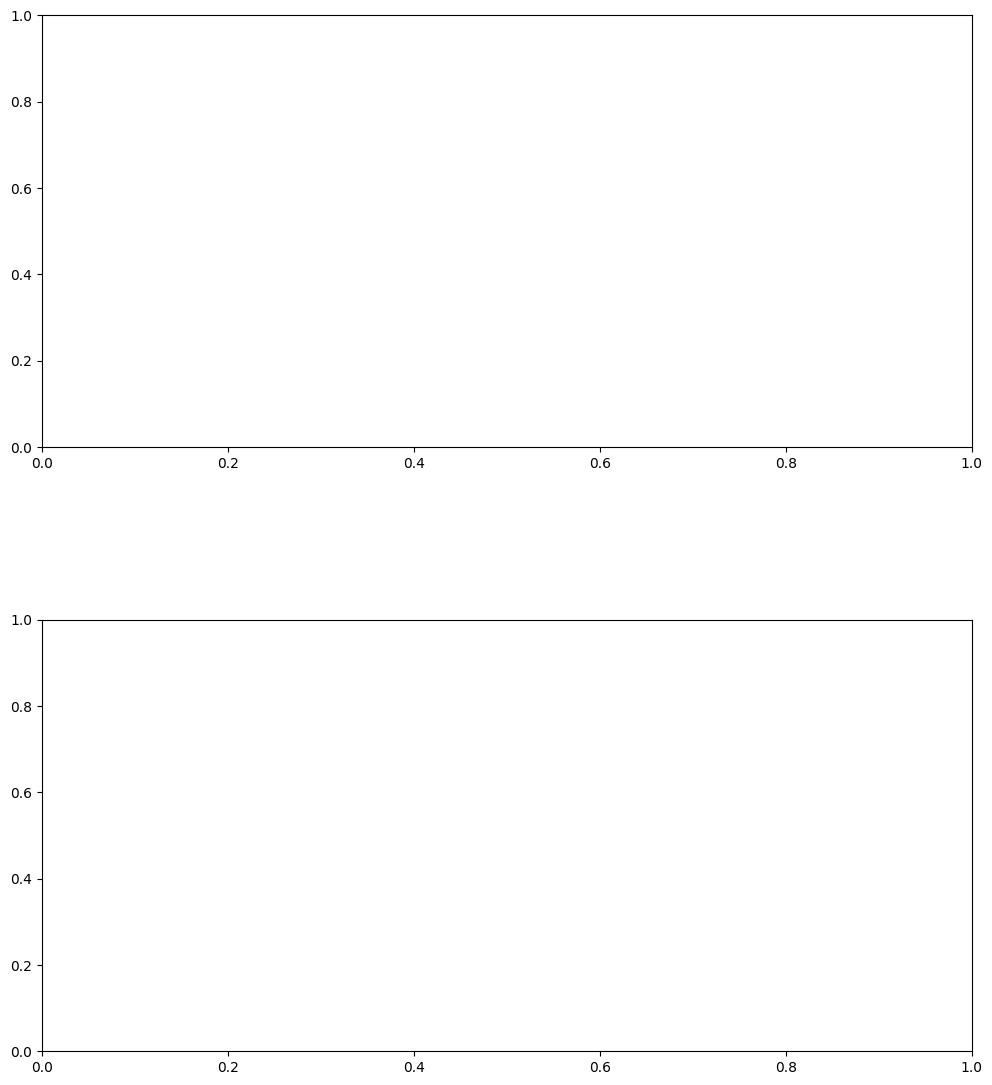

In [10]:
# GPT version 
l_patients = bdd.patient.unique().tolist()
l_patients.sort()
path_patient_pdf = '/home/aura-fabien/SizeIT/Datas/Seizure_images/'

for patient in l_patients:

    obj_patient = Patient(patient)
    nb_sz = obj_patient.nb_sz
    str_sz_type = ", ".join(obj_patient.l_sz_type)
    str_sz_type_multiligne = str_sz_type.replace(", ", "\n")
    pdf_path = path_patient_pdf + f"Patient_{patient}_all_sz.pdf"

    # Désactive l'affichage automatique
    plt.ioff()

    with PdfPages(pdf_path) as pdf:

        # =========================
        # PAGE 1 : résumé texte
        # =========================
        fig_text = plt.figure(figsize=(12, 14))
        fig_text.patch.set_facecolor("white")

        fig_text.text(
            0.5, 0.75,
            f"RAPPORT PATIENT {patient}",
            ha="center",
            fontsize=20,
            weight="bold"
        )

        fig_text.text(
            0.2, 0.50,
            f"Nombre de crises enregistrées : {nb_sz}\n\n"
            f"Durée moyenne des crises : {obj_patient.duration_mean:.1f} s\n\n"
            f"Types de crises : {str_sz_type_multiligne}",
            fontsize=18
        )

        pdf.savefig(fig_text)
        plt.close(fig_text)

        # =========================
        # PAGES SUIVANTES : chaque crise
        # =========================
        for no_sz in range(nb_sz):
            try:
                fig, axes = plt.subplots(2, 1, figsize=(12, 14))
                fig.subplots_adjust(top=0.85, hspace=0.4)

                SZ = obj_patient.bdd["obj_seizure"].iloc[no_sz]
                df_data_acc = SZ.get_data_acc()
                df_data_ecg = SZ.get_data_ecg()
                df_graf_acc = get_df_sz(df_data_acc, SZ.debut, SZ.duree, 10)
                df_graf_ecg = get_df_sz(df_data_ecg, SZ.debut, SZ.duree, 10)

                pdf_plot_graf_acc(axes[0], df_graf_acc, 10, SZ)
                pdf_plot_graf_ecg(axes[1], df_graf_ecg)

                fig.text(
                    0.02, 0.95,
                    f"Patient: {patient}\n"
                    f"Crise no : {no_sz+1}\n"
                    f"Durée moyde la crise: {SZ.duree:.1f} s\n"
                    f"Type de crise: {SZ.sz_type}",
                    ha="left", va="top",
                    fontsize=16,
                    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.3")
                )

                pdf.savefig(fig, facecolor="white")
                plt.close(fig)

            except Exception as e:
                print(f"Erreur crise {no_sz} : {e}, patient : {patient}")
                continue

    print(f"PDF sauvegardé pour le patient {patient} : {pdf_path}")

In [16]:
# from IPython.display import display

# display(IFrame("test_pdf.pdf", 800, 600))

In [11]:
import shutil
from pathlib import Path

source_dir = Path(path_patient_pdf)
target_dir = Path("/data/seize-it-analysis")

target_dir.mkdir(parents=True, exist_ok=True)

for file_path in source_dir.iterdir():
    if file_path.is_file():  # ignore les sous-dossiers
        shutil.copy(file_path, target_dir / file_path.name)

print("Tous les fichiers ont été copiés !")

Tous les fichiers ont été copiés !


In [29]:
os.listdir('/data/seize-it-analysis')

['Patient_2_all_sz.pdf', 'Patient_1_all_sz.pdf']

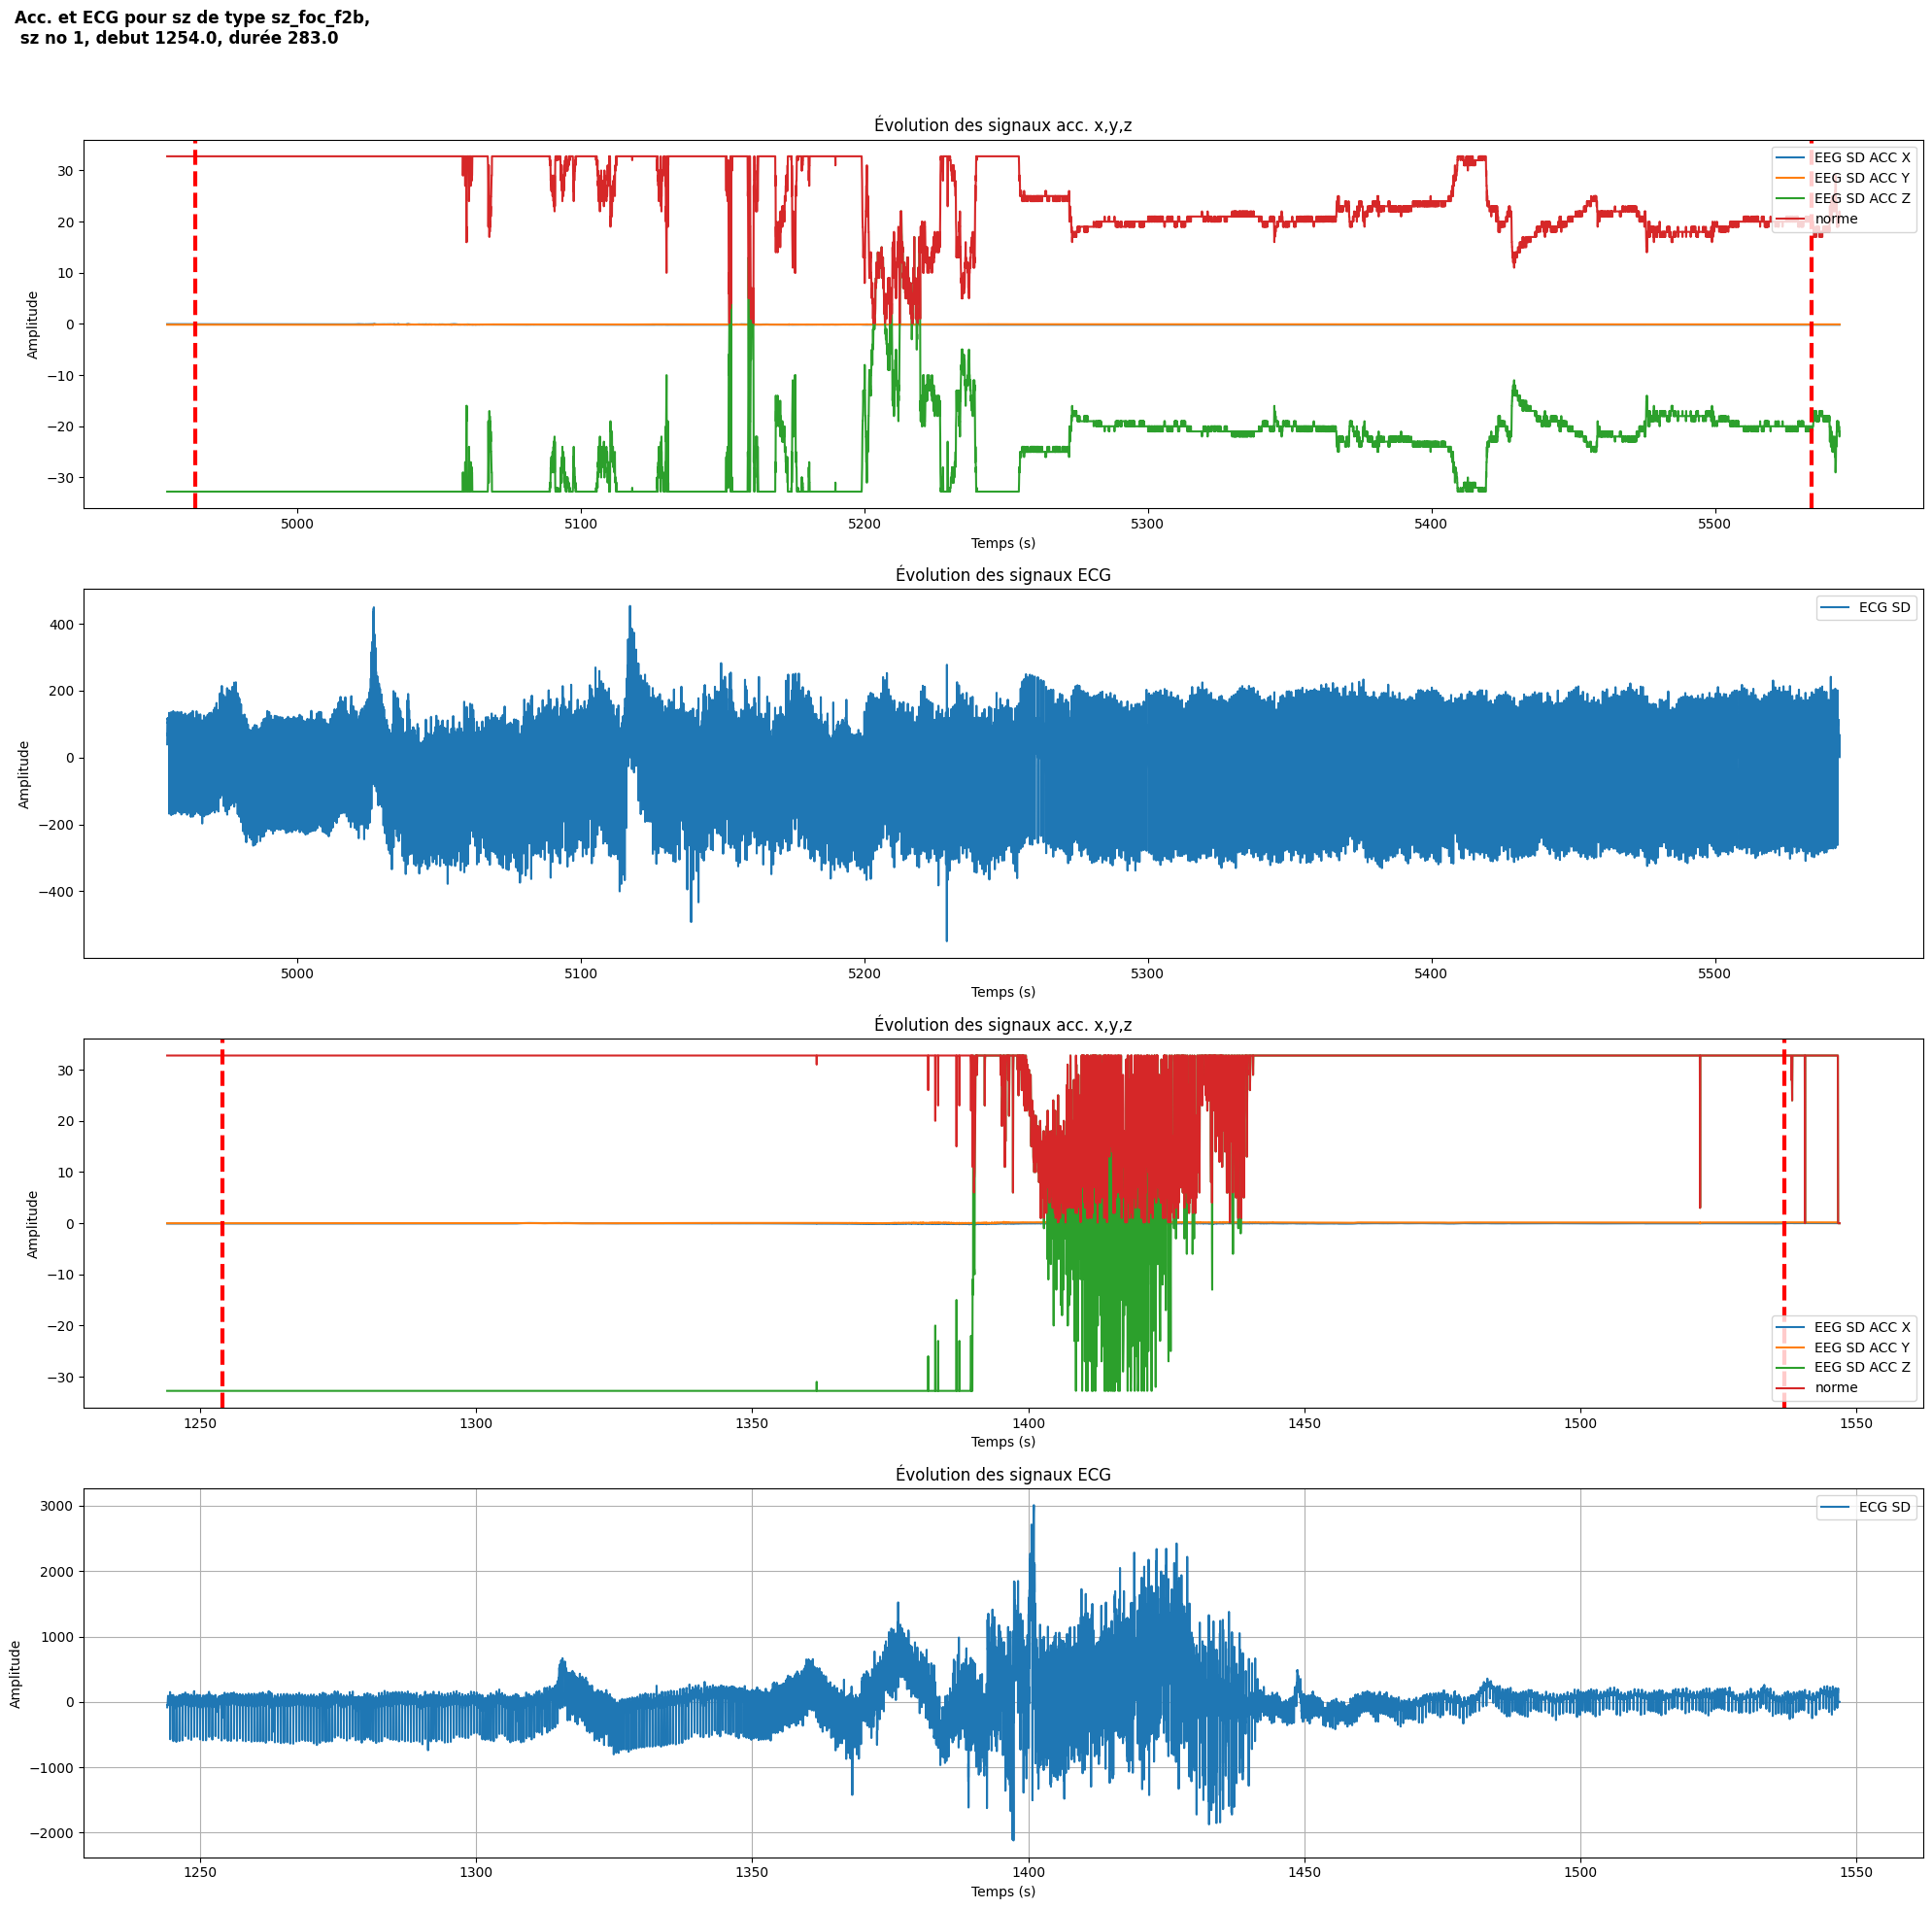

In [ ]:
# def plot_all_patient_crises(patient,bdd):

df_patient = bdd[bdd.patient == patient]
nb_sz = len(df_patient)
overlap = 10
plt.close("all")
fig, axes = plt.subplots(2 * nb_sz, 1, figsize=(20,20 * nb_sz),squeeze=False)
axes = axes.flatten()

for no_sz in range(nb_sz):
    SZ = df_patient["obj_seizure"].iloc[no_sz]
    df_data_acc = SZ.get_data_acc() # get_df_acc(SZ.path_acc)
    df_data_ecg = SZ.get_data_ecg() # get_df_ecg(SZ.path_ecg)
    df_graf_acc = get_df_sz(df_data_acc,SZ.debut,SZ.duree,overlap)
    df_graf_ecg = get_df_sz(df_data_ecg,SZ.debut,SZ.duree,overlap)
    plot_graf_acc(axes[2*no_sz], df_graf_acc,10)
    plot_graf_ecg(axes[2*no_sz + 1], df_graf_ecg)

    
# plt.tight_layout()

fig.suptitle(f"Acc. et ECG pour sz de type {SZ.sz_type}, \n sz no {no_sz}, debut {SZ.debut}, durée {SZ.duree} ",
    x=0.01,          # position horizontale (0 = gauche, 1 = droite)
    ha="left",
    fontsize=12,        # taille de police
    fontweight="bold")
fig.set_size_inches(20,10 * nb_sz)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()   



In [12]:
# On choisis un type de crise
sz_type_graf = l_sz_type[2] 
print(f'crises type : {dict_evt_type['Levels'][sz_type_graf]}')
df_all_sz_of_a_type = get_df_one_sz_type(sz_type_graf)
print(f'{sz_type_graf}, nb sz : {len(df_all_sz_of_a_type)}')

crises type : Focal onset seizure that propagates to a bilateral tonic–clonic seizure
sz_foc_f2b, nb sz : 55


In [ ]:
# Nom du répertoire ou sauver les features acc. déjà calculés :
os.listdir('/data2/datasets/detect-teppe-v2/movesense-data-derived/feat-acc/')
os.listdir('/data/seize-it-analysis/') 


[]

[]